In [1]:
# Ocean Heat Budget Analyses in the Antarctica continental shelf (WAOM)

# Fabio B Dias - 20 August 2024

# using mask of longitudinal(+latitudinal in the Ant.Penins)-bins created by 
# - WAOM10(4/4_notides/2)extend_shflim_S_0.25Q_OHB_shelf_budget_closure.ipynb
# to integrated over regions.
# Using mask for cont. shelf, land and ice shelf cavities, we
# can separate the heat tendency in each region due to individual
# processes (e.g. advection, diffusion, sfc fluxes)

## loading saved netcdf with each component of RHS heat budget eqn., 
# integrated horizontally & vertically.
# 
#waom_notebook/OHB_shelf/OHB_closure/WAOM10_OHB_[hadv/vadv/hdiff/vdiff]_regional_using_lonlat_masks[].py
# _iceshelf refers to only int. within ice shelf cavities of each subsector


In [2]:
# read nc output from WAOM 10km run

import xarray as xr
import pandas as p
import numpy as np
import numpy.ma as ma
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib as mpl
# mpl.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.dates as dates
from matplotlib.ticker import NullFormatter
from matplotlib.colors import LinearSegmentedColormap   # for custom colormaps

import matplotlib.ticker as mticker
from cartopy.mpl.gridliner import LONGITUDE_FORMATTER, LATITUDE_FORMATTER

from datetime import datetime, timedelta

from netCDF4 import Dataset
from netCDF4 import num2date, date2num
from matplotlib.ticker import NullFormatter
from matplotlib.colors import LinearSegmentedColormap   # for custom colormaps

import gsw
import cmocean

import pyresample

from dask.distributed import Client
import logging
import warnings
warnings.filterwarnings('ignore')

In [3]:
client = Client(threads_per_worker=1, memory_limit=0, silence_logs=logging.ERROR)
print(client)

<Client: 'tcp://127.0.0.1:36687' processes=12 threads=12>


In [4]:
fig_path = '/g/data/gv90/fbd581/ROMS/postprocessing/figs/OHB_shelf/'

In [5]:
%%time
    
    # using xr.open_mfdataset
    
    vars2drop = ["ubar","vbar","w","Hsbl","Hbbl","swrad"]
    
    ds = xr.open_mfdataset(paths="/g/data/gv90/fbd581/ROMS/OUTPUT/waom10extend_shflim_S_0.25Q/output_20yr_diag_daily/ocean_avg_00*.nc" , chunks={'eta_rho': '200MB'}, parallel=bool, drop_variables=vars2drop, decode_times=False) # , concat_dim="ocean_time"
    
    m = ds.variables["m"]
    time_avg = ds.variables["ocean_time"] 
    ice_draft = ds.variables["zice"]
    
    mask_zice = ma.masked_where(ice_draft < 0, np.ones(ice_draft.shape))
    mask_outice = ma.masked_where(ice_draft >= 0, np.ones(ice_draft.shape))
    
    print("Vtransform=2")
    #  New formulation (Vtransform(ng) = 2):
    #
    #         z_w(x,y,s,t) = zeta(x,y,t) + [zeta(x,y,t)+ h(x,y)] * Zo_w
    #                 Zo_w = [hc * s(k) + C(k) * h(x,y)] / [hc + h(x,y)]
    # hwater = ds.h- abs(ds.zice) # replace ds.h for hwater below
    # Zo_rho = (ds.hc * ds.s_rho + ds.Cs_r * hwater) / (ds.hc + hwater)
    # z_rho = ds.zeta + (ds.zeta + hwater) * Zo_rho 
    
    # Zo_w = (ds.hc * ds.s_w + ds.Cs_w * hwater) / (ds.hc + hwater)
    # z_w = ds.zeta + (ds.zeta + hwater) * Zo_w 
    
    dg = xr.open_dataset("/g/data/gv90/fbd581/ROMS/waom10_frc/waom10extend_grd.nc")
    
    lat_rho = dg.variables["lat_rho"]
    lon_rho = dg.variables["lon_rho"]
    lat_u = dg.variables["lat_u"]
    lon_u = dg.variables["lon_u"]
    lat_v = dg.variables["lat_v"]
    lon_v = dg.variables["lon_v"]
    pm = dg.variables["pm"]
    pn = dg.variables["pn"]
    h = dg.variables["h"]
    zice = dg.variables["zice"]
    
    ds.coords['lat_rho']=lat_rho.transpose() # put lat_rho into ds dataset
    ds.coords['lon_rho']=lon_rho.transpose() # put lon_rho into ds dataset
    ds = ds.set_coords(['Cs_r', 'Cs_w', 'hc', 'h', 'Vtransform'])
    
    ds.close()
    dg.close()
    
    # calculate surface sigma_theta (potential density)
    # sigma_t_sfc = gsw.rho(salt[:,-1,:,:],temp[:,-1,:,:],0) - 1000
    area=np.divide(1,pm*pn)

    # Z_w = z_w.transpose('ocean_time','s_w','eta_rho','xi_rho')
    # print(z_w.shape, Z_w.shape)
    # dz = np.diff(Z_w,axis=1)

Vtransform=2
CPU times: user 24.4 s, sys: 11.4 s, total: 35.8 s
Wall time: 1min 3s


In [6]:
du = xr.open_mfdataset(paths="/g/data/gv90/fbd581/ROMS/waom4_frc/waom4extend_sustr.nc" , chunks={'eta_rho': '200MB'}, parallel=bool, drop_variables=vars2drop, decode_times=False)
sustr = du.sustr
du.close()

dv = xr.open_mfdataset(paths="/g/data/gv90/fbd581/ROMS/waom4_frc/waom4extend_svstr.nc" , chunks={'eta_rho': '200MB'}, parallel=bool, drop_variables=vars2drop, decode_times=False)
svstr = dv.svstr
dv.close()

In [7]:
%%time

# load waom4 3D temp field to plot some maps
# path_ECCO2_4km = '/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/ocean_avg_00*.nc'

# ds = xr.open_mfdataset(paths='/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_yr10_diag_daily/ocean_avg_00*.nc')#, chunks={'eta_rho': '200MB'}, parallel=True, decode_times=False)
# ds = xr.open_mfdataset(paths='/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/ocean_avg_00*.nc~')#, chunks={'eta_rho': '200MB'}, parallel=True, decode_times=False)
ds = xr.open_mfdataset(paths='/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_01-20yr/ocean_avg_0010.nc')#, chunks={'eta_rho': '200MB'}, parallel=True, decode_times=False)
salt3d_4km= ds.salt
temp3d_4km= ds.temp
u3d_4km= ds.variables["u"]
v3d_4km= ds.variables["v"]
melt_4km= ds.m
shflux_4km= ds.shflux

ds = ds.set_coords(['Cs_r', 'Cs_w', 'hc', 'h', 'Vtransform'])
# calc dz:
hwater = ds.h -abs(ds.zice) # replace ds.h for hwater below
Zo_rho = (ds.hc * ds.s_rho + ds.Cs_r * hwater) / (ds.hc + hwater)
z_rho3d_4km = ds.zeta + (ds.zeta + hwater) * Zo_rho -abs(ds.zice)
del Zo_rho
ds.close()

 # read grid file for lon/lat coordinates
dg = xr.open_dataset("/g/data/gv90/fbd581/ROMS/waom4_frc/waom4extend_grd.nc")
angle_4km= dg.variables["angle"]
lat_rho_4km= dg.variables["lat_rho"]
lon_rho_4km = dg.variables["lon_rho"]
lat_u_4km= dg.variables["lat_u"]
lon_u_4km = dg.variables["lon_u"]
lat_v_4km= dg.variables["lat_v"]
lon_v_4km = dg.variables["lon_v"]
pm_4km = dg.variables["pm"]
pn_4km = dg.variables["pn"]
zice_4km = dg.variables["zice"]
h_4km = dg.variables["h"]
dg.close()
print('Print lon/lat_rho shapes',lon_rho_4km.shape, lat_rho_4km.shape)
print('Print lon/lat_rho shapes',lon_rho_4km[0:-1,0:-1].shape, lat_rho_4km[0:-1,0:-1].shape)

# load along 1500m and CF WAOM4 variables:
tmp_files_dir = '/g/data/gv90/fbd581/ROMS/postprocessing/cross_contour_tmp/'

expt = 'WAOM4'

ds = xr.open_dataset(tmp_files_dir + expt + '_temp_1500m_daily_v3')
temp_4km = ds.variables["__xarray_dataarray_variable__"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_salt_1500m_daily_v3')
salt_4km = ds.variables["__xarray_dataarray_variable__"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_z_rho_1500m_daily_v4') 
z_rho_4km = ds.variables["__xarray_dataarray_variable__"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_dist_along_1500m_v3')
dist_along_4km = ds.variables["__xarray_dataarray_variable__"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_lon_along_1500m_v3')
lon_along_4km = ds.variables["one"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_lat_along_1500m_v3')
lat_along_4km = ds.variables["two"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_temp_CF_daily_v3')
temp_4km_CF = ds.variables["__xarray_dataarray_variable__"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_salt_CF_daily_v3')
salt_4km_CF = ds.variables["__xarray_dataarray_variable__"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_z_rho_CF_daily_v4') 
z_rho_4km_CF = ds.variables["__xarray_dataarray_variable__"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_dist_along_CF_v3')
dist_along_4km_CF = ds.variables["__xarray_dataarray_variable__"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_lon_along_CF_v3')
lon_along_4km_CF = ds.variables["one"]
ds.close()

ds = xr.open_dataset(tmp_files_dir + expt + '_lat_along_CF_v3')
lat_along_4km_CF = ds.variables["two"]
ds.close()

# define along_contour axis with same length for both resolutions:
[dist_along_axis_4km, Zaxis_4km] = np.meshgrid(dist_along_4km, np.arange(0,31))

[dist_along_axis_4km_CF, Zaxis_4km_CF] = np.meshgrid(dist_along_4km_CF, np.arange(0,31))

## load contours for plotting on top of Maps:
files_path = '/g/data/gv90/fbd581/ROMS/postprocessing/cross_contour_tmp/'
contour_masked_above_4km = np.load(files_path + 'WAOM4_contour_masked_above_1500m', allow_pickle=True)
contour_masked_above_CF_4km = np.load(files_path + 'WAOM4_contour_masked_above_CF_v3', allow_pickle=True)

# 2) calculate OHC depth-integrated:
Tf = -3.534879684448242
rho0 = 1035 # kg. m-3
Cp = 3992.1 # J.kg-1.degC-1
temp3d_4km.load()
temp3d_4km_K = temp3d_4km-Tf
temp3d_vint_4km_annual = temp3d_4km_K.sum('s_rho').mean('ocean_time')*rho0*Cp
print(temp3d_vint_4km_annual.shape)

# 3) melt fields
melt_4km.load()

Print lon/lat_rho shapes (1400, 1575) (1400, 1575)
Print lon/lat_rho shapes (1399, 1574) (1399, 1574)
(1400, 1575)
CPU times: user 8 s, sys: 14.2 s, total: 22.2 s
Wall time: 32.7 s


<xarray.DataArray 'm' (ocean_time: 12, eta_rho: 1400, xi_rho: 1575)> Size: 106MB
array([[[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
...
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]],

       [[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]], dtype=float32)
Coordinates:
    x_rho       (eta_rho, xi_rho) float64 18MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
    y_rho       (eta_rho, xi_rho) float64 18MB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0
  * ocean_time  (ocean_time) datetime64[ns] 96B 2016-01-14T05:00:00 ... 2016-...
Dimensions without coordinates: eta_rho, xi_rho
Attributes:
    long_name:  time-averaged ice shelf melt rate
    units:      meter second-1
    time:       ocean_time
    field:      melt_rate, scalar, series

In [ ]:
%%time

# read 3 years of daily temp/melt/SHF:
ds = xr.open_mfdataset(paths='/g/data/gv90/fbd581/ROMS/OUTPUT/waom4extend_shflim_S_0.25Q/output_yr1[0-2]_diag_daily/ocean_avg_*.nc')#, chunks={'eta_rho': '200MB'}, parallel=True, decode_times=False)
temp3d_4km= ds.temp
melt_4km= ds.m
shflux_4km= ds.shflux

ds = ds.set_coords(['Cs_r', 'Cs_w', 'hc', 'h', 'Vtransform'])
# calc dz:
hwater = ds.h -abs(ds.zice) # replace ds.h for hwater below
Zo_rho = (ds.hc * ds.s_rho + ds.Cs_r * hwater) / (ds.hc + hwater)
z_rho3d_4km = ds.zeta + (ds.zeta + hwater) * Zo_rho  -abs(ds.zice)
del Zo_rho
ds.close()

In [ ]:
# create monthly climatology:
temp3d_4km_clim = temp3d_4km.groupby("ocean_time.month").mean('ocean_time')
z_rho3d_4km_clim = z_rho3d_4km.groupby("ocean_time.month").mean('ocean_time')
melt_4km_clim = melt_4km.groupby("ocean_time.month").mean('ocean_time')
shflux_4km_clim = shflux_4km.groupby("ocean_time.month").mean('ocean_time')

In [ ]:
contour_masked_above = np.load(files_path + 'WAOM10_contour_masked_above_1500m_v3', allow_pickle=True)
contour_masked_above_CF = np.load(files_path + 'WAOM10_contour_masked_above_CF_v3', allow_pickle=True)

mask_shelf = ma.masked_where(contour_masked_above==-1000, np.ones(h.shape))
mask_iceshelf = ma.masked_where(contour_masked_above_CF!=-1000, np.ones(h.shape))
mask_outiceshelf = ma.masked_where(contour_masked_above_CF==-1000, np.ones(h.shape))

mask_land = ma.masked_where(h_4km<=40, np.ones(h_4km.shape))
mask_zice = ma.masked_where(zice_4km < 0, np.ones(zice_4km.shape))
mask_outice = ma.masked_where(zice_4km >= 0, np.ones(zice_4km.shape))


In [ ]:
# define masks for cavities less_equal than 500m & more than 500m ice draft depth (to separate modes into shallow and deep):

msk_ice_shallow = ma.masked_where(zice_4km<-500, np.ones(zice_4km.shape))
msk_ice_deep = ma.masked_where(zice_4km>=-500, np.ones(zice_4km.shape))


In [ ]:
w4_mask_shelf = ma.masked_where(contour_masked_above_4km==-1000, np.ones(h_4km.shape))
w4_mask_iceshelf = ma.masked_where(contour_masked_above_CF_4km!=-1000, np.ones(h_4km.shape))
w4_mask_outiceshelf = ma.masked_where(contour_masked_above_CF_4km==-1000, np.ones(h_4km.shape))

w4_mask_land = ma.masked_where(h_4km<=40, np.ones(h_4km.shape))
w4_mask_zice = ma.masked_where(zice_4km < 0, np.ones(zice_4km.shape))

### Load masks lon/lat bins:

In [ ]:
area_sum = area.sum('eta_rho').sum('xi_rho')

In [ ]:
# define constants:
rho0=1035
Cp=3992.1
# Tf = -1.95 # degC
Tf =  -3.534879684448242

In [ ]:

dm = xr.open_dataset('/g/data/gv90/fbd581/ROMS/postprocessing/cross_contour_tmp/WAOM4_masked_lonlatBins_v2.nc')
mask_LonBins_4km = dm.variables['__xarray_dataarray_variable__']
dm.close()



In [ ]:
plt.pcolormesh(mask_shelf*mask_iceshelf)
plt.colorbar()

### load pre-saved heat budget components

#### waom4

In [ ]:
print(files_path+ "WAOM4_OHB_lonlatbins_temp_hadv_vint_daily.nc")

In [ ]:
# load basal melting

file = files_path + "WAOM4_OHB_lonlatbins-v2_melt_daily_v2.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4a_bmelt = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_melt_daily_v2_yr11.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4b_bmelt = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_melt_daily_v2_yr12.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4c_bmelt = ds['__xarray_dataarray_variable__']
ds.close()

In [ ]:
# basal melting divided into shallow vs deep (only done for WAOM4 so far):

file = files_path + "WAOM4_OHB_lonlatbins-v2_melt_shallow_daily_v2.nc"
ds = xr.open_mfdataset(paths=file, parallel=bool)
w4a_bmelt_shallow = ds['__xarray_dataarray_variable__']
lon_bins = ds.variables['lon_bins']

ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_melt_deep_daily_v2.nc"
ds = xr.open_mfdataset(paths=file, parallel=bool)
w4a_bmelt_deep = ds['__xarray_dataarray_variable__']
ds.close()


In [ ]:
# basal melting divided into shallow vs deep (only done for WAOM4 so far):

file = files_path + "WAOM4_OHB_lonlatbins-v2_melt_shallow_daily_v2_yr11.nc"
ds = xr.open_mfdataset(paths=file, parallel=bool)
w4b_bmelt_shallow = ds['__xarray_dataarray_variable__']
lon_bins = ds.variables['lon_bins']

ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_melt_deep_daily_v2_yr11.nc"
ds = xr.open_mfdataset(paths=file, parallel=bool)
w4b_bmelt_deep = ds['__xarray_dataarray_variable__']
ds.close()


In [ ]:
# basal melting divided into shallow vs deep (only done for WAOM4 so far):

file = files_path + "WAOM4_OHB_lonlatbins-v2_melt_shallow_daily_v2_yr12.nc"
ds = xr.open_mfdataset(paths=file, parallel=bool)
w4c_bmelt_shallow = ds['__xarray_dataarray_variable__']
lon_bins = ds.variables['lon_bins']

ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_melt_deep_daily_v2_yr12.nc"
ds = xr.open_mfdataset(paths=file, parallel=bool)
w4c_bmelt_deep = ds['__xarray_dataarray_variable__']
ds.close()


#### year 10

In [ ]:
file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hadv_vint_daily.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4a_hadv = ds['__xarray_dataarray_variable__']
w4_ocean_time = ds.ocean_time
w4_lon_bins = ds.lon_bins
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hdiff_vint_daily.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4a_hdiff = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vadv_vint_daily.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4a_vadv = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vdiff_vint_daily.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4a_vdiff = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hadv_vint_daily_iceshelf.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4a_hadv_is = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hdiff_vint_daily_iceshelf.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4a_hdiff_is = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vadv_vint_daily_iceshelf.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4a_vadv_is = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vdiff_vint_daily_iceshelf.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4a_vdiff_is = ds['__xarray_dataarray_variable__']
ds.close()

#### year 11

In [ ]:
file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hadv_vint_daily_yr11.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4b_hadv = ds['__xarray_dataarray_variable__']
w4b_ocean_time = ds.ocean_time
w4b_lon_bins = ds.lon_bins
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hdiff_vint_daily_yr11.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4b_hdiff = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vadv_vint_daily_yr11.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4b_vadv = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vdiff_vint_daily_yr11.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4b_vdiff = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hadv_vint_daily_iceshelf_yr11.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4b_hadv_is = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hdiff_vint_daily_iceshelf_yr11.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4b_hdiff_is = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vadv_vint_daily_iceshelf_yr11.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4b_vadv_is = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vdiff_vint_daily_iceshelf_yr11.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4b_vdiff_is = ds['__xarray_dataarray_variable__']
ds.close()

#### year 12

In [ ]:
file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hadv_vint_daily_yr12.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4c_hadv = ds['__xarray_dataarray_variable__']
w4c_ocean_time = ds.ocean_time
w4c_lon_bins = ds.lon_bins
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hdiff_vint_daily_yr12.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4c_hdiff = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vadv_vint_daily_yr12.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4c_vadv = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vdiff_vint_daily_yr12.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4c_vdiff = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hadv_vint_daily_iceshelf_yr12.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4c_hadv_is = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hdiff_vint_daily_iceshelf_yr12.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4c_hdiff_is = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vadv_vint_daily_iceshelf_yr12.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4c_vadv_is = ds['__xarray_dataarray_variable__']
ds.close()

file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_vdiff_vint_daily_iceshelf_yr12.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
w4c_vdiff_is = ds['__xarray_dataarray_variable__']
ds.close()

In [ ]:
w4a_net = w4a_hadv + w4a_vadv + w4a_hdiff + w4a_vdiff
w4a_net_is = w4a_hadv_is + w4a_vadv_is + w4a_hdiff_is + w4a_vdiff_is

w4b_net = w4b_hadv + w4b_vadv + w4b_hdiff + w4b_vdiff
w4b_net_is = w4b_hadv_is + w4b_vadv_is + w4b_hdiff_is + w4b_vdiff_is

w4c_net = w4c_hadv + w4c_vadv + w4c_hdiff + w4c_vdiff
w4c_net_is = w4c_hadv_is + w4c_vadv_is + w4c_hdiff_is + w4c_vdiff_is


In [ ]:
## yr10-12 concatenated:
file = files_path + "WAOM4_OHB_lonlatbins-v2_temp_hadv_vint_daily_iceshelf_yr10-12.nc"
ds = xr.open_mfdataset(paths=file, chunks={'eta_rho': '200MB'}, parallel=bool)
# w4c_hadv = ds.variables['__xarray_dataarray_variable__']
# w4c_ocean_time = ds.ocean_time
# w4c_lon_bins = ds.lon_bins
# ds.close()

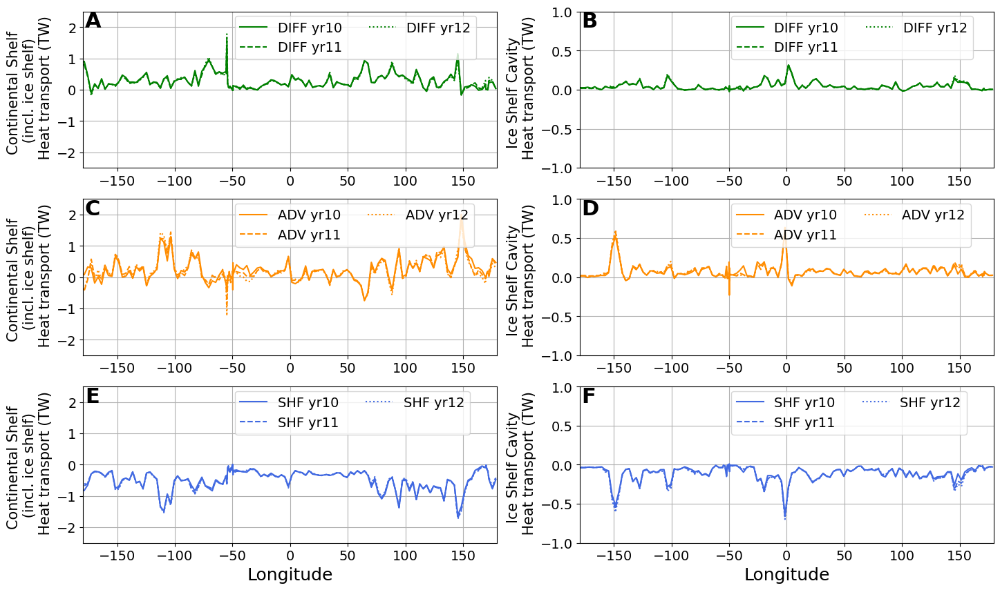

In [28]:
# repeating Fig. A1 but excluding ice shelf cavity from the shelf:

fig = plt.figure(figsize=(17,10))

ax1 = fig.add_subplot(3,2,1)
ax1.plot(w4a_lon_bins,w4a_hdiff.mean('ocean_time')*1e-12,'-',color='green',label='DIFF yr10', alpha=1)
ax1.plot(w4a_lon_bins,w4b_hdiff.mean('ocean_time')*1e-12,'--',color='green',label='DIFF yr11', alpha=1)
ax1.plot(w4a_lon_bins,w4c_hdiff.mean('ocean_time')*1e-12,':',color='green',label='DIFF yr12', alpha=1)
ax1.legend(bbox_to_anchor=(0.35, .65), loc='lower left',ncol=2, fontsize=14)
ax1.set_xlim(-179.5,179.5)
ax1.set_ylim(-2.5,2.5)
ax1.grid('off')
ax1.set_ylabel('Continental Shelf \n (incl. ice shelf) \n Heat transport (TW)',fontsize=15)
ax1.tick_params(axis='x',labelsize=14)
ax1.tick_params(axis='y',labelsize=14)
ax1.text(-178,2.,'A',fontsize=22,weight="bold")

ax2 = fig.add_subplot(3,2,3)
ax2.plot(w4a_lon_bins,w4a_hadv.mean('ocean_time')*1e-12,'-',color='darkorange',label='ADV yr10', alpha=1)
ax2.plot(w4a_lon_bins,w4b_hadv.mean('ocean_time')*1e-12,'--',color='darkorange',label='ADV yr11', alpha=1)
ax2.plot(w4a_lon_bins,w4c_hadv.mean('ocean_time')*1e-12,':',color='darkorange',label='ADV yr12', alpha=1)
ax2.legend(bbox_to_anchor=(0.35, .65), loc='lower left',ncol=2, fontsize=14)
ax2.set_xlim(-179.5,179.5)
ax2.set_ylim(-2.5,2.5)
ax2.grid('off')
ax2.set_ylabel('Continental Shelf \n (incl. ice shelf) \n Heat transport (TW)',fontsize=15)
ax2.tick_params(axis='x',labelsize=14)
ax2.tick_params(axis='y',labelsize=14)
ax2.text(-178,2.,'C',fontsize=22,weight="bold")

ax3 = fig.add_subplot(3,2,5)
ax3.plot(w4a_lon_bins,w4a_vdiff.mean('ocean_time')*1e-12,'-',color='royalblue',label='SHF yr10', alpha=1)
ax3.plot(w4a_lon_bins,w4b_vdiff.mean('ocean_time')*1e-12,'--',color='royalblue',label='SHF yr11', alpha=1)
ax3.plot(w4a_lon_bins,w4c_vdiff.mean('ocean_time')*1e-12,':',color='royalblue',label='SHF yr12', alpha=1)
ax3.legend(bbox_to_anchor=(0.35, .65), loc='lower left',ncol=2, fontsize=14)
ax3.set_xlim(-179.5,179.5)
ax3.set_ylim(-2.5,2.5)
ax3.grid('off')
ax3.set_ylabel('Continental Shelf \n (incl. ice shelf) \n Heat transport (TW)',fontsize=15)
ax3.set_xlabel('Longitude', fontsize=18)
ax3.tick_params(axis='x',labelsize=14)
ax3.tick_params(axis='y',labelsize=14)
ax3.text(-178,2.,'E',fontsize=22,weight="bold")

## ice shelf cavity:
ax1 = fig.add_subplot(3,2,2)
ax1.plot(w4a_lon_bins,w4a_hdiff_is.mean('ocean_time')*1e-12,'-',color='green',label='DIFF yr10', alpha=1)
ax1.plot(w4a_lon_bins,w4b_hdiff_is.mean('ocean_time')*1e-12,'--',color='green',label='DIFF yr11', alpha=1)
ax1.plot(w4a_lon_bins,w4c_hdiff_is.mean('ocean_time')*1e-12,':',color='green',label='DIFF yr12', alpha=1)
ax1.legend(bbox_to_anchor=(0.35, .65), loc='lower left',ncol=2, fontsize=14)
ax1.set_xlim(-179.5,179.5)
ax1.set_ylim(-1,1)
ax1.grid('off')
ax1.set_ylabel('Ice Shelf Cavity \n Heat transport (TW)',fontsize=15)
ax1.tick_params(axis='x',labelsize=14)
ax1.tick_params(axis='y',labelsize=14)
ax1.text(-178,.8,'B',fontsize=22,weight="bold")

ax2 = fig.add_subplot(3,2,4)
ax2.plot(w4a_lon_bins,w4a_hadv_is.mean('ocean_time')*1e-12,'-',color='darkorange',label='ADV yr10', alpha=1)
ax2.plot(w4a_lon_bins,w4b_hadv_is.mean('ocean_time')*1e-12,'--',color='darkorange',label='ADV yr11', alpha=1)
ax2.plot(w4a_lon_bins,w4c_hadv_is.mean('ocean_time')*1e-12,':',color='darkorange',label='ADV yr12', alpha=1)
ax2.legend(bbox_to_anchor=(0.35, .65), loc='lower left',ncol=2, fontsize=14)
ax2.set_xlim(-179.5,179.5)
ax2.set_ylim(-1,1)
ax2.grid('off')
ax2.set_ylabel('Ice Shelf Cavity \n Heat transport (TW)',fontsize=15)
ax2.tick_params(axis='x',labelsize=14)
ax2.tick_params(axis='y',labelsize=14)
ax2.text(-178,.8,'D',fontsize=22,weight="bold")

ax3 = fig.add_subplot(3,2,6)
ax3.plot(w4a_lon_bins,w4a_vdiff_is.mean('ocean_time')*1e-12,'-',color='royalblue',label='SHF yr10', alpha=1)
ax3.plot(w4a_lon_bins,w4b_vdiff_is.mean('ocean_time')*1e-12,'--',color='royalblue',label='SHF yr11', alpha=1)
ax3.plot(w4a_lon_bins,w4c_vdiff_is.mean('ocean_time')*1e-12,':',color='royalblue',label='SHF yr12', alpha=1)
ax3.legend(bbox_to_anchor=(0.35, .65), loc='lower left',ncol=2, fontsize=14)
ax3.set_xlim(-179.5,179.5)
ax3.set_ylim(-1,1)
ax3.grid('off')
ax3.set_ylabel('Ice Shelf Cavity \n Heat transport (TW)',fontsize=15)
ax3.set_xlabel('Longitude', fontsize=18)
ax3.tick_params(axis='x',labelsize=14)
ax3.tick_params(axis='y',labelsize=14)
ax3.text(-178,.8,'F',fontsize=22,weight="bold")


# # - plot gray shads:
# for ii in np.arange(0,6):
#     Xplt, Yplt = np.meshgrid(w4_lon_bins[sind_subreg[ii]:eind_subreg[ii]], np.arange(-50,50))
#     print(Xplt.shape, Yplt.shape,np.ones((100,len(Xplt[0,:]))).shape)
#     ax1.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
#     ax2.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
#     del Xplt, Yplt
# for ii in np.arange(7,13):
#     Xplt, Yplt = np.meshgrid(w4_lon_bins[sind_subreg[ii]:eind_subreg[ii]], np.arange(-50,50))
#     print(Xplt.shape, Yplt.shape,np.ones((100,len(Xplt[0,:]))).shape)
#     ax1.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
#     ax2.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
#     del Xplt, Yplt
    
name_fig='waom4_lonbin_regional_OHB_wholeshelf_Figure2_SM-yr10-11-12.png'
plt.savefig(fig_path + name_fig, dpi=300, bbox_inches='tight')

### combine years 10, 11 and 12 to produce final figures averaged across years:

In [ ]:
W4_hadv = xr.concat([w4a_hadv, w4b_hadv, w4c_hadv], dim='ocean_time')
W4avg_hadv = W4_hadv.groupby("ocean_time").mean()

W4_hdiff = xr.concat([w4a_hdiff, w4b_hdiff, w4c_hdiff], dim='ocean_time')
W4avg_hdiff = W4_hdiff.groupby("ocean_time").mean()

W4_vadv = xr.concat([w4a_vadv, w4b_vadv, w4c_vadv], dim='ocean_time')
W4avg_vadv = W4_vadv.groupby("ocean_time").mean()

W4_vdiff = xr.concat([w4a_vdiff, w4b_vdiff, w4c_vdiff], dim='ocean_time')
W4avg_vdiff = W4_vdiff.groupby("ocean_time").mean()


In [ ]:
W4_hadv_is = xr.concat([w4a_hadv_is, w4b_hadv_is, w4c_hadv_is], dim='ocean_time')
W4avg_hadv_is = W4_hadv_is.groupby("ocean_time").mean()

W4_hdiff_is = xr.concat([w4a_hdiff_is, w4b_hdiff_is, w4c_hdiff_is], dim='ocean_time')
W4avg_hdiff_is = W4_hdiff_is.groupby("ocean_time").mean()

W4_vadv_is = xr.concat([w4a_vadv_is, w4b_vadv_is, w4c_vadv_is], dim='ocean_time')
W4avg_vadv_is = W4_vadv_is.groupby("ocean_time").mean()

W4_vdiff_is = xr.concat([w4a_vdiff_is, w4b_vdiff_is, w4c_vdiff_is], dim='ocean_time')
W4avg_vdiff_is = W4_vdiff_is.groupby("ocean_time").mean()


In [ ]:
W4_bmelt = xr.concat([w4a_bmelt, w4b_bmelt, w4c_bmelt], dim='ocean_time')
W4avg_bmelt = W4_bmelt.groupby("ocean_time").mean()


In [ ]:
W4_bmelt_shallow = xr.concat([w4a_bmelt_shallow, w4b_bmelt_shallow, w4c_bmelt_shallow], dim='ocean_time')
W4avg_bmelt_shallow = W4_bmelt_shallow.groupby("ocean_time").mean()


In [ ]:
W4_bmelt_deep = xr.concat([w4a_bmelt_deep, w4b_bmelt_deep, w4c_bmelt_deep], dim='ocean_time')
W4avg_bmelt_deep = W4_bmelt_deep.groupby("ocean_time").mean()


In [ ]:
W4avg_net = W4avg_hadv + W4avg_vadv + W4avg_hdiff + W4avg_vdiff
W4avg_net_is = W4avg_hadv_is + W4avg_vadv_is + W4avg_hdiff_is + W4avg_vdiff_is




### Define seasons and time-averaged variables:

In [ ]:
win1=151 #Apr-Nov
win2=335 
sum1=336 #Dec-Mar
sum2=150

In [ ]:
# new attempt responding concern from reviewer #1: (on 25.4.2025)
sind_subreg = [8, 14, 22, 32, 49, 68, 82, 99, 108, 114, 124, 135, 0]
eind_subreg = [12, 21, 27, 39, 67, 78, 91, 107, 113, 118, 129, 141, 6]

names_subreg = ['Sulzberger','Getz','Thwaites-PIG','Bellingshausen','FRIS',
               'Brunt-Fimbul','Queen Maud Land','Amery-West','Shackleton','Totten','Mertz','Ross']#1','Ross2']
max_BM = [3, 2, 1, 2.5, 1, 1, 1, 1,
          3.8, 2, 2, 1, 1]        # max ylim for basal melting plot (vary b/w regions)


In [ ]:
Melt_fac_map=365.25*86400
rho_ice = 916 # https://github.com/kuechenrole/antarctic_melting/blob/master/notebooks/GRL/Susheel_bfrn_depth_structure.ipynb
# Melt_fac = 86400*365.25*rho_ice
Melt_fac=rho_ice*1e-12 # convert to Gigatonne (=1e12 kg)


In [ ]:

dayofmonth = [slice(0,32), slice(32,61), slice(61,93), slice(93,123), slice(123,155), slice(155,184), slice(184,215), 
              slice(215,247), slice(247,277), slice(277,304), slice(304,334), slice(334,365)]

# define limits for maps of each region:

# order is: LonMin, LonMax, LatMin, LatMax
# map_limits=[[-180, -135, -84, -74], # Sulzberger
map_limits=[[-165, -135, -79, -74], # Sulzberger
[-140, -110, -71, -76],             # Getz
[-120, -90, -76, -69],              # PIG-Thwaites
[-100, -17, -83.5, -65],            # Bellingshausen+FRIS
[-100, -17, -83.5, -65],            # Bellingshausen+FRIS
[-15, 15, -73.5, -69],              # Fimbul
[10, 50, -74, -67],                 # Queen Maud Land
[65, 85, -74, -65],                 # Amery
[80, 110, -68.1, -63],              # Shackleton
[110, 135, -68, -63.5],             # Totten
[130,160, -71, -64],              # Mertz 
[-205,-160, -84.2, -68]]              # Ross

In [ ]:
# WAOM4:
W4avg_net_sumA=W4avg_net.isel(ocean_time=slice(0,sum2))
W4avg_net_sumB=W4avg_net.isel(ocean_time=slice(sum1,-1))
W4avg_net_SUM_A=xr.DataArray(W4avg_net_sumA)
W4avg_net_SUM_B=xr.DataArray(W4avg_net_sumB)
W4avg_net_summer = xr.concat((W4avg_net_SUM_A,W4avg_net_SUM_B), 'ocean_time')

W4avg_net_is_sumA=W4avg_net_is.isel(ocean_time=slice(0,sum2))
W4avg_net_is_sumB=W4avg_net_is.isel(ocean_time=slice(sum1,-1))
W4avg_net_is_SUM_A=xr.DataArray(W4avg_net_is_sumA)
W4avg_net_is_SUM_B=xr.DataArray(W4avg_net_is_sumB)
W4avg_net_is_summer = xr.concat((W4avg_net_is_SUM_A,W4avg_net_is_SUM_B), 'ocean_time')

W4avg_bmelt_sumA=W4avg_bmelt.isel(ocean_time=slice(0,sum2))
W4avg_bmelt_sumB=W4avg_bmelt.isel(ocean_time=slice(sum1,-1))
W4avg_bmelt_SUM_A=xr.DataArray(W4avg_bmelt_sumA)
W4avg_bmelt_SUM_B=xr.DataArray(W4avg_bmelt_sumB)
W4avg_bmelt_summer = xr.concat((W4avg_bmelt_SUM_A,W4avg_bmelt_SUM_B), 'ocean_time')

In [ ]:
# WAOM4:
W4avg_hadv_sumA=W4avg_hadv.isel(ocean_time=slice(0,sum2))
W4avg_hadv_sumB=W4avg_hadv.isel(ocean_time=slice(sum1,-1))
W4avg_hadv_SUM_A=xr.DataArray(W4avg_hadv_sumA)
W4avg_hadv_SUM_B=xr.DataArray(W4avg_hadv_sumB)
W4avg_hadv_summer = xr.concat((W4avg_hadv_SUM_A,W4avg_hadv_SUM_B), 'ocean_time')

W4avg_hadv_is_sumA=W4avg_hadv_is.isel(ocean_time=slice(0,sum2))
W4avg_hadv_is_sumB=W4avg_hadv_is.isel(ocean_time=slice(sum1,-1))
W4avg_hadv_is_SUM_A=xr.DataArray(W4avg_hadv_is_sumA)
W4avg_hadv_is_SUM_B=xr.DataArray(W4avg_hadv_is_sumB)
W4avg_hadv_is_summer = xr.concat((W4avg_hadv_is_SUM_A,W4avg_hadv_is_SUM_B), 'ocean_time')

In [ ]:
W4avg_hdiff_sumA=W4avg_hdiff.isel(ocean_time=slice(0,sum2))
W4avg_hdiff_sumB=W4avg_hdiff.isel(ocean_time=slice(sum1,-1))
W4avg_hdiff_SUM_A=xr.DataArray(W4avg_hdiff_sumA)
W4avg_hdiff_SUM_B=xr.DataArray(W4avg_hdiff_sumB)
W4avg_hdiff_summer = xr.concat((W4avg_hdiff_SUM_A,W4avg_hdiff_SUM_B), 'ocean_time')

W4avg_hdiff_is_sumA=W4avg_hdiff_is.isel(ocean_time=slice(0,sum2))
W4avg_hdiff_is_sumB=W4avg_hdiff_is.isel(ocean_time=slice(sum1,-1))
W4avg_hdiff_is_SUM_A=xr.DataArray(W4avg_hdiff_is_sumA)
W4avg_hdiff_is_SUM_B=xr.DataArray(W4avg_hdiff_is_sumB)
W4avg_hdiff_is_summer = xr.concat((W4avg_hdiff_is_SUM_A,W4avg_hdiff_is_SUM_B), 'ocean_time')


In [ ]:
# WAOM4:
W4avg_vdiff_sumA=W4avg_vdiff.isel(ocean_time=slice(0,sum2))
W4avg_vdiff_sumB=W4avg_vdiff.isel(ocean_time=slice(sum1,-1))
W4avg_vdiff_SUM_A=xr.DataArray(W4avg_vdiff_sumA)
W4avg_vdiff_SUM_B=xr.DataArray(W4avg_vdiff_sumB)
W4avg_vdiff_summer = xr.concat((W4avg_vdiff_SUM_A,W4avg_vdiff_SUM_B), 'ocean_time')

W4avg_vdiff_is_sumA=W4avg_vdiff_is.isel(ocean_time=slice(0,sum2))
W4avg_vdiff_is_sumB=W4avg_vdiff_is.isel(ocean_time=slice(sum1,-1))
W4avg_vdiff_is_SUM_A=xr.DataArray(W4avg_vdiff_is_sumA)
W4avg_vdiff_is_SUM_B=xr.DataArray(W4avg_vdiff_is_sumB)
W4avg_vdiff_is_summer = xr.concat((W4avg_vdiff_is_SUM_A,W4avg_vdiff_is_SUM_B), 'ocean_time')

In [ ]:
lon_bin=9
bin_edges = np.arange(w4_lon_bins[0], w4_lon_bins[-1]+(lon_bin/2), lon_bin)
lon_bin_mid = np.arange((bin_edges[0]+(lon_bin/2)),(bin_edges[-1]+(lon_bin/2)),lon_bin) # for 10-deg bins

# Bin W4avg_bmelt:
W4avg_bmelt_binned = W4avg_bmelt.groupby_bins('lon_bins', bins=bin_edges).sum('lon_bins') 



In [ ]:
# plt.plot(lon_bins,net.isel(ocean_time=slice(0,sum2)).mean('ocean_time')*1e-12,'--',color='r')

# define summer net (combining end of the year + beginning of the year):
# winter is defined while plotting...

# WAOM4:
W4avg_bmelt_binned_sumA=W4avg_bmelt_binned.isel(ocean_time=slice(0,sum2))
W4avg_bmelt_binned_sumB=W4avg_bmelt_binned.isel(ocean_time=slice(sum1,-1))
W4avg_bmelt_binned_SUM_A=xr.DataArray(W4avg_bmelt_binned_sumA)
W4avg_bmelt_binned_SUM_B=xr.DataArray(W4avg_bmelt_binned_sumB)
W4avg_bmelt_binned_summer = xr.concat((W4avg_bmelt_binned_SUM_A,W4avg_bmelt_binned_SUM_B), 'ocean_time')

### Figure 1

In [ ]:
Melt_fac=365.25*86400

# define mean +- 25%
meanplus=1.25*(np.nanmean(W4avg_bmelt_binned, axis=0)*Melt_fac)
meanminus=0.75*(np.nanmean(W4avg_bmelt_binned, axis=0)*Melt_fac)

regime_class=np.empty(41)

for ii in range(40):
    sumtmp = np.nanmean(W4avg_bmelt_binned_summer.isel(lon_bins_bins=ii), axis=0)*Melt_fac
    wintmp = np.nanmean(W4avg_bmelt_binned.isel(ocean_time=slice(win1,win2),lon_bins_bins=ii), axis=0)*Melt_fac
    if sumtmp >= meanplus[ii] or wintmp <= meanminus[ii]:
        regime_class[ii] = 0 #'seasonal'
    elif sumtmp < meanplus[ii] or wintmp > meanminus[ii]:
        regime_class[ii] = 2 #'steady '


(100, 4) (100, 4) (100, 4)
(100, 7) (100, 7) (100, 7)
(100, 5) (100, 5) (100, 5)
(100, 7) (100, 7) (100, 7)
(100, 18) (100, 18) (100, 18)
(100, 10) (100, 10) (100, 10)
(100, 8) (100, 8) (100, 8)
(100, 5) (100, 5) (100, 5)
(100, 4) (100, 4) (100, 4)
(100, 5) (100, 5) (100, 5)
(100, 6) (100, 6) (100, 6)
(100, 6) (100, 6) (100, 6)


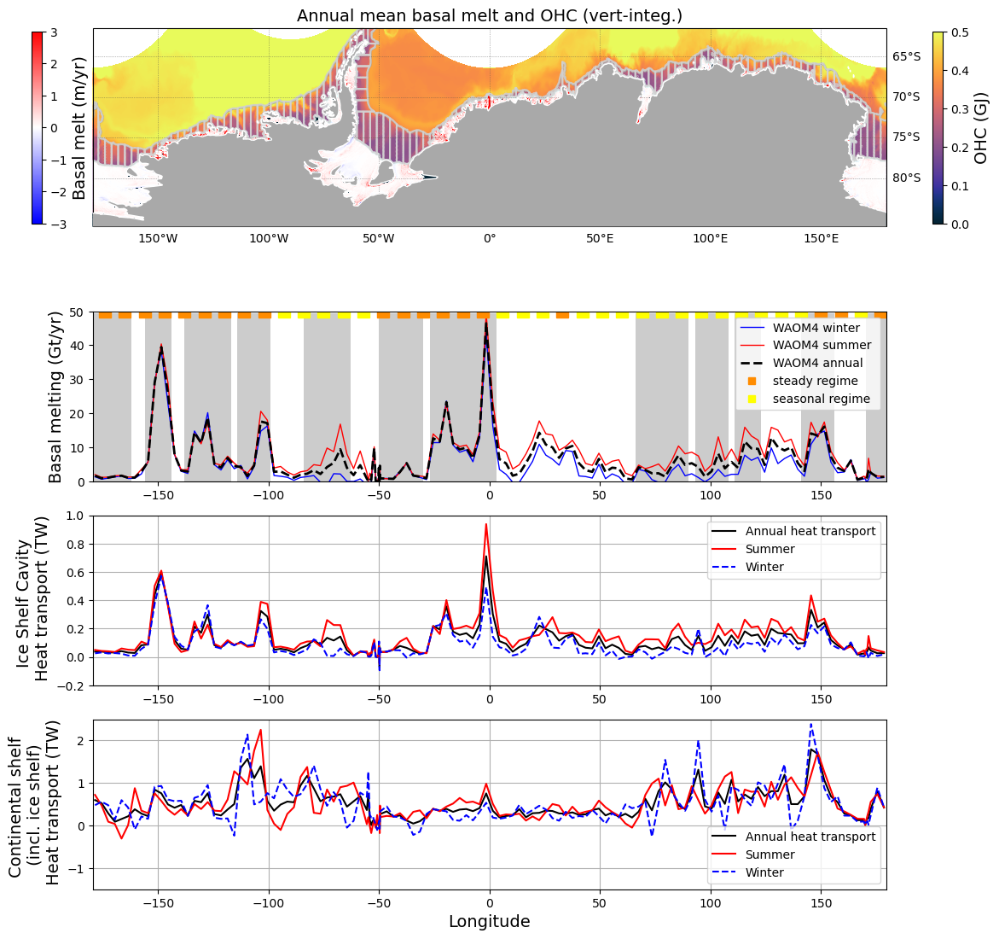

In [49]:
# Fig. 1: 
Melt_fac_map=365.25*86400
rho_ice = 916 # https://github.com/kuechenrole/antarctic_melting/blob/master/notebooks/GRL/Susheel_bfrn_depth_structure.ipynb
Melt_fac=rho_ice*1e-12 # convert to Gigatonne (=1e12 kg)

proj = ccrs.PlateCarree(central_longitude=0)

fig = plt.figure(figsize=(12,15))

# 1) map:

# -for 4km:
jst= 100
jen=-1
ist=0
ien=-1
tmin = 0
tmax = 0.5

ax1 = fig.add_subplot(2,1,1, projection=proj)
ct1=plt.pcolormesh(lon_rho_4km[jst:jen,ist:ien].values,lat_rho_4km[jst:jen,ist:ien].values,
                   temp3d_vint_4km_annual[jst:jen,ist:ien]*1e-9, transform=ccrs.PlateCarree(), cmap=cmocean.cm.thermal, vmin=tmin, vmax=tmax)
cm1=plt.pcolormesh(lon_rho_4km[jst:jen,ist:ien].values,lat_rho_4km[jst:jen,ist:ien].values,
                   ma.masked_where(contour_masked_above_CF_4km[jst:jen,ist:ien] == -1000, melt_4km[:,jst:jen,ist:ien].mean('ocean_time'))*Melt_fac_map,
                   transform=ccrs.PlateCarree(), vmin=-3, vmax=3, cmap='bwr') #, cmap=cmocean.cm.balance
plt.scatter(lon_along_4km,lat_along_4km,marker='.', s=.3, alpha=0.4, color='darkgray',label='1500m isobath', transform=ccrs.PlateCarree());
plt.scatter(lon_along_4km_CF,lat_along_4km_CF,marker='.', s=.3, alpha=0.4, color='lightcyan',label='Calving front', transform=ccrs.PlateCarree());
# plt.legend(loc='lower right')

## ---- include bins limits:
for ii in np.arange(1,140): # 1-125 is fine, issue is the ones closer to 180E/W??
    tmp = mask_LonBins_4km[ii,:]*w4_mask_zice*w4_mask_land*w4_mask_shelf
    tmp_filled = np.nan_to_num(tmp, nan=0)
    cc=plt.contour(lon_rho_4km,lat_rho_4km,
                    tmp_filled, levels=[0.5], transform=ccrs.PlateCarree(), colors='lightgray', linewidth=0.25, alpha=0.8)
ien=750
ii=0
tmp = mask_LonBins_4km[ii,:]*w4_mask_zice*w4_mask_land*w4_mask_shelf
tmp_filled = np.nan_to_num(tmp, nan=0)
cc=plt.contour(lon_rho_4km[jst:jen,ist:ien].values,lat_rho_4km[jst:jen,ist:ien].values,
                tmp_filled[jst:jen,ist:ien], levels=[0.5], transform=ccrs.PlateCarree(), colors='lightgray', linewidth=0.25, alpha=0.8)
ist=750
ien=-1
ii=-1
tmp = mask_LonBins_4km[ii,:]*w4_mask_zice*w4_mask_land*w4_mask_shelf
tmp_filled = np.nan_to_num(tmp, nan=0)
cc=plt.contour(lon_rho_4km[jst:jen,ist:ien].values,lat_rho_4km[jst:jen,ist:ien].values,
                tmp_filled[jst:jen,ist:ien], levels=[0.5], transform=ccrs.PlateCarree(), colors='lightgray', linewidth=0.25, alpha=0.8)
## ------------------------
plt.title('Annual mean basal melt and OHC (vert-integ.)',fontsize=14)

gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xlines = True
gl.top_labels=False   # suppress top labels
gl.left_labels=False   # suppress top labels
gl.xlabels_bottom = True
# gl.ylabels_left = False
# gl.ylabels_right = True

ax1.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax1.set_extent([-179.5, 179.5, -86, -61.5], crs=ccrs.PlateCarree())
x_left, x_right = ax1.get_xlim()
y_low, y_high = ax1.get_ylim()
ratio = .25  #.175

ax1.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)
cbar_ax0 = fig.add_axes([0.945, 0.63,  0.01, 0.15])
fig.colorbar(ct1, cax=cbar_ax0, orientation='vertical')
cbar_ax0.set_ylabel('OHC (GJ)',fontsize=14)#, labelpad=-35)
cbar_ax1 = fig.add_axes([0.065, 0.63,  0.01, 0.15])
fig.colorbar(cm1, cax=cbar_ax1, orientation='vertical')
cbar_ax1.set_ylabel('Basal melt (m/yr)',fontsize=14)#, labelpad=-35)


ax1 = fig.add_subplot(5,1,5)
ax1.plot(w4_lon_bins,(W4avg_hadv.mean('ocean_time')+W4avg_hdiff.mean('ocean_time'))*1e-12,'-',alpha=1,color='k',label='Annual heat transport')
ax1.plot(w4_lon_bins,(W4avg_hadv_summer.mean('ocean_time')+W4avg_hdiff_summer.mean('ocean_time'))*1e-12,'-',linewidth=1.5,alpha=1,color='r',label='Summer')
ax1.plot(w4_lon_bins,(W4avg_hadv.isel(ocean_time=slice(win1,win2)).mean('ocean_time')+
                      W4avg_hdiff.isel(ocean_time=slice(win1,win2)).mean('ocean_time'))
                      *1e-12,'--',linewidth=1.5,alpha=1,color='b',label='Winter')
# ax1.set_title('Net heat tendency - continental shelf')
ax1.legend(loc='lower right')
ax1.set_xlim(-179.5,179.5)
ax1.set_ylim(-1.5,2.5)
ax1.grid('on')
ax1.set_ylabel('Continental shelf \n (incl. ice shelf) \n Heat transport (TW)',fontsize=14)
ax1.set_xlabel('Longitude',fontsize=14)


ax1 = fig.add_subplot(5,1,4)
ax1.plot(w4_lon_bins,(W4avg_hadv_is.mean('ocean_time')+W4avg_hdiff_is.mean('ocean_time'))*1e-12,'-',alpha=1,color='k',label='Annual heat transport')
ax1.plot(w4_lon_bins,(W4avg_hadv_is_summer.mean('ocean_time')+W4avg_hdiff_is_summer.mean('ocean_time'))*1e-12,'-',linewidth=1.5,alpha=1,color='r',label='Summer')
ax1.plot(w4_lon_bins,(W4avg_hadv_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')+
                      W4avg_hdiff_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time'))
                      *1e-12,'--',linewidth=1.5,alpha=1,color='b',label='Winter')
ax1.legend(loc='upper right')
ax1.set_xlim(-179.5,179.5)
ax1.set_ylim(-.2,1)
ax1.grid('on')
ax1.set_ylabel('Ice Shelf Cavity \n Heat transport (TW)',fontsize=14)

ax2 = fig.add_subplot(5,1,3)
# seasonal
ax2.plot(w4_lon_bins,np.nanmean(W4avg_bmelt.isel(ocean_time=slice(win1,win2)), axis=0)*Melt_fac,'-b',label='WAOM4 winter ',linewidth=1)
ax2.plot(w4_lon_bins,np.nanmean(W4avg_bmelt_summer, axis=0)*Melt_fac,'-r',label='WAOM4 summer ',linewidth=1)
ax2.plot(w4_lon_bins,np.nanmean(W4avg_bmelt, axis=0)*Melt_fac,'--k',label='WAOM4 annual', linewidth=2)
ax2.plot(lon_bin_mid[8],regime_class[8]+100,'s',color='darkorange',label='steady regime')     
ax2.plot(lon_bin_mid[9],regime_class[9]+100,'s',color='yellow',label='seasonal regime')
ax2.legend(loc='upper left')

# - plot gray shads:
for ii in np.arange(0,6):
    Xplt, Yplt = np.meshgrid(w4_lon_bins[sind_subreg[ii]:eind_subreg[ii]], np.arange(-50,50))
    print(Xplt.shape, Yplt.shape,np.ones((100,len(Xplt[0,:]))).shape)
    ax2.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
    del Xplt, Yplt
for ii in np.arange(7,13):
    Xplt, Yplt = np.meshgrid(w4_lon_bins[sind_subreg[ii]:eind_subreg[ii]], np.arange(-50,50))
    print(Xplt.shape, Yplt.shape,np.ones((100,len(Xplt[0,:]))).shape)
    ax2.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
    del Xplt, Yplt

ax2.legend()
ax2.set_ylabel('Basal melting (Gt/yr)',fontsize=14)
ax2.set_xlim(-179.5,179.5)
ax2.set_ylim(0,50)
for ii in range(40):
    if regime_class[ii] == 0:
        ax2.plot(lon_bin_mid[ii],regime_class[ii]+50,'s',color='yellow',label='seasonal regime',markersize=10)
    elif regime_class[ii] == 2:
        ax2.plot(lon_bin_mid[ii],regime_class[ii]+48,'s',color='darkorange',label='steady regime',markersize=10)

name_fig='waom4_lonbin_regional_Basal_melt_seasonal_Figure1new_yr10-12avg.png'
plt.savefig(fig_path + name_fig, dpi=600, bbox_inches='tight')


### Fig. for The Conversation Pitch:

In [50]:

# Assign regime to each calving front point based on nearest longitude bin
regime_per_point = np.zeros_like(lon_along_4km_CF)
for i, lon in enumerate(lon_along_4km_CF.values):
    idx = np.argmin(np.abs(lon_bin_mid - lon))
    regime_per_point[i] = regime_class[idx]

# Create a color map: yellow for seasonal (0), orange for steady (2)
colors = np.where(regime_per_point == 0, 'yellow', 'darkviolet') 
# colors = np.where(regime_per_point == 0, 'cyan', 'forestgreen') 


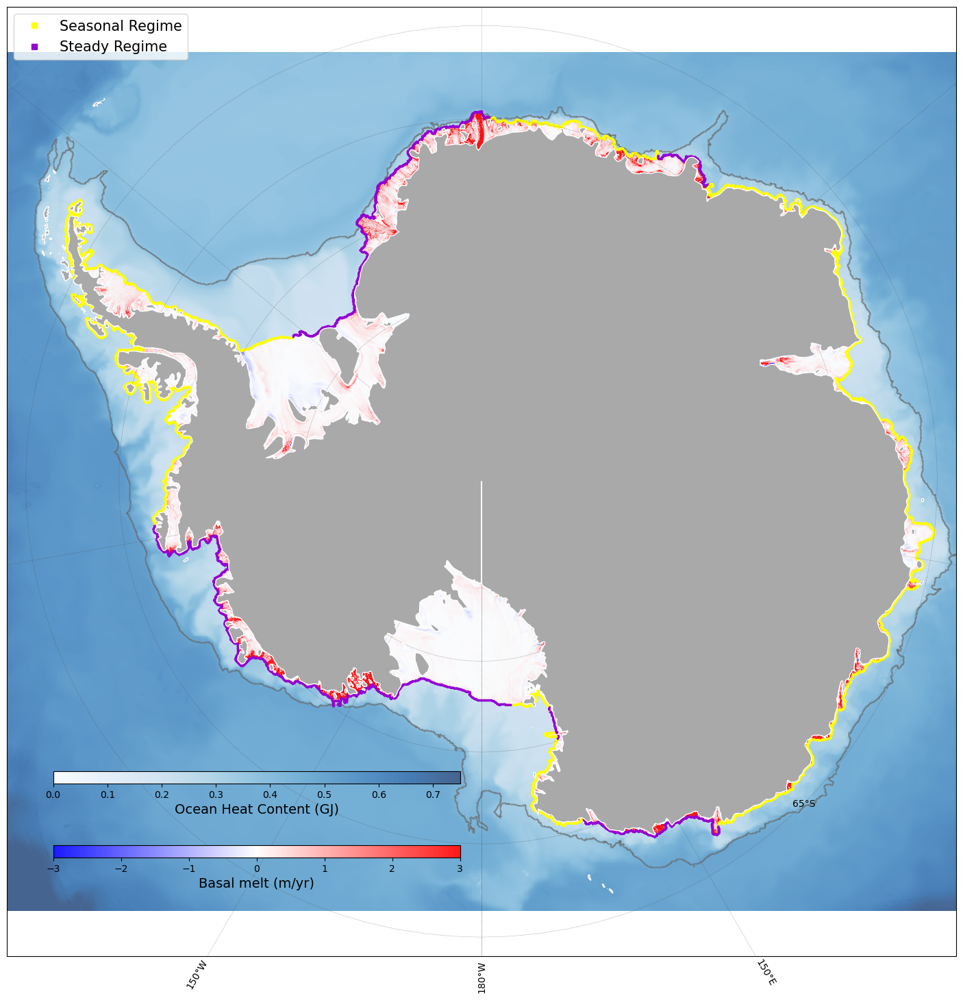

In [68]:
### trying simplified version for a pitch:



# proj = ccrs.PlateCarree(central_longitude=0)
proj = ccrs.SouthPolarStereo()


fig = plt.figure(figsize=(18,18))

# 1) map:

# -for 4km:
jst= 100
jen=-1
ist=0
ien=-1
tmin = 0
tmax = 0.75

ax1 = fig.add_subplot(1,1,1, projection=proj)
ct1=plt.pcolormesh(lon_rho_4km[jst:jen,ist:ien].values,lat_rho_4km[jst:jen,ist:ien].values,
                   temp3d_vint_4km_annual[jst:jen,ist:ien]*1e-9, transform=ccrs.PlateCarree(), cmap='Blues', vmin=tmin, vmax=tmax, alpha=0.75)
                   # temp3d_vint_4km_annual[jst:jen,ist:ien]*1e-9, transform=ccrs.PlateCarree(), cmap=cmocean.cm.thermal, vmin=tmin, vmax=tmax, alpha=0.8)
cm1=plt.pcolormesh(lon_rho_4km[jst:jen,ist:ien].values,lat_rho_4km[jst:jen,ist:ien].values,
                   ma.masked_where(contour_masked_above_CF_4km[jst:jen,ist:ien] == -1000, melt_4km[:,jst:jen,ist:ien].mean('ocean_time'))*Melt_fac_map,
                   transform=ccrs.PlateCarree(), vmin=-3, vmax=3, cmap='bwr',alpha=.9) #, cmap=cmocean.cm.balance
plt.scatter(lon_along_4km,lat_along_4km,marker='.', s=.3, alpha=.9, color='dimgray', transform=ccrs.PlateCarree()); #,label='1500m isobath'
plt.scatter(lon_along_4km_CF, lat_along_4km_CF, marker='x', s=2.5, alpha=1,c=colors, transform=ccrs.PlateCarree()) #, label='Calving front')

# add legend
ax1.plot(lon_bin_mid[8],regime_class[8]+100,'s', transform=ccrs.PlateCarree(),color='yellow',label='Seasonal Regime')     
ax1.plot(lon_bin_mid[9],regime_class[9]+100,'s', transform=ccrs.PlateCarree(),color='darkviolet',label='Steady Regime')
plt.legend(loc='upper left', fontsize=15)

gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xlines = True
gl.top_labels=False   # suppress top labels
gl.left_labels=False   # suppress top labels
gl.xlabels_bottom = True

ax1.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax1.set_extent([-179.5, 179.5, -86, -64.], crs=ccrs.PlateCarree())
x_left, x_right = ax1.get_xlim()
y_low, y_high = ax1.get_ylim()
ratio = .25 

cbar_ax0 = fig.add_axes([0.165, 0.25,  0.33, 0.01])
fig.colorbar(ct1, cax=cbar_ax0, orientation='horizontal')
cbar_ax0.set_xlabel('Ocean Heat Content (GJ)',fontsize=14)#, labelpad=-35)
cbar_ax1 = fig.add_axes([0.165, 0.19,  0.33, 0.01])
fig.colorbar(cm1, cax=cbar_ax1, orientation='horizontal')
cbar_ax1.set_xlabel('Basal melt (m/yr)',fontsize=14)#, labelpad=-35)

name_fig='waom4_lonbin_regional_Basal_melt_seasonal_Figure_ThePitch_Blues.png'
plt.savefig(fig_path + name_fig, dpi=300, bbox_inches='tight')



##### Summer Vs Winter pictures:

In [77]:
temp3d_vint_4km_summer = temp3d_4km_K.sel(ocean_time=temp3d_4km_K.ocean_time.dt.month.isin([1,2,3,4,5,12])).sum('s_rho').mean('ocean_time')*rho0*Cp
temp3d_vint_4km_winter = temp3d_4km_K.sel(ocean_time=temp3d_4km_K.ocean_time.dt.month.isin([6,7,8,9,10,11])).sum('s_rho').mean('ocean_time')*rho0*Cp

melt_4km_summer = melt_4km.sel(ocean_time=melt_4km.ocean_time.dt.month.isin([1,2,3,4,5,12])).mean('ocean_time')*Melt_fac_map - melt_4km.mean('ocean_time')*Melt_fac_map
melt_4km_winter = melt_4km.sel(ocean_time=melt_4km.ocean_time.dt.month.isin([6,7,8,9,10,11])).mean('ocean_time')*Melt_fac_map - melt_4km.mean('ocean_time')*Melt_fac_map


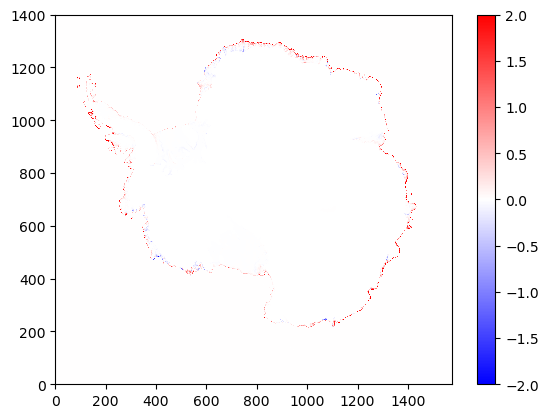

In [81]:
plt.pcolormesh(melt_4km_summer, cmap='bwr', vmin=-2, vmax=2)
plt.colorbar()

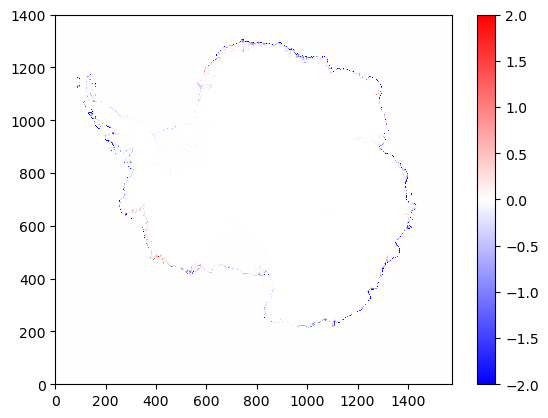

In [82]:
plt.pcolormesh(melt_4km_winter, cmap='bwr', vmin=-2, vmax=2)
plt.colorbar()

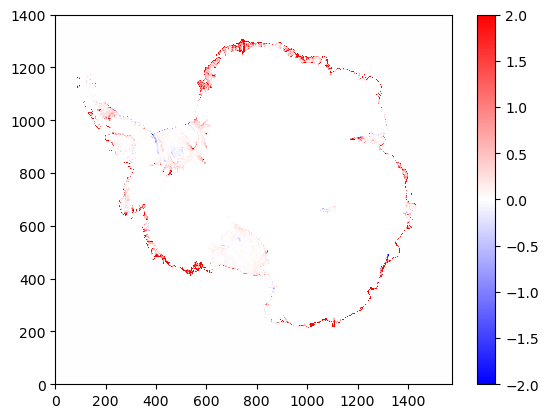

In [85]:
plt.pcolormesh(melt_4km.mean('ocean_time')*Melt_fac_map, cmap='bwr', vmin=-2, vmax=2)
plt.colorbar()

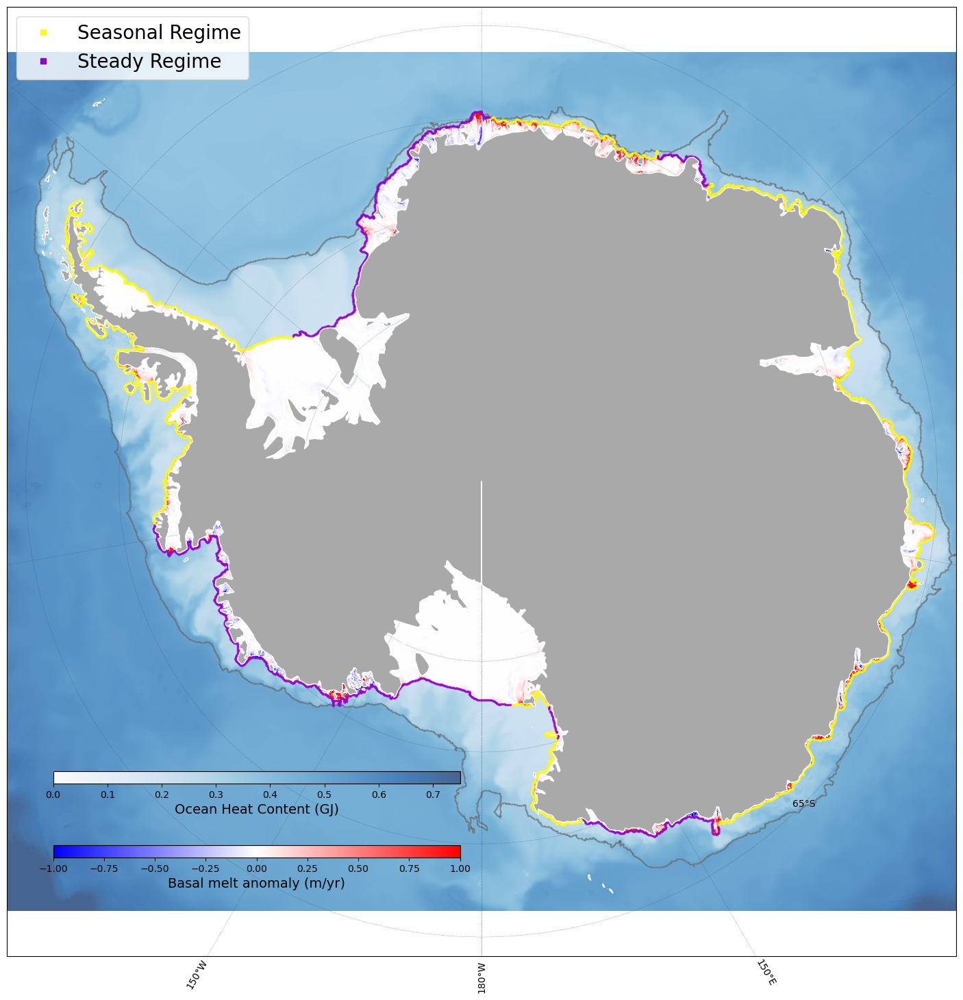

In [93]:
### trying simplified version for a pitch:



# proj = ccrs.PlateCarree(central_longitude=0)
proj = ccrs.SouthPolarStereo()


fig = plt.figure(figsize=(18,18))

# 1) map:

# -for 4km:
jst= 100
jen=-1
ist=0
ien=-1
tmin = 0
tmax = 0.75

ax1 = fig.add_subplot(1,1,1, projection=proj)
ct1=plt.pcolormesh(lon_rho_4km[jst:jen,ist:ien].values,lat_rho_4km[jst:jen,ist:ien].values,
                   temp3d_vint_4km_summer[jst:jen,ist:ien]*1e-9, transform=ccrs.PlateCarree(), cmap='Blues', vmin=tmin, vmax=tmax, alpha=0.75)
cm1=plt.pcolormesh(lon_rho_4km[jst:jen,ist:ien].values,lat_rho_4km[jst:jen,ist:ien].values,
                   ma.masked_where(contour_masked_above_CF_4km[jst:jen,ist:ien] == -1000, melt_4km_summer[jst:jen,ist:ien]),
                   transform=ccrs.PlateCarree(), vmin=-1, vmax=1, cmap='bwr',alpha=1) #, cmap=cmocean.cm.balance
plt.scatter(lon_along_4km,lat_along_4km,marker='.', s=.3, alpha=.9, color='dimgray', transform=ccrs.PlateCarree()); #,label='1500m isobath'
plt.scatter(lon_along_4km_CF, lat_along_4km_CF, marker='x', s=2.5, alpha=.5,c=colors, transform=ccrs.PlateCarree()) #, label='Calving front')

# add legend
ax1.plot(lon_bin_mid[8],regime_class[8]+100,'s', transform=ccrs.PlateCarree(),color='yellow',label='Seasonal Regime')     
ax1.plot(lon_bin_mid[9],regime_class[9]+100,'s', transform=ccrs.PlateCarree(),color='darkviolet',label='Steady Regime')
plt.legend(loc='upper left', fontsize=20)

gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xlines = True
gl.top_labels=False   # suppress top labels
gl.left_labels=False   # suppress top labels
gl.xlabels_bottom = True

ax1.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax1.set_extent([-179.5, 179.5, -86, -64.], crs=ccrs.PlateCarree())
x_left, x_right = ax1.get_xlim()
y_low, y_high = ax1.get_ylim()
ratio = .25 

cbar_ax0 = fig.add_axes([0.165, 0.25,  0.33, 0.01])
fig.colorbar(ct1, cax=cbar_ax0, orientation='horizontal')
cbar_ax0.set_xlabel('Ocean Heat Content (GJ)',fontsize=14)#, labelpad=-35)
cbar_ax1 = fig.add_axes([0.165, 0.19,  0.33, 0.01])
fig.colorbar(cm1, cax=cbar_ax1, orientation='horizontal')
cbar_ax1.set_xlabel('Basal melt anomaly (m/yr)',fontsize=14)#, labelpad=-35)

name_fig='waom4_lonbin_regional_Basal_melt_seasonal_Figure_ThePitch_Blues_summer.png'
plt.savefig(fig_path + name_fig, dpi=300, bbox_inches='tight')



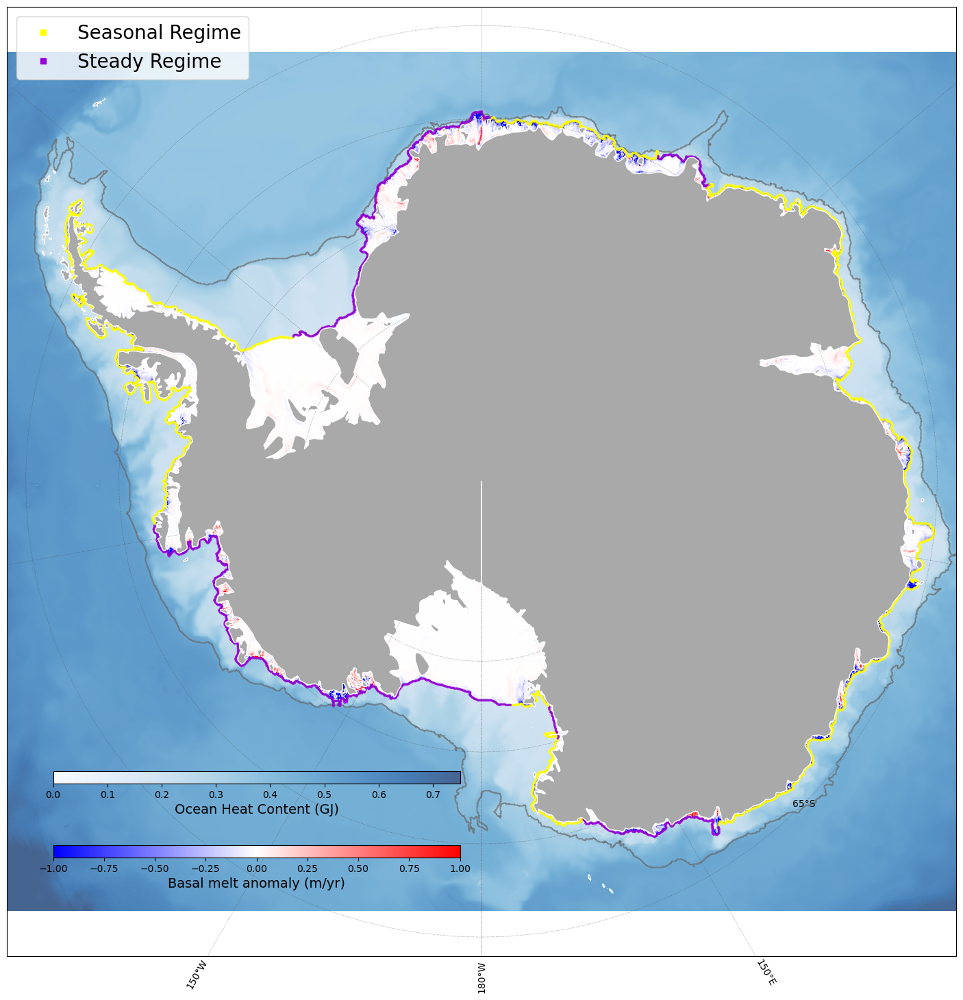

In [92]:
### trying simplified version for a pitch:



# proj = ccrs.PlateCarree(central_longitude=0)
proj = ccrs.SouthPolarStereo()


fig = plt.figure(figsize=(18,18))

# 1) map:

# -for 4km:
jst= 100
jen=-1
ist=0
ien=-1
tmin = 0
tmax = 0.75

ax1 = fig.add_subplot(1,1,1, projection=proj)
ct1=plt.pcolormesh(lon_rho_4km[jst:jen,ist:ien].values,lat_rho_4km[jst:jen,ist:ien].values,
                   temp3d_vint_4km_winter[jst:jen,ist:ien]*1e-9, transform=ccrs.PlateCarree(), cmap='Blues', vmin=tmin, vmax=tmax, alpha=0.75)
cm1=plt.pcolormesh(lon_rho_4km[jst:jen,ist:ien].values,lat_rho_4km[jst:jen,ist:ien].values,
                   ma.masked_where(contour_masked_above_CF_4km[jst:jen,ist:ien] == -1000, melt_4km_winter[jst:jen,ist:ien]),
                   transform=ccrs.PlateCarree(), vmin=-1, vmax=1, cmap='bwr',alpha=1) #, cmap=cmocean.cm.balance
plt.scatter(lon_along_4km,lat_along_4km,marker='.', s=.3, alpha=.9, color='dimgray', transform=ccrs.PlateCarree()); #,label='1500m isobath'
plt.scatter(lon_along_4km_CF, lat_along_4km_CF, marker='x', s=2.5, alpha=.5,c=colors, transform=ccrs.PlateCarree()) #, label='Calving front')

# add legend
ax1.plot(lon_bin_mid[8],regime_class[8]+100,'s', transform=ccrs.PlateCarree(),color='yellow',label='Seasonal Regime')     
ax1.plot(lon_bin_mid[9],regime_class[9]+100,'s', transform=ccrs.PlateCarree(),color='darkviolet',label='Steady Regime')
plt.legend(loc='upper left', fontsize=20)

gl = ax1.gridlines(crs=ccrs.PlateCarree(), draw_labels=True,linewidth=.5, color=[.3,.3,.3], alpha=0.75, linestyle=':')
gl.xformatter = LONGITUDE_FORMATTER
gl.yformatter = LATITUDE_FORMATTER
gl.xlocator = mticker.FixedLocator([-180, -150, -100, -50, 0, 50, 100, 150, 180])
gl.ylocator = mticker.FixedLocator([-65, -70, -75, -80])
gl.xlines = True
gl.top_labels=False   # suppress top labels
gl.left_labels=False   # suppress top labels
gl.xlabels_bottom = True

ax1.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
ax1.set_extent([-179.5, 179.5, -86, -64.], crs=ccrs.PlateCarree())
x_left, x_right = ax1.get_xlim()
y_low, y_high = ax1.get_ylim()
ratio = .25 

cbar_ax0 = fig.add_axes([0.165, 0.25,  0.33, 0.01])
fig.colorbar(ct1, cax=cbar_ax0, orientation='horizontal')
cbar_ax0.set_xlabel('Ocean Heat Content (GJ)',fontsize=14)#, labelpad=-35)
cbar_ax1 = fig.add_axes([0.165, 0.19,  0.33, 0.01])
fig.colorbar(cm1, cax=cbar_ax1, orientation='horizontal')
cbar_ax1.set_xlabel('Basal melt anomaly (m/yr)',fontsize=14)#, labelpad=-35)

name_fig='waom4_lonbin_regional_Basal_melt_seasonal_Figure_ThePitch_Blues_winter.png'
plt.savefig(fig_path + name_fig, dpi=300, bbox_inches='tight')



### Figure 2

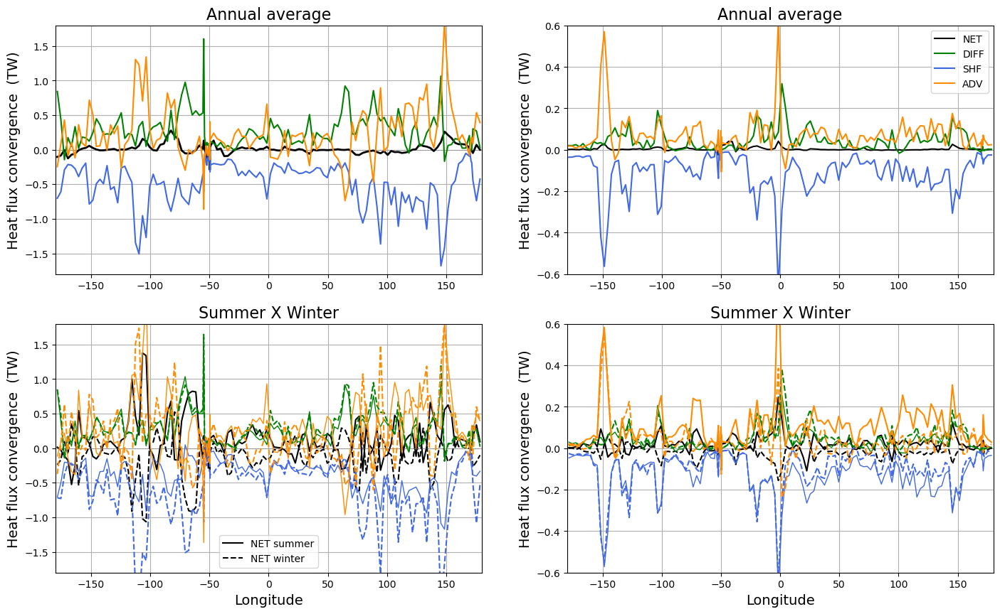

In [50]:

fig = plt.figure(figsize=(17,10))

ax1 = fig.add_subplot(2,2,1)
ax1.plot(w4_lon_bins,W4avg_net.mean('ocean_time')*0,'--',color='gray',linewidth=0.5)

# ax1.plot(w4_lon_bins,W4avg_net.mean('ocean_time')*1e-12,'-k',label='Continental shelf',linewidth=2, alpha=1)
# ax1.plot(w4_lon_bins,W4avg_net_is.mean('ocean_time')*1e-12,'--k',label='Ice shelf cavities',linewidth=2)
# ax1.legend(loc='lower right')
ax1.plot(w4_lon_bins,W4avg_net.mean('ocean_time')*1e-12,'-k',label='NET',linewidth=2, alpha=1)
ax1.plot(w4_lon_bins,W4avg_hdiff.mean('ocean_time')*1e-12,color='green',label='DIFF', alpha=1)
ax1.plot(w4_lon_bins,W4avg_vdiff.mean('ocean_time')*1e-12,color='royalblue',label='SHF', alpha=1)
ax1.plot(w4_lon_bins,W4avg_hadv.mean('ocean_time')*1e-12,color='darkorange',label='ADV', alpha=1)
# ax1.set_title('Continental shelf \n Annual average', fontsize=16)
ax1.set_title('Annual average', fontsize=16)
ax1.set_xlim(-180,180)
ax1.set_ylim(-1.8,1.8)
ax1.grid('off')
ax1.set_ylabel('Heat flux convergence  (TW)', fontsize=14)

ax1 = fig.add_subplot(2,2,2)

ax1.plot(w4_lon_bins,W4avg_net_is.mean('ocean_time')*1e-12,'-k',label='NET',linewidth=1.5,)
ax1.plot(w4_lon_bins,W4avg_hdiff_is.mean('ocean_time')*1e-12,'-',alpha=1,color='green',label='DIFF')
ax1.plot(w4_lon_bins,W4avg_vdiff_is.mean('ocean_time')*1e-12,'-',alpha=1,color='royalblue',label='SHF')
ax1.plot(w4_lon_bins,W4avg_hadv_is.mean('ocean_time')*1e-12,'-',alpha=1,color='darkorange',label='ADV')
# ax1.set_title('Ice shelf cavity \n Annual average', fontsize=16)
ax1.set_title('Annual average', fontsize=16)
ax1.legend(loc='upper right')
ax1.set_xlim(-180,180)
ax1.set_ylim(-.6,.6)
ax1.grid('off')
ax1.set_ylabel('Heat flux convergence  (TW)', fontsize=14)

ax1 = fig.add_subplot(2,2,3)
ax1.plot(w4_lon_bins,W4avg_net_summer.mean('ocean_time')*1e-12,'-k',label='NET summer',linewidth=1.5)
ax1.plot(w4_lon_bins,W4avg_net.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--k',label='NET winter',linewidth=1.5)
ax1.legend()#loc='lower left')

ax1.plot(w4_lon_bins,W4avg_net.mean('ocean_time')*0,'--',color='gray',linewidth=0.5)
ax1.plot(w4_lon_bins,W4avg_hdiff_summer.mean('ocean_time')*1e-12,linewidth=1,color='green',label='DIFF summer', alpha=1)
ax1.plot(w4_lon_bins,W4avg_hdiff.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',color='green',label='DIFF winter', alpha=1)

ax1.plot(w4_lon_bins,W4avg_vdiff_summer.mean('ocean_time')*1e-12,linewidth=1,color='royalblue',label='SHF summer', alpha=1)
ax1.plot(w4_lon_bins,W4avg_vdiff.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',color='royalblue',label='SHF winter', alpha=1)

ax1.plot(w4_lon_bins,W4avg_hadv_summer.mean('ocean_time')*1e-12,linewidth=1,color='darkorange',label='ADV summer', alpha=1)
# ax1.plot(w4_lon_bins,W4avg_net_summer.mean('ocean_time')*1e-12,'-k',label='NET summer',linewidth=1.5)
ax1.plot(w4_lon_bins,W4avg_hadv.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',color='darkorange',label='ADV winter', alpha=1)

ax1.set_title('Summer X Winter', fontsize=16)
ax1.set_xlim(-180,180)
ax1.set_ylim(-1.8,1.8)
ax1.grid('off')
ax1.set_ylabel('Heat flux convergence  (TW)', fontsize=14)
ax1.set_xlabel('Longitude', fontsize=14)

ax1 = fig.add_subplot(2,2,4)
ax1.plot(w4_lon_bins,W4avg_net_is_summer.mean('ocean_time')*1e-12,'-k',label='NET summer',linewidth=1.5)
ax1.plot(w4_lon_bins,W4avg_net_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--k',label='NET winter',linewidth=1.5)

ax1.plot(w4_lon_bins,W4avg_hdiff_is_summer.mean('ocean_time')*1e-12,'-',linewidth=1,alpha=1,color='green',label='DIFF summer')
ax1.plot(w4_lon_bins,W4avg_hdiff_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',alpha=1,color='green',label='DIFF winter')

ax1.plot(w4_lon_bins,W4avg_vdiff_is_summer.mean('ocean_time')*1e-12,'-',linewidth=1,alpha=1,color='royalblue',label='SHF summer')
ax1.plot(w4_lon_bins,W4avg_vdiff_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',alpha=1,color='royalblue',label='SHF winter')

ax1.plot(w4_lon_bins,W4avg_hadv_is_summer.mean('ocean_time')*1e-12,'-',linewidth=1.5,alpha=1,color='darkorange',label='ADV summer')
ax1.plot(w4_lon_bins,W4avg_hadv_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',linewidth=1.5,alpha=1,color='darkorange',label='ADV winter')
ax1.set_title('Summer X Winter', fontsize=16)
ax1.set_xlim(-180,180)
ax1.set_ylim(-.6,.6)
ax1.grid('off')
ax1.set_ylabel('Heat flux convergence  (TW)', fontsize=14)
ax1.set_xlabel('Longitude', fontsize=14)


name_fig='waom4_lonbin_regional_OHB_wholeshelf_Figure2_yr10-12.png'
plt.savefig(fig_path + name_fig, dpi=600, bbox_inches='tight')

(100, 4) (100, 4) (100, 4)
(100, 7) (100, 7) (100, 7)
(100, 5) (100, 5) (100, 5)
(100, 7) (100, 7) (100, 7)
(100, 18) (100, 18) (100, 18)
(100, 10) (100, 10) (100, 10)
(100, 8) (100, 8) (100, 8)
(100, 5) (100, 5) (100, 5)
(100, 4) (100, 4) (100, 4)
(100, 5) (100, 5) (100, 5)
(100, 6) (100, 6) (100, 6)
(100, 6) (100, 6) (100, 6)


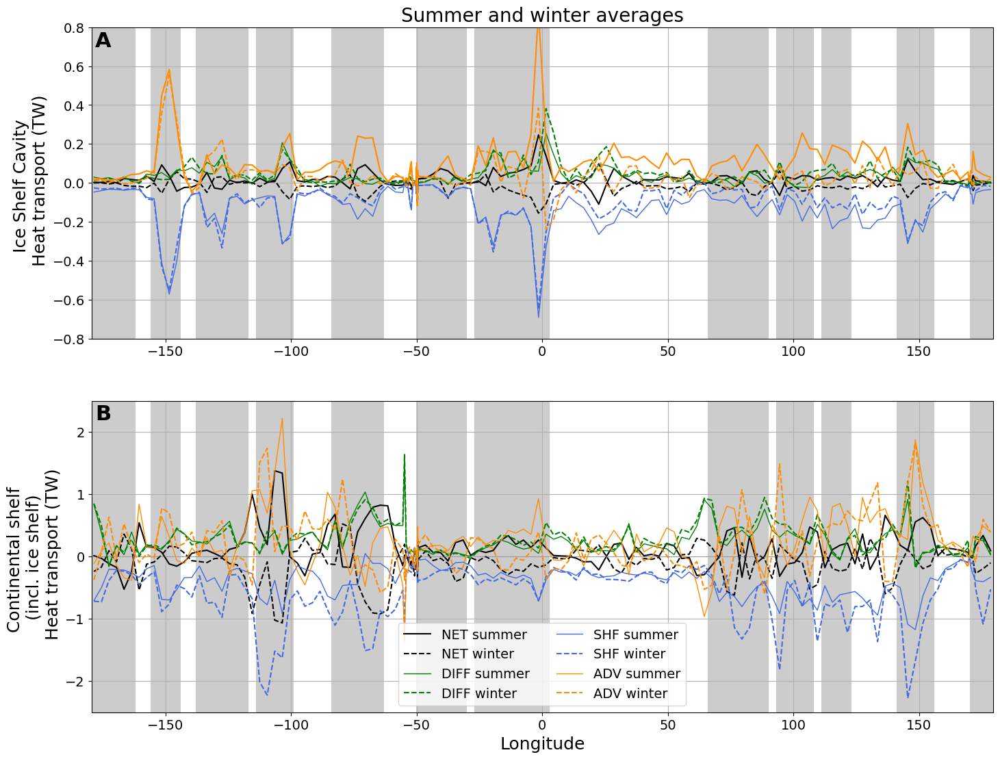

In [51]:

fig = plt.figure(figsize=(17,13))

ax1 = fig.add_subplot(2,1,2)
ax1.plot(w4_lon_bins,W4avg_net_summer.mean('ocean_time')*1e-12,'-k',label='NET summer',linewidth=1.5)
ax1.plot(w4_lon_bins,W4avg_net.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--k',label='NET winter',linewidth=1.5)

ax1.plot(w4_lon_bins,W4avg_net.mean('ocean_time')*0,'--',color='gray',linewidth=0.5)
ax1.plot(w4_lon_bins,W4avg_hdiff_summer.mean('ocean_time')*1e-12,linewidth=1,color='green',label='DIFF summer', alpha=1)
ax1.plot(w4_lon_bins,W4avg_hdiff.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',color='green',label='DIFF winter', alpha=1)

ax1.plot(w4_lon_bins,W4avg_vdiff_summer.mean('ocean_time')*1e-12,linewidth=1,color='royalblue',label='SHF summer', alpha=1)
ax1.plot(w4_lon_bins,W4avg_vdiff.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',color='royalblue',label='SHF winter', alpha=1)

ax1.plot(w4_lon_bins,W4avg_hadv_summer.mean('ocean_time')*1e-12,linewidth=1,color='darkorange',label='ADV summer', alpha=1)
# ax1.plot(w4_lon_bins,W4avg_net_summer.mean('ocean_time')*1e-12,'-k',label='NET summer',linewidth=1.5)
ax1.plot(w4_lon_bins,W4avg_hadv.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',color='darkorange',label='ADV winter', alpha=1)

ax1.set_xlim(-179.5,179.5)
ax1.set_ylim(-2.5,2.5)
ax1.grid('off')
ax1.set_ylabel('Continental shelf \n (incl. ice shelf) \n Heat transport (TW)',fontsize=18)
ax1.set_xlabel('Longitude', fontsize=18)
ax1.legend(ncol=2,loc='lower center',fontsize=14)
ax1.tick_params(axis='x',labelsize=14)
ax1.tick_params(axis='y',labelsize=14)
ax1.text(-178,2.2,'B',fontsize=22,weight="bold")

ax2 = fig.add_subplot(2,1,1)
ax2.plot(w4_lon_bins,W4avg_net_is_summer.mean('ocean_time')*1e-12,'-k',label='NET summer',linewidth=1.5)
ax2.plot(w4_lon_bins,W4avg_net_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--k',label='NET winter',linewidth=1.5)

ax2.plot(w4_lon_bins,W4avg_hdiff_is_summer.mean('ocean_time')*1e-12,'-',linewidth=1,alpha=1,color='green',label='DIFF summer')
ax2.plot(w4_lon_bins,W4avg_hdiff_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',alpha=1,color='green',label='DIFF winter')

ax2.plot(w4_lon_bins,W4avg_vdiff_is_summer.mean('ocean_time')*1e-12,'-',linewidth=1,alpha=1,color='royalblue',label='SHF summer')
ax2.plot(w4_lon_bins,W4avg_vdiff_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',alpha=1,color='royalblue',label='SHF winter')

ax2.plot(w4_lon_bins,W4avg_hadv_is_summer.mean('ocean_time')*1e-12,'-',linewidth=1.5,alpha=1,color='darkorange',label='ADV summer')
ax2.plot(w4_lon_bins,W4avg_hadv_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',linewidth=1.5,alpha=1,color='darkorange',label='ADV winter')
# ax.set_title('Summer and winter averages', fontsize=16)
ax2.set_xlim(-179.5,179.5)
ax2.set_ylim(-.8,.8)
ax2.grid('off')
ax2.set_ylabel('Ice Shelf Cavity \n Heat transport (TW)',fontsize=18)
ax2.tick_params(axis='x',labelsize=14)
ax2.tick_params(axis='y',labelsize=14)
ax2.set_title('Summer and winter averages', fontsize=20)
ax2.text(-178,0.7,'A',fontsize=22,weight="bold")

# - plot gray shads:
for ii in np.arange(0,6):
    Xplt, Yplt = np.meshgrid(w4_lon_bins[sind_subreg[ii]:eind_subreg[ii]], np.arange(-50,50))
    print(Xplt.shape, Yplt.shape,np.ones((100,len(Xplt[0,:]))).shape)
    ax1.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
    ax2.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
    del Xplt, Yplt
for ii in np.arange(7,13):
    Xplt, Yplt = np.meshgrid(w4_lon_bins[sind_subreg[ii]:eind_subreg[ii]], np.arange(-50,50))
    print(Xplt.shape, Yplt.shape,np.ones((100,len(Xplt[0,:]))).shape)
    ax1.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
    ax2.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
    del Xplt, Yplt

name_fig='waom4_lonbin_regional_OHB_wholeshelf_Figure2_yr10-12.png'
plt.savefig(fig_path + name_fig, dpi=300, bbox_inches='tight')

(100, 4) (100, 4) (100, 4)
(100, 7) (100, 7) (100, 7)
(100, 5) (100, 5) (100, 5)
(100, 7) (100, 7) (100, 7)
(100, 18) (100, 18) (100, 18)
(100, 10) (100, 10) (100, 10)
(100, 8) (100, 8) (100, 8)
(100, 5) (100, 5) (100, 5)
(100, 4) (100, 4) (100, 4)
(100, 5) (100, 5) (100, 5)
(100, 6) (100, 6) (100, 6)
(100, 6) (100, 6) (100, 6)


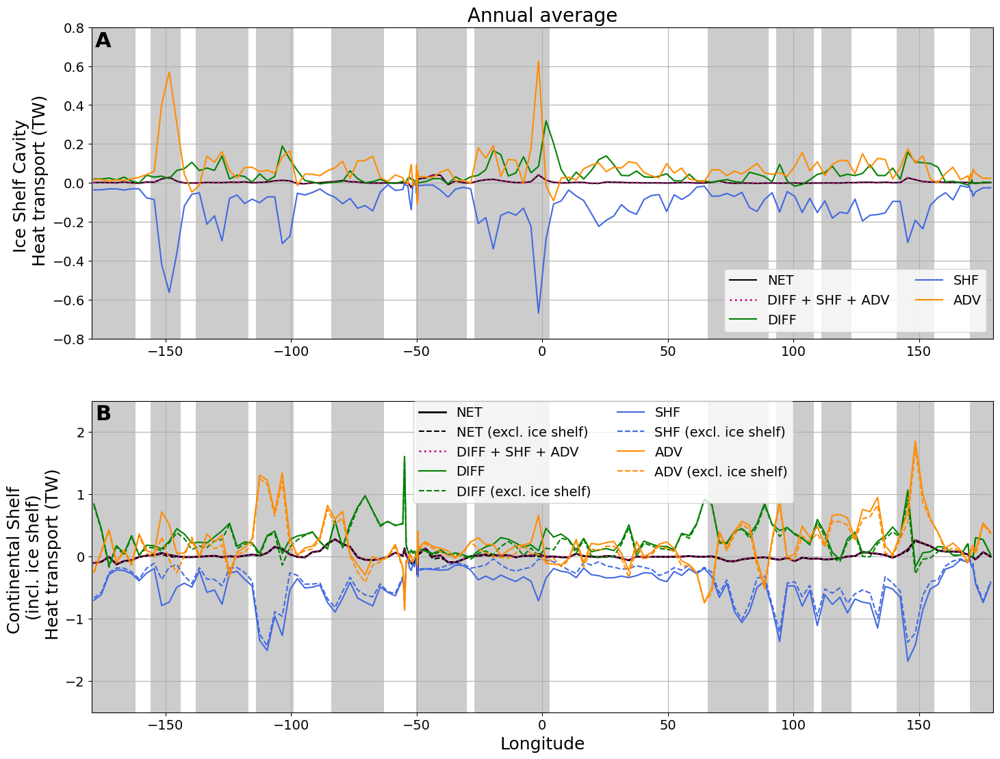

In [52]:
# reviewer #1 request: include the budget closure:
RHS_net = W4avg_hdiff + W4avg_vdiff + W4avg_hadv
RHS_net_is = W4avg_hdiff_is + W4avg_vdiff_is + W4avg_hadv_is

# repeating Fig. A1 but excluding ice shelf cavity from the shelf:

fig = plt.figure(figsize=(17,13))

ax2 = fig.add_subplot(2,1,2)
ax2.plot(w4_lon_bins,W4avg_net.mean('ocean_time')*1e-12,'-k',label='NET',linewidth=2, alpha=1)
ax2.plot(w4_lon_bins,(W4avg_net.mean('ocean_time')-W4avg_net_is.mean('ocean_time'))*1e-12,'--k',label='NET (excl. ice shelf)',linewidth=1.5)
ax2.plot(w4_lon_bins,RHS_net.mean('ocean_time')*1e-12,':',color='mediumvioletred',label='DIFF + SHF + ADV',linewidth=2, alpha=1)
# overlaying in '--' the diff. b/w cont.shelf-ice_shelf_cavity integrals:
ax2.plot(w4_lon_bins,W4avg_hdiff.mean('ocean_time')*1e-12,color='green',label='DIFF', alpha=1)
ax2.plot(w4_lon_bins,(W4avg_hdiff.mean('ocean_time')-W4avg_hdiff_is.mean('ocean_time'))*1e-12,'--',alpha=1,color='green',label='DIFF (excl. ice shelf)')
ax2.plot(w4_lon_bins,W4avg_vdiff.mean('ocean_time')*1e-12,color='royalblue',label='SHF', alpha=1)
ax2.plot(w4_lon_bins,(W4avg_vdiff.mean('ocean_time')-W4avg_vdiff_is.mean('ocean_time'))*1e-12,'--',alpha=1,color='royalblue',label='SHF (excl. ice shelf)')

ax2.plot(w4_lon_bins,W4avg_hadv.mean('ocean_time')*1e-12,color='darkorange',label='ADV', alpha=1)
ax2.plot(w4_lon_bins,(W4avg_hadv.mean('ocean_time')-W4avg_hadv_is.mean('ocean_time'))*1e-12,'--',alpha=1,color='darkorange',label='ADV (excl. ice shelf)')

ax2.legend(bbox_to_anchor=(0.35, .65), loc='lower left',ncol=2, fontsize=14)
# plt.tight_layout()
# ax2.set_title('Annual average', fontsize=18)
ax2.set_xlim(-179.5,179.5)
ax2.set_ylim(-2.5,2.5)
ax2.grid('off')
ax2.set_ylabel('Continental Shelf \n (incl. ice shelf) \n Heat transport (TW)',fontsize=18)
ax2.set_xlabel('Longitude', fontsize=18)
ax2.tick_params(axis='x',labelsize=14)
ax2.tick_params(axis='y',labelsize=14)
ax2.text(-178,2.2,'B',fontsize=22,weight="bold")


ax1 = fig.add_subplot(2,1,1)

ax1.plot(w4_lon_bins,W4avg_net_is.mean('ocean_time')*1e-12,'-k',label='NET',linewidth=1.5)
ax1.plot(w4_lon_bins,RHS_net_is.mean('ocean_time')*1e-12,':',color='mediumvioletred',label='DIFF + SHF + ADV',linewidth=2, alpha=1)
ax1.plot(w4_lon_bins,W4avg_hdiff_is.mean('ocean_time')*1e-12,'-',alpha=1,color='green',label='DIFF')
ax1.plot(w4_lon_bins,W4avg_vdiff_is.mean('ocean_time')*1e-12,'-',alpha=1,color='royalblue',label='SHF')
ax1.plot(w4_lon_bins,W4avg_hadv_is.mean('ocean_time')*1e-12,'-',alpha=1,color='darkorange',label='ADV')

# ax1.set_title('Ice shelf cavity \n Annual average', fontsize=16)
ax1.set_title('Annual average', fontsize=20)
ax1.legend(loc='lower right', fontsize=14, ncols=2)
ax1.set_xlim(-179.5,179.5)
ax1.set_ylim(-.8,.8)
ax1.grid('off')
ax1.set_ylabel('Ice Shelf Cavity \n Heat transport (TW)',fontsize=18)
ax1.tick_params(axis='x',labelsize=14)
ax1.tick_params(axis='y',labelsize=14)
ax1.text(-178,0.7,'A',fontsize=22,weight="bold")

# - plot gray shads:
for ii in np.arange(0,6):
    Xplt, Yplt = np.meshgrid(w4_lon_bins[sind_subreg[ii]:eind_subreg[ii]], np.arange(-50,50))
    print(Xplt.shape, Yplt.shape,np.ones((100,len(Xplt[0,:]))).shape)
    ax1.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
    ax2.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
    del Xplt, Yplt
for ii in np.arange(7,13):
    Xplt, Yplt = np.meshgrid(w4_lon_bins[sind_subreg[ii]:eind_subreg[ii]], np.arange(-50,50))
    print(Xplt.shape, Yplt.shape,np.ones((100,len(Xplt[0,:]))).shape)
    ax1.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
    ax2.pcolormesh(Xplt, Yplt,np.ones((100,len(Xplt[0,:]))), cmap='nipy_spectral', vmin=0, vmax=1)
    del Xplt, Yplt
    
name_fig='waom4_lonbin_regional_OHB_wholeshelf_Figure2_yr10-12_SM.png'
plt.savefig(fig_path + name_fig, dpi=300, bbox_inches='tight')

### Figure 3

In [47]:
#read sea ice data:
files_path = '/g/data/gv90/fbd581/ROMS/postprocessing/cross_contour_tmp/'
dsi = xr.open_mfdataset(paths=files_path+'WAOM4_OHB_lonlatbins_seaicec_daily_v2.nc',  parallel=bool)
SIC_bin = dsi.__xarray_dataarray_variable__
dsi.close()

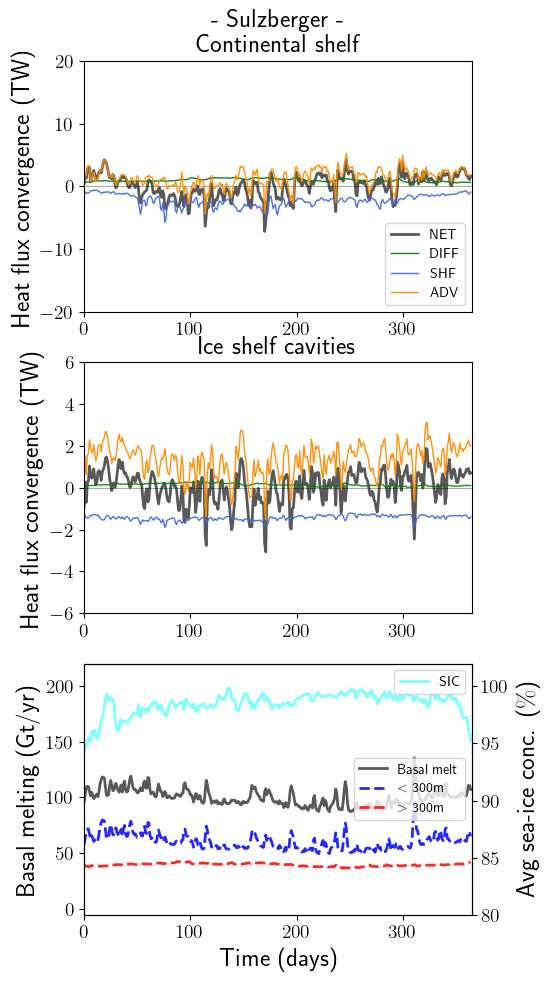

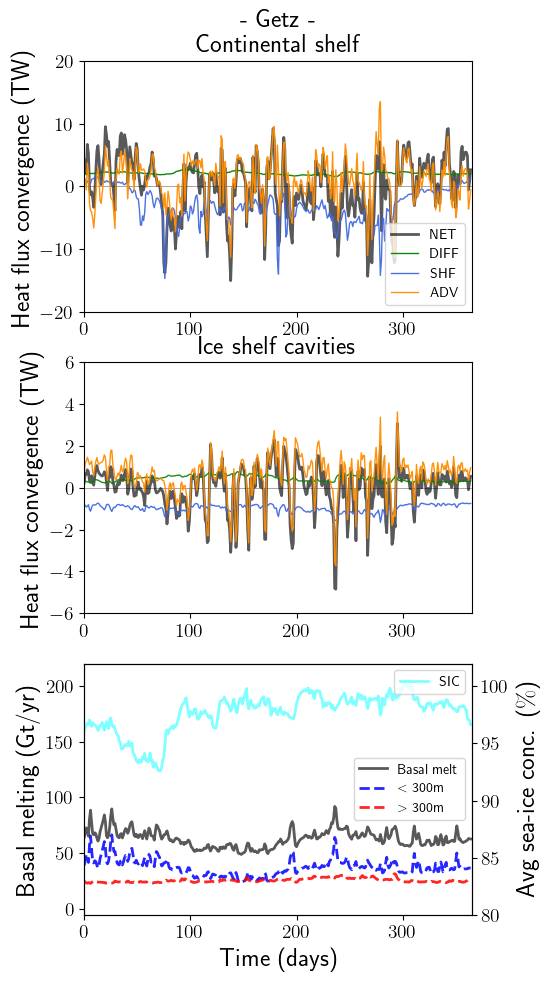

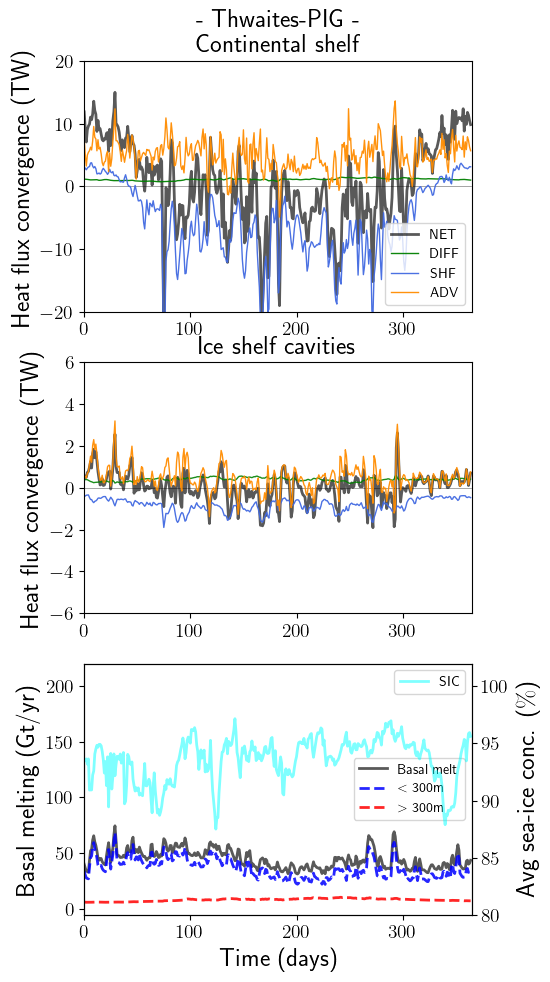

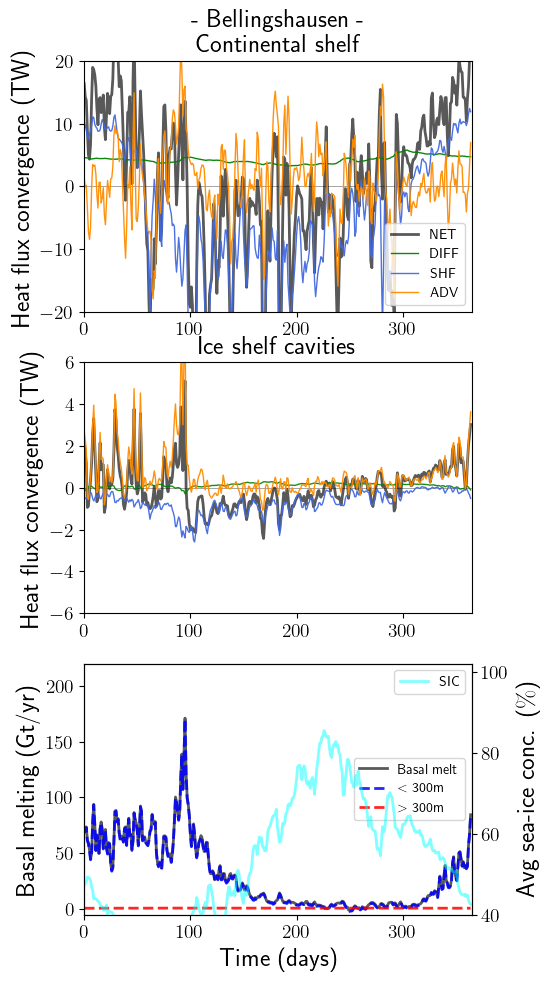

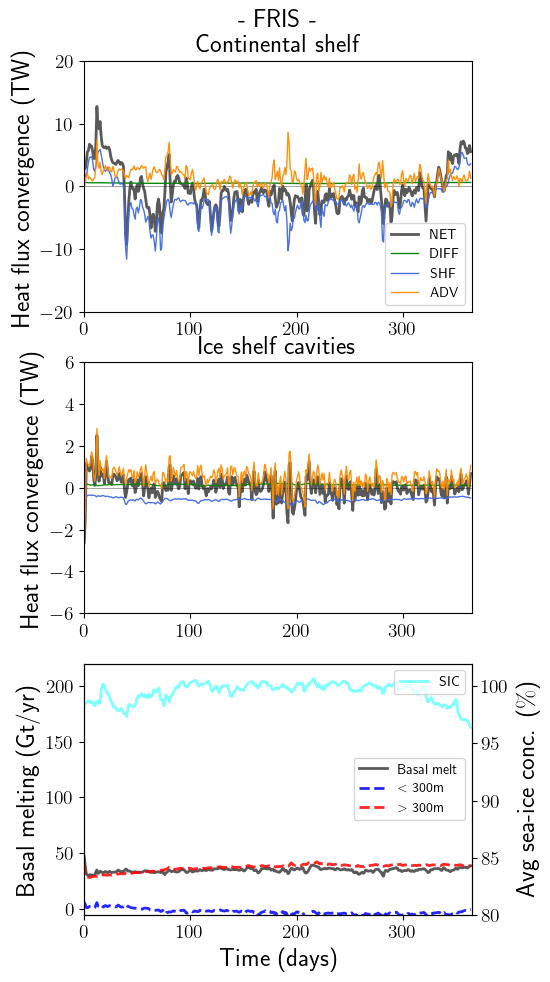

...

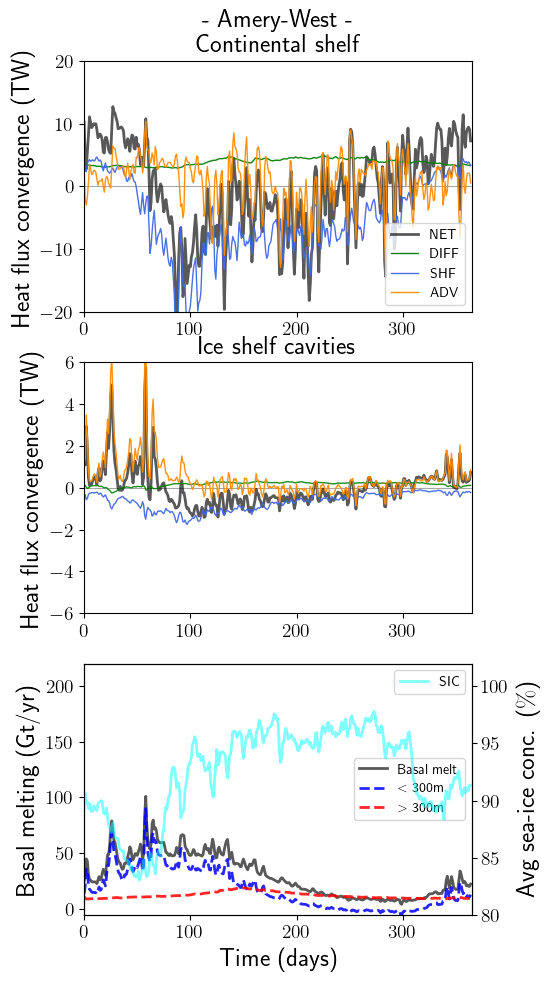

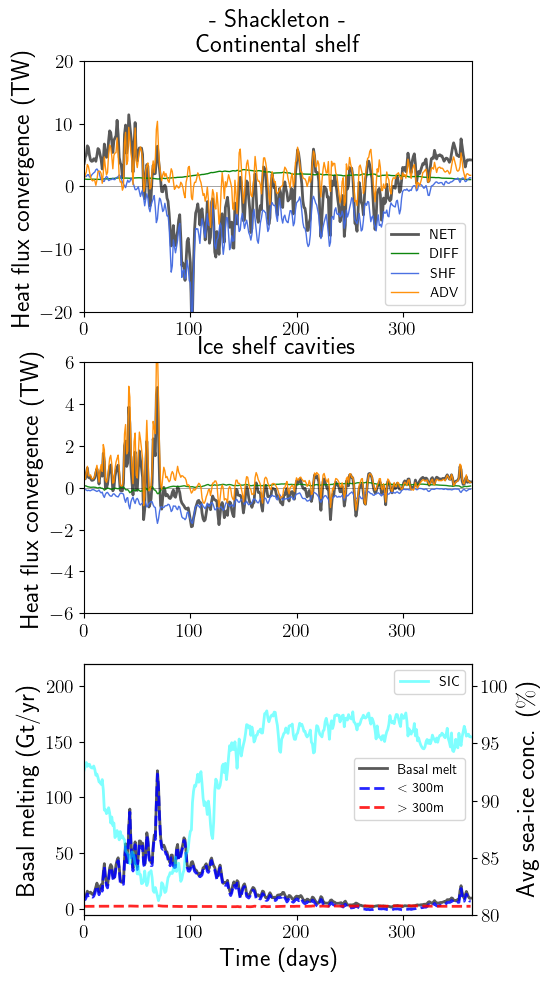

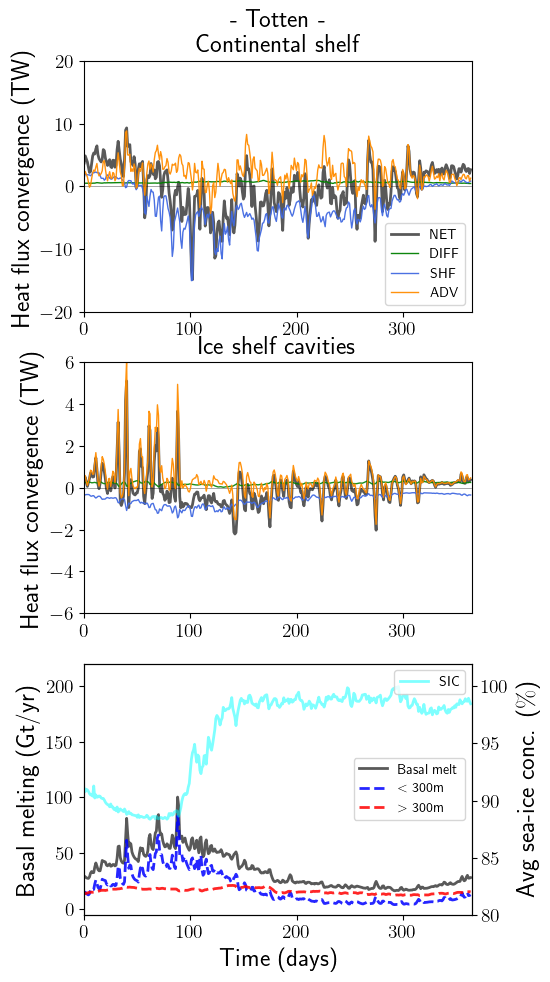

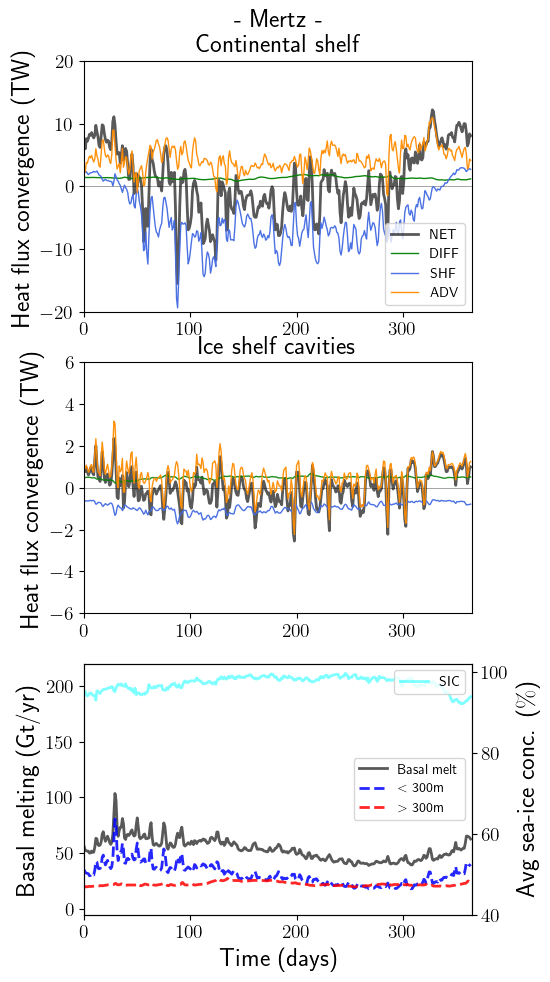

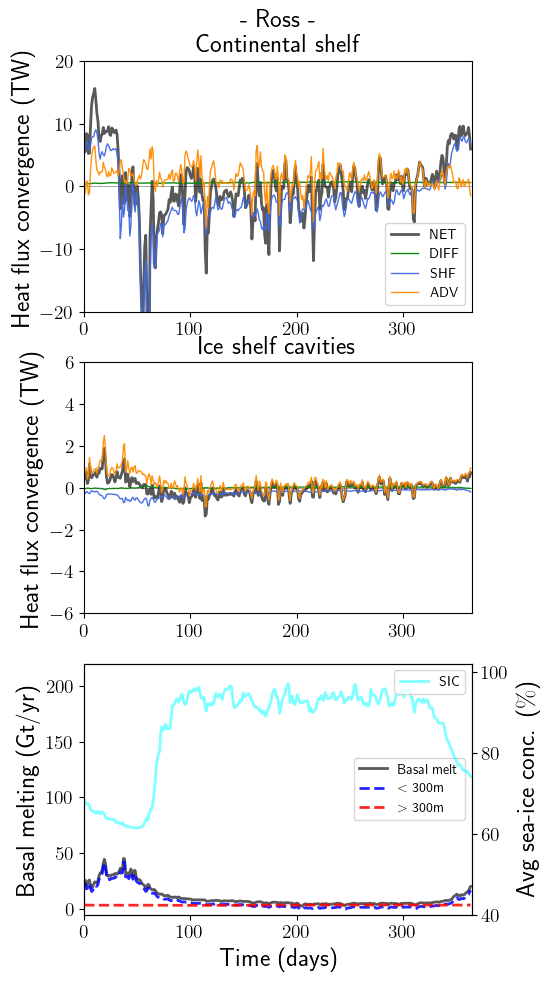

In [51]:
rho_ice=916
Melt_fac=rho_ice*1e-12 # convert to Gigatonne (=1e12 kg)

plt.rc('text', usetex=True)

## loop through sub-regions:

for ii in range(0,12):
# ii=0

    sind = sind_subreg[ii]
    eind = eind_subreg[ii]
    
    # fig = plt.figure(figsize=(8,15))
    fig = plt.figure(figsize=(5,15))

    ax1 = fig.add_subplot(4,1,1, frameon=True)
    ax1.plot(np.arange(0,365,1),W4avg_net.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*0,'-0',color='gray',linewidth=0.5)
    ax1.plot(np.arange(0,365,1),W4avg_net.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*1e-12,'-',color='k',label='NET', alpha=0.65, linewidth=2)   
    ax1.plot(np.arange(0,365,1),W4avg_hdiff.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*1e-12,'-',color='green',label='DIFF', alpha=0.95, linewidth=1)
    ax1.plot(np.arange(0,365,1),W4avg_vdiff.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*1e-12,'-',color='royalblue',label='SHF', alpha=0.95, linewidth=1)
    ax1.plot(np.arange(0,365,1),W4avg_hadv.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*1e-12,'-',color='darkorange',label='ADV', alpha=0.95, linewidth=1)
    ax1.legend(loc='lower right')
    ax1.set_title(' - ' + names_subreg[ii] + ' - \n Continental shelf',fontsize=18)
    ax1.set_ylim(-20,20)
    ax1.set_ylabel('Heat flux convergence (TW)',fontsize=18)
    ax1.set_xlim(0,365)
    ax1.tick_params(axis='x',labelsize=14)
    ax1.tick_params(axis='y',labelsize=14)
    
    ax1 = fig.add_subplot(4,1,2, frameon=True)
    ax1.plot(np.arange(0,365,1),W4avg_net.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*0,'-0',color='gray',linewidth=0.5)
    ax1.plot(np.arange(0,365,1),W4avg_net_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*1e-12,'-',color='k',label='NET', alpha=0.65, linewidth=2)
    ax1.plot(np.arange(0,365,1),W4avg_hdiff_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*1e-12,'-',color='green',label='DIFF', alpha=0.89, linewidth=1)
    ax1.plot(np.arange(0,365,1),W4avg_vdiff_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*1e-12,'-',color='royalblue',label='SHF', alpha=0.95, linewidth=1)
    ax1.plot(np.arange(0,365,1),W4avg_hadv_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*1e-12,'-',color='darkorange',label='ADV', alpha=0.95, linewidth=1)
    ax1.set_title('Ice shelf cavities',fontsize=18)
    ax1.set_ylim(-6,6)
    ax1.set_ylabel('Heat flux convergence (TW)',fontsize=18)
    ax1.set_xlim(0,365)
    ax1.tick_params(axis='x',labelsize=14)
    ax1.tick_params(axis='y',labelsize=14)
    
    ax2 = fig.add_subplot(4,1,3, frameon=True)
    ax2.plot(np.arange(0,365,1),W4avg_bmelt.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*Melt_fac,'-',color='k',label='Basal melt', alpha=0.65, linewidth=2)
    ax2.plot(np.arange(0,365,1),W4avg_bmelt_shallow.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*Melt_fac,'--',color='b',label='$<$ 300m', alpha=0.85, linewidth=2)
    ax2.plot(np.arange(0,365,1),W4avg_bmelt_deep.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*Melt_fac,'--',color='r',label='$>$ 300m', alpha=0.85, linewidth=2)
    ax2.set_ylabel('Basal melting (Gt/yr)',fontsize=18)
    # ax2.set_ylim(0,max_BM[ii])
    ax2.set_ylim(-5,220)
    ax2.legend(loc='center right')
    ax2.tick_params(axis='x',labelsize=14)
    ax2.tick_params(axis='y',labelsize=14)    
    
    ax2b = ax2.twinx()
    ax2b.plot(np.arange(0,365,1),SIC_bin.isel(lon_bins=slice(sind,eind)).mean('lon_bins')*100,'-',color='cyan',label='SIC',alpha=0.5, linewidth=2) #*100 to convert to %
    ax2b.set_ylabel('Avg sea-ice conc. ($\%$)',fontsize=18)
    ax2b.legend(loc='upper right')
    ax2.set_xlabel('Time (days)',fontsize=18)
    ax2.set_xlim(0,365)
    if ii==3 or ii==10 or ii==11:
        ax2b.set_ylim(40,102)
    else:
        ax2b.set_ylim(80,102)
    ax2b.tick_params(axis='x',labelsize=14)
    ax2b.tick_params(axis='y',labelsize=14)
    
    ## TWIN axis with basal melt? or maybe (Basal melt + SIC) and (Wind stress + SAT)?
# WSmgn[0,:,:]*mask_LonBins_4km[ii,:]
    # ax3 = fig.add_subplot(4,1,4, frameon=True)
    # # ax3.plot(np.arange(0,365,1),WS_masked.mean('eta').mean('xi').isel(slice(sind,eind)),
    #          '-',color='b', linewidth=2)
    # ax3.set_ylabel('Wind stress magnitude (m/yr)')
    # ax3.set_ylim(0,max_BM[ii])
    # # figure out units basal melting is wrong ->>> need to divided by area_sum masked for each 3deg-sector!!!!
    # ax3.set_xlabel('Time (days)')
    # ax3.set_xlim(0,365)

    name_fig='waom4_lonbin_'+ names_subreg[ii]+'_300m_b_yr10-12.png'
    # name_fig='waom4_lonbin_'+ names_subreg[ii]+'_300m_yr10-12.png'
    plt.savefig(fig_path + name_fig, dpi=300, bbox_inches='tight', facecolor='white')
    # plt.show()

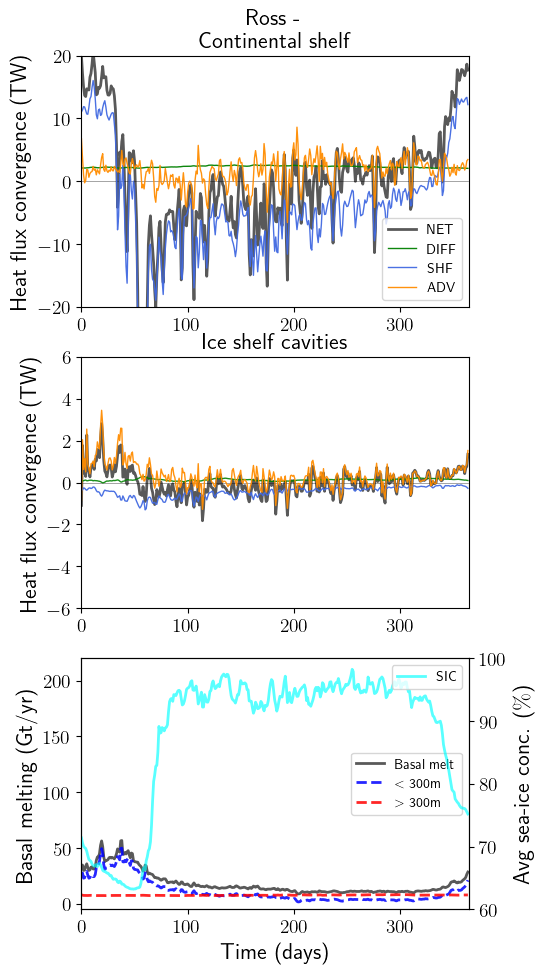

In [58]:
#### Plot Ross1+Ross2:
## Plot Ross1 + Ross2:

rho_ice=916
Melt_fac=rho_ice*1e-12 # convert to Gigatonne (=1e12 kg)


## define Ross = ross1 + ross2 sections:

ii=11
sind = sind_subreg[ii]
eind = eind_subreg[ii]
Net_1 = W4avg_net.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Adv_1 = W4avg_hadv.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Diff_1 = W4avg_hdiff.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Sfc_1 = W4avg_vdiff.isel(lon_bins=slice(sind,eind)).sum('lon_bins')

Net_is_1 = W4avg_net_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Adv_is_1 = W4avg_hadv_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Diff_is_1 = W4avg_hdiff_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Sfc_is_1 = W4avg_vdiff_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Melt_1 = W4avg_bmelt.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Melt_1s = W4avg_bmelt_shallow.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Melt_1d = W4avg_bmelt_deep.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
SIC_1 = SIC_bin.isel(lon_bins=slice(sind,eind)).mean('lon_bins')

ii=12
sind = sind_subreg[ii]
eind = eind_subreg[ii]
Net_2 = W4avg_net.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Adv_2 = W4avg_hadv.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Diff_2 = W4avg_hdiff.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Sfc_2 = W4avg_vdiff.isel(lon_bins=slice(sind,eind)).sum('lon_bins')

Net_is_2 = W4avg_net_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Adv_is_2 = W4avg_hadv_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Diff_is_2 = W4avg_hdiff_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Sfc_is_2 = W4avg_vdiff_is.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Melt_2 = W4avg_bmelt.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Melt_2s = W4avg_bmelt_shallow.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
Melt_2d = W4avg_bmelt_deep.isel(lon_bins=slice(sind,eind)).sum('lon_bins')
SIC_2 = SIC_bin.isel(lon_bins=slice(sind,eind)).mean('lon_bins')

Net = Net_1+Net_2
Adv = Adv_1+Adv_2
Diff = Diff_1+Diff_2
Sfc = Sfc_1+Sfc_2

Net_is = Net_is_1+Net_is_2
Adv_is = Adv_is_1+Adv_is_2
Diff_is = Diff_is_1+Diff_is_2
Sfc_is = Sfc_is_1+Sfc_is_2
Melt = Melt_1 + Melt_2
Melt_shallow = Melt_1s + Melt_2s
Melt_deep = Melt_1d + Melt_2d
SIC = np.divide(SIC_1 + SIC_2,2) # SIC for ROSS unified needs to take the average between the 2 regions:

## loop through sub-regions:

# fig = plt.figure(figsize=(8,15))
fig = plt.figure(figsize=(5,15))

# plt.rcParams.update({
#     "text.usetex": True,
#     "font.family": "Helvetica"
# })

ax1 = fig.add_subplot(4,1,1, frameon=True)
ax1.plot(np.arange(0,365,1),Net*0,'-0',color='gray',linewidth=0.5)
ax1.plot(np.arange(0,365,1),Net*1e-12,'-',color='k',label='NET', alpha=0.65, linewidth=2)   
ax1.plot(np.arange(0,365,1),Diff*1e-12,'-',color='green',label='DIFF', alpha=0.95, linewidth=1)
ax1.plot(np.arange(0,365,1),Sfc*1e-12,'-',color='royalblue',label='SHF', alpha=0.95, linewidth=1)
ax1.plot(np.arange(0,365,1),Adv*1e-12,'-',color='darkorange',label='ADV', alpha=0.95, linewidth=1)
ax1.legend(loc='lower right')
ax1.set_title('Ross - \n Continental shelf',fontsize=16)
ax1.set_ylim(-20,20)
ax1.set_ylabel('Heat flux convergence (TW)',fontsize=16)
ax1.set_xlim(0,365)
ax1.tick_params(axis='x',labelsize=14)
ax1.tick_params(axis='y',labelsize=14)

ax1 = fig.add_subplot(4,1,2, frameon=True)
ax1.plot(np.arange(0,365,1),Net*0,'-0',color='gray',linewidth=0.5)
ax1.plot(np.arange(0,365,1),Net_is*1e-12,'-',color='k',label='NET', alpha=0.65, linewidth=2)
ax1.plot(np.arange(0,365,1),Diff_is*1e-12,'-',color='green',label='DIFF', alpha=0.89, linewidth=1)
ax1.plot(np.arange(0,365,1),Sfc_is*1e-12,'-',color='royalblue',label='SHF', alpha=0.95, linewidth=1)
ax1.plot(np.arange(0,365,1),Adv_is*1e-12,'-',color='darkorange',label='ADV', alpha=0.95, linewidth=1)
ax1.set_title('Ice shelf cavities',fontsize=16)
ax1.set_ylim(-6,6)
ax1.set_ylabel('Heat flux convergence (TW)',fontsize=16)
ax1.set_xlim(0,365)
ax1.tick_params(axis='x',labelsize=14)
ax1.tick_params(axis='y',labelsize=14)

ax2 = fig.add_subplot(4,1,3, frameon=True)
ax2.plot(np.arange(0,365,1),Melt*Melt_fac,'-',color='k',label='Basal melt', alpha=0.65, linewidth=2)
ax2.plot(np.arange(0,365,1),Melt_shallow*Melt_fac,'--',color='b',label=r"$<$ 300m", alpha=0.85, linewidth=2)
ax2.plot(np.arange(0,365,1),Melt_deep*Melt_fac,'--',color='r',label=r"$>$ 300m", alpha=0.85, linewidth=2)
ax2.set_ylabel('Basal melting (Gt/yr)',fontsize=16)
# ax2.set_ylim(0,max_BM[ii])
ax2.set_ylim(-5,220)
ax2.legend(loc='center right')
ax2.tick_params(axis='x',labelsize=14)
ax2.tick_params(axis='y',labelsize=14)

ax2b = ax2.twinx()
ax2b.plot(np.arange(0,365,1),SIC*100,'-',color='cyan',label='SIC',alpha=0.65, linewidth=2) #*100 to convert to %
ax2b.set_ylabel('Avg sea-ice conc. ($\%$)',fontsize=16)
ax2b.legend(loc='upper right')
ax2.set_xlabel('Time (days)',fontsize=16)
ax2.set_xlim(0,365)
# if ii==3 or ii==5 or ii==10 or ii==11:
ax2b.set_ylim(60,100)
ax2b.tick_params(axis='x',labelsize=14)
ax2b.tick_params(axis='y',labelsize=14)

name_fig='waom4_lonbin_Ross_unif_300m_b_yr10-12.png'
plt.savefig(fig_path + name_fig, dpi=300, bbox_inches='tight', facecolor='white')
# plt.show()

In [54]:
W4avg_bmelt_shallow

<xarray.DataArray '__xarray_dataarray_variable__' (ocean_time: 365,
                                                   lon_bins: 141)> Size: 412kB
dask.array<transpose, shape=(365, 141), dtype=float64, chunksize=(365, 141), chunktype=numpy.ndarray>
Coordinates:
  * lon_bins    (lon_bins) float64 1kB -178.5 -175.5 -172.5 ... 175.5 178.5
  * ocean_time  (ocean_time) float64 3kB 0.0 0.03288 0.06575 ... 11.93 11.97

### figure 4,5 maps style:

In [53]:
## Re-map u/v for plotting:
# call cartopy projectione
proj = ccrs.PlateCarree()

# re-gridding
src = ccrs.PlateCarree()
nx, ny = 1575,1400

scale = 1e7
xs = np.linspace(-scale, scale, nx)
ys = np.linspace(-scale, scale, ny)

xs, ys = np.meshgrid(xs, ys)

In [56]:
annual_T = temp3d_4km_clim.mean('month')
annual_Z = z_rho3d_4km_clim.mean('month')

sum_T = (temp3d_4km_clim.isel(month=0)+273.15) - (temp3d_4km_clim.mean('month')+273.15) #  Jan - Annual (+ means summer is warmer than mean)
# sum_S = (salt3d_4km_clim.isel(month=0))
sum_Z = z_rho3d_4km_clim.isel(month=0)

win_T = (temp3d_4km_clim.isel(month=6)+273.15) - (temp3d_4km_clim.mean('month')+273.15) # July - Anual (- mean winter is colder...)
# win_S = salt3d_4km_clim.isel(month=6)
win_Z = z_rho3d_4km_clim.isel(month=6)


In [75]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
#%%time # being done by WAOM4_run_maps_Figure4_newTS.py offline. # This test SUM = DEC-APR (need to concat!!) and WIN = MAY-NOV

## this piece do the maps for Figure 4 (containing annual temp, anom 1month in summer, anom 1 month in winter) + TS-diag for 2 regions (totten x PIG) at SURFACE, MID-DEPTH, BOTTOM sigma layers

slayer=[15, -1, 0]
zname =['Mid-depth','Surface','Bottom']
pname =['mid-depth','surface','bottom']
anomlim=[0.5, 2, 0.5]

for dd in np.arange(2,3):
    # dd=2
    
    mm=1 # So sum_MM=February (2nd month) and win_MM=August (8th month)
    sum_MM=mm
    win_MM=mm+6
    # sum_MM = slice(0,3)
    # win_MM = slice(4,10)
    
    # define subregion:
    # names_subreg = ['Sulzberger','Getz','Thwaites-PIG','Bellingshausen','FRIS',
                   # 'Fimbul','Amery','Shackleton','Totten','Mertz','Ross1','Ross2']
    
    for rr in range(8,9):
        Pname = names_subreg[rr]

        # define 2d Map vars for plottins: annual, summer month, winter month
        annual_T = temp3d_4km_clim.mean('month')
        # annual_S = salt3d_4km.mean('month')
        annual_Z = z_rho3d_4km_clim.mean('month')
        annual_melt = melt_4km_clim.mean('month')*Melt_fac

        sum_Ta = (temp3d_4km_clim.isel(month=sum_MM)+273.15) - (temp3d_4km_clim.mean('month')+273.15) #  Jan - Annual (+ means summer is warmer than mean)
        sum_T = (temp3d_4km_clim.isel(month=sum_MM))
        # sum_S = (salt3d_4km.isel(month=sum_MM))
        sum_Z = z_rho3d_4km_clim.isel(month=sum_MM)

        # sum_U = (u_rho_i[sum_MM,:,:])
        # sum_V = (v_rho_i[sum_MM,:,:])
        sum_melt = melt_4km_clim.isel(month=sum_MM)*Melt_fac
        sum_melt_anom = sum_melt - annual_melt
        
        win_Ta = (temp3d_4km_clim.isel(month=win_MM)+273.15) - (temp3d_4km_clim.mean('month')+273.15) # Jul - Anual (- mean winter is colder...)
        win_T = (temp3d_4km_clim.isel(month=win_MM))
        # win_S = (salt3d_4km_clim.isel(month=win_MM))
        win_Z = z_rho3d_4km_clim.isel(month=win_MM)
        # win_U = (u_rho_i[win_MM,:,:])
        # win_V = (v_rho_i[win_MM,:,:])
        win_melt = melt_4km_clim.isel(month=win_MM)*Melt_fac
        win_melt_anom = win_melt - annual_melt

        # shflux
        annual_shf = shflux_4km_clim.mean('month')
        sum_shf = shflux_4km_clim.isel(month=sum_MM)
        win_shf = shflux_4km_clim.isel(month=win_MM)
    
        # get map limits: 
        LonMin=map_limits[rr][0]
        LonMax=map_limits[rr][1]
        LatMin=map_limits[rr][2]
        LatMax=map_limits[rr][3]
            
    
        #### TS-diag related definitions (along the calving front):
        # 2 - sum individual bins:
        mask_LonBins_tmp = mask_LonBins_4km[sind_subreg[rr]:eind_subreg[rr],:]
        mask_LonBins_tmp = np.nansum(mask_LonBins_tmp, axis=0)

        # 3 - multiply ice shelves mask (masked outside it) and Lon Bins:
        newmask_bin = w4_mask_outiceshelf*mask_LonBins_tmp
        # 3b - mask out values that are 0
        mask = (newmask_bin == 1)
        newmask_bin = np.where(mask, newmask_bin, np.nan)  # Replace masked values with NaN

        # 4 - define T/S/Z variables for the TS-plot:
## Annual
        temp_masked_ann = newmask_bin*annual_T
        # salt_masked_ann = newmask_bin*annual_S
        Z_masked_ann = newmask_bin*annual_Z.transpose('s_rho','eta_rho','xi_rho')
        # 5 -filter & stack example:
        # 5a - Flatten the 3D array to 2D while removing NaNs
        flat_temp_ann = temp_masked_ann.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
        flat_salt_ann = salt_masked_ann.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
        flat_z_rho_ann = Z_masked_ann.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
        non_nan_mask = ~np.isnan(flat_temp_ann)
        # 5b -Filter out NaN values
        filt_temp_ann = flat_temp_ann[non_nan_mask]
        filt_salt_ann = flat_salt_ann[non_nan_mask]
        filt_z_rho_ann = flat_z_rho_ann[non_nan_mask]
## Summer:
        # 4 - define T/S/Z variables for the TS-plot:
        temp_masked_sum = newmask_bin*sum_T
        salt_masked_sum = newmask_bin*sum_S
        Z_masked_sum = newmask_bin*sum_Z.transpose('s_rho','eta_rho','xi_rho')
        # 5 -filter & stack example:
        # 5a - Flatten the 3D array to 2D while removing NaNs
        flat_temp_sum = temp_masked_sum.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
        flat_salt_sum = salt_masked_sum.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
        flat_z_rho_sum = Z_masked_sum.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
        non_nan_mask = ~np.isnan(flat_temp_sum)
        # 5b -Filter out NaN values
        filt_temp_sum = flat_temp_sum[non_nan_mask]
        filt_salt_sum = flat_salt_sum[non_nan_mask]
        filt_z_rho_sum = flat_z_rho_sum[non_nan_mask]
## Winter:
        # 4 - define T/S/Z variables for the TS-plot:
        temp_masked_win = newmask_bin*win_T
        salt_masked_win = newmask_bin*win_S
        Z_masked_win = newmask_bin*win_Z.transpose('s_rho','eta_rho','xi_rho')
        # 5 -filter & stack example:
        # 5a - Flatten the 3D array to 2D while removing NaN
        flat_temp_win = temp_masked_win.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
        flat_salt_win = salt_masked_win.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
        flat_z_rho_win = Z_masked_win.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
        non_nan_mask = ~np.isnan(flat_temp_win)
        # 5b -Filter out NaN values
        filt_temp_win = flat_temp_win[non_nan_mask]
        filt_salt_win = flat_salt_win[non_nan_mask]
        filt_z_rho_win = flat_z_rho_win[non_nan_mask]
        
        proj_v = ccrs.PlateCarree()
        proj = ccrs.PlateCarree(central_longitude=0)#-24)
        proj_v2 = ccrs.SouthPolarStereo()
        proj2 = ccrs.SouthPolarStereo()
        
        # fig = plt.figure(figsize=(15,8))
        fig = plt.figure(figsize=(14,10))
        
    
        # if Ross, need to use proj2!
        if rr>10:
            PROJ=proj2
            PROJV=proj_v2
        else:
            PROJ=proj
            PROJV=proj_v
        PROJN=proj_v
        
        ax2 = fig.add_subplot(3,4,5, projection=PROJ) # Anual    
        ct=ax2.pcolormesh(lon_rho_4km,lat_rho_4km,annual_T.isel(s_rho=slayer[dd]).values,
                       vmin=-3, vmax=3 ,cmap=cmocean.cm.thermal, transform=PROJN) 
        
        cm=ax2.pcolormesh(lon_rho_4km,lat_rho_4km,
                       ma.masked_where(contour_masked_above_CF_4km == -1000, annual_melt),
                       transform=PROJN, vmin=-8, vmax=8, cmap='bwr') #, cmap=cmocean.cm.balance
                          
        # ax2.quiver(lon_rho_4km[::5,::5],lat_rho_4km[::5,::5],
        #            np.mean(u_rho_i[:,slayer[dd],::5,::5],axis=0),
        #            np.mean(v_rho_i[:,slayer[dd],::5,::5],axis=0),scale=5,transform=PROJV)
        ax2.set_title(names_subreg[rr] + '\n' + zname[dd] + ': Annual mean')
        ax2.set_extent([LonMin, LonMax, LatMin, LatMax], crs=PROJN) # Getz
        x_left, x_right = ax2.get_xlim()
        y_low, y_high = ax2.get_ylim()
        ratio = .8
        ax2.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)
        gl=ax2.gridlines(draw_labels=True,linewidth=.1)
        gl.top_labels=False   # suppress top labels
        gl.right_labels=False   # suppress right labels
        gl.left_labels=False   
        plt.scatter(lon_along_4km,lat_along_4km, s=.8, alpha=0.2, color='gold',label='1500m isobath', transform=PROJN);
        ax2.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
        
        ax2 = fig.add_subplot(2,4,2, projection=PROJ) # jan, TEMP ANOM
        cta=ax2.pcolormesh(lon_rho_4km,lat_rho_4km,sum_Ta.isel(s_rho=slayer[dd]),
                       vmin=-anomlim[dd], vmax=anomlim[dd] ,cmap='twilight_shifted', transform=PROJN) 
        cma=ax2.pcolormesh(lon_rho_4km,lat_rho_4km,
                       ma.masked_where(contour_masked_above_CF_4km == -1000, sum_melt),
                       transform=PROJN, vmin=-8, vmax=8, cmap='bwr') #, cmap=cmocean.cm.balance  
        # ax2.quiver(lon_rho_4km[::5,::5],lat_rho_4km[::5,::5],sum_U[slayer[dd],::5,::5],sum_V[slayer[dd],::5,::5],scale=5,transform=PROJV)
        ax2.set_title('Temperature anomaly \n Summer')
        ax2.set_extent([LonMin, LonMax, LatMin, LatMax], crs=PROJN) # Getz
        x_left, x_right = ax2.get_xlim()
        y_low, y_high = ax2.get_ylim()
        ratio = .8
        ax2.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)
        gl=ax2.gridlines(draw_labels=True,linewidth=.1)
        gl.top_labels=False   # suppress top labels
        gl.right_labels=False   # suppress right labels
        plt.scatter(lon_along_4km,lat_along_4km, s=.8, alpha=0.2, color='gold',label='1500m isobath', transform=PROJN);
        ax2.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
        
        ax2 = fig.add_subplot(2,4,3, projection=PROJ) # SHFLUX
        cts=ax2.pcolormesh(lon_rho_4km,lat_rho_4km,sum_shf,
                       vmin=-100, vmax=100 ,cmap=cmocean.cm.curl, transform=PROJN) 
        cma=ax2.pcolormesh(lon_rho_4km,lat_rho_4km,
                       ma.masked_where(contour_masked_above_CF_4km == -1000, sum_melt_anom),
                       transform=PROJN, vmin=-5, vmax=5, cmap='bwr') #, cmap=cmocean.cm.balance  
        # ax2.quiver(lon_rho_4km[::5,::5],lat_rho_4km[::5,::5],sum_U[slayer[dd],::5,::5],sum_V[slayer[dd],::5,::5],scale=5,transform=PROJV)
        ax2.set_title('Sfc heat flux  \n Summer')
        # ax2.set_extent([-135, -75, -76, -69], crs=ccrs.PlateCarree()) # PIG-Thwaites region
        ax2.set_extent([LonMin, LonMax, LatMin, LatMax], crs=PROJN) # Getz
        x_left, x_right = ax2.get_xlim()
        y_low, y_high = ax2.get_ylim()
        ratio = .8
        ax2.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)
        gl=ax2.gridlines(draw_labels=True,linewidth=.1)
        gl.top_labels=False   # suppress top labels
        gl.right_labels=False   # suppress right labels
        plt.scatter(lon_along_4km,lat_along_4km, s=.8, alpha=0.2, color='gold',label='1500m isobath', transform=PROJN);
        ax2.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
        
        ax2 = fig.add_subplot(2,4,6, projection=PROJ) # july temp anom
        cta=ax2.pcolormesh(lon_rho_4km,lat_rho_4km,win_Ta.isel(s_rho=slayer[dd]),
                       vmin=-anomlim[dd], vmax=anomlim[dd] ,cmap='twilight_shifted', transform=PROJN) 
        cm=ax2.pcolormesh(lon_rho_4km,lat_rho_4km,
                       ma.masked_where(contour_masked_above_CF_4km == -1000, win_melt),
                       transform=PROJN, vmin=-8, vmax=8, cmap='bwr') #, cmap=cmocean.cm.balance  
        # ax2.quiver(lon_rho_4km[::5,::5],lat_rho_4km[::5,::5],
        #            win_U[slayer[dd],::5,::5],
        #            win_V[slayer[dd],::5,::5],scale=5,transform=PROJV)
        ax2.set_title('Temperature anomaly \n Winter')
        # ax2.set_extent([-135, -75, -76, -69], crs=ccrs.PlateCarree()) # PIG-Thwaites region
        ax2.set_extent([LonMin, LonMax, LatMin, LatMax], crs=PROJN) # Getz
        x_left, x_right = ax2.get_xlim()
        y_low, y_high = ax2.get_ylim()
        ratio = .8
        ax2.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)
        gl=ax2.gridlines(draw_labels=True,linewidth=.1)
        gl.top_labels=False   # suppress top labels
        gl.right_labels=False   # suppress right labels
        plt.scatter(lon_along_4km,lat_along_4km, s=.8, alpha=0.2, color='gold',label='1500m isobath', transform=PROJN);
        ax2.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
        
        ax2 = fig.add_subplot(2,4,7, projection=PROJ) # SHFLX
        cts=ax2.pcolormesh(lon_rho_4km,lat_rho_4km,win_shf,
                       vmin=-100, vmax=100 ,cmap=cmocean.cm.curl, transform=PROJN) 
        cma=ax2.pcolormesh(lon_rho_4km,lat_rho_4km,
                       ma.masked_where(contour_masked_above_CF_4km == -1000, win_melt_anom),
                       transform=PROJN, vmin=-5, vmax=5, cmap='bwr') #, cmap=cmocean.cm.balance  
        # ax2.quiver(lon_rho_4km[::5,::5],lat_rho_4km[::5,::5],
        #            win_U[slayer[dd],::5,::5],
        #            win_V[slayer[dd],::5,::5],scale=5,transform=PROJV)
        ax2.set_title('Sfc heat flux \n Winter')
        ax2.set_extent([LonMin, LonMax, LatMin, LatMax], crs=PROJN) # Getz
        x_left, x_right = ax2.get_xlim()
        y_low, y_high = ax2.get_ylim()
        ratio = .8
        ax2.set_aspect(abs((x_right-x_left)/(y_low-y_high))*ratio)
        gl=ax2.gridlines(draw_labels=True,linewidth=.1)
        gl.top_labels=False   # suppress top labels
        gl.right_labels=False   # suppress right labels
        plt.scatter(lon_along_4km,lat_along_4km, s=.8, alpha=0.2, color='gold',label='1500m isobath', transform=PROJN);
        ax2.add_feature(cfeature.LAND, zorder=3, facecolor='darkgray',edgecolor='white')
        
        
        ax3 = fig.add_subplot(2,4,4)
        cd = ax3.scatter(filt_salt_ann, filt_temp_ann, c='lightgray', s=(22/fig.dpi)**2)
        c = ax3.scatter(filt_salt_sum, filt_temp_sum, c=-filt_z_rho_sum, s=(22/fig.dpi)**2,
                        marker="o", cmap=cmocean.cm.deep, vmin=0, vmax=900)
        # c = ax3.scatter(sum_S*Mask_tmp_subr,sum_T*Mask_tmp_subr,c=-sum_Z*Mask_tmp_subr, s=(22/fig.dpi)**2, 
        #                         marker="o", cmap=cmocean.cm.deep, vmin=0, vmax=900)
        ax3.set_title('TS-diagram - Summer')
        ax3.set_xlim([34,35])
        ax3.set_ylim([-2.5,.5])
        # ax3.legend()
        # ax3.set_ylabel('Temperature ($^\circ$C)')
        ax3.set_aspect(0.32)
        
        ax3 = fig.add_subplot(2,4,8)
        cd = ax3.scatter(filt_salt_ann, filt_temp_ann, c='lightgray', s=(22/fig.dpi)**2)
        c = ax3.scatter(filt_salt_win, filt_temp_win, c=-filt_z_rho_win, s=(22/fig.dpi)**2,
                        marker="o", cmap=cmocean.cm.deep, vmin=0, vmax=900)
        # c = ax3.scatter(win_S*Mask_tmp_subr,win_T*Mask_tmp_subr,c=-win_Z*Mask_tmp_subr, s=(22/fig.dpi)**2, 
        #                         marker="o", cmap=cmocean.cm.deep, vmin=0, vmax=900)
        ax3.set_title('TS-diagram - Winter')
        ax3.set_xlim([34,35])
        ax3.set_ylim([-2.5,.5])
        # ax3.legend()
        # ax3.set_ylabel('Temperature ($^\circ$C)')
        ax3.set_aspect(0.32)
        
        
        cbar_ax1 = fig.add_axes([0.07, 0.42,  0.006, 0.18])
        fig.colorbar(ct, cax=cbar_ax1, orientation='vertical')
        cbar_ax1.set_ylabel('Temperature ($^{\circ}$C)')#, labelpad=-35)
        
        cbar_ax12 = fig.add_axes([0.13, 0.365,  0.16, 0.01])
        fig.colorbar(cm, cax=cbar_ax12, orientation='horizontal')
        cbar_ax12.set_xlabel('Melt rate (m/yr)')#, labelpad=-35)
        
        cbar_ax2 = fig.add_axes([0.33, 0.525,  0.16, 0.01])
        fig.colorbar(cta, cax=cbar_ax2, orientation='horizontal')
        cbar_ax2.set_xlabel('Temperature anomaly ($^{\circ}$C)')#, labelpad=-35)
        
        cbar_ax3 = fig.add_axes([0.53, 0.555,  0.16, 0.01]) 
        fig.colorbar(cts, cax=cbar_ax3, orientation='horizontal')
        cbar_ax3.set_xlabel('Surface heat flux (W m$^{-2}$)')#, labelpad=-35)
        
        cbar_ax3b = fig.add_axes([0.53, 0.48,  0.16, 0.01]) 
        fig.colorbar(cma, cax=cbar_ax3b, orientation='horizontal')
        cbar_ax3b.set_xlabel('Melt rate anomaly (m/yr)')
        
        cbar_ax1 = fig.add_axes([0.735, 0.525,  0.16, 0.01])
        fig.colorbar(c, cax=cbar_ax1, orientation='horizontal')
        cbar_ax1.set_xlabel('Temperature-Salinity diagram; Depth (m)')#, labelpad=-35)
            
        # name_fig='waom4_MapsT+SHF_season_' + pname[dd] + '_' + Pname +'_tsts.png'
        # plt.savefig(fig_path + name_fig, dpi=600, bbox_inches='tight')

KeyboardInterrupt: 

### Figure 6 (transects, addressing Reviewer #2):

In [78]:
## Totten:
t1x = [1308,1375]
t1y = 455
t2x = 1320
t2y = [360,490]

# Using avg summer/winter
Ttemp_aug1 = temp3d_4km_clim.isel(month=slice(5,7),xi_rho=slice(t1x[0],t1x[1]),eta_rho=t1y).mean('month')
Tz_aug1 = z_rho3d_4km_clim.isel(month=slice(5,7),xi_rho=slice(t1x[0],t1x[1]),eta_rho=t1y).mean('month').transpose()
Tlat_tmp1 = lat_rho_4km.isel(xi_rho=slice(t1x[0],t1x[1]),eta_rho=t1y)
# Replicate latitude array across the longitude dimension to match the shape of the data
Tlat_rep1 = np.tile(Tlat_tmp1.values[:, np.newaxis], (1, 31)).transpose()

# section1 february
Ttemp_feb1 = temp3d_4km_clim.isel(month=slice(0,2),xi_rho=slice(t1x[0],t1x[1]),eta_rho=t1y).mean('month')
Tz_feb1 = z_rho3d_4km_clim.isel(month=slice(0,2),xi_rho=slice(t1x[0],t1x[1]),eta_rho=t1y).mean('month').transpose()

# Using avg summer/winter
Ttemp_aug2 = temp3d_4km_clim.isel(month=slice(5,7),xi_rho=t2x,eta_rho=slice(t2y[0],t2y[1])).mean('month')
Tz_aug2 = z_rho3d_4km_clim.isel(month=slice(5,7),xi_rho=t2x,eta_rho=slice(t2y[0],t2y[1])).mean('month').transpose()
Tlat_tmp2 = lat_rho_4km.isel(xi_rho=t2x,eta_rho=slice(t2y[0],t2y[1]))
# Replicate latitude array across the longitude dimension to match the shape of the data
Tlat_rep2 = np.tile(Tlat_tmp2.values[:, np.newaxis], (1, 31)).transpose()

# section2 february
Ttemp_feb2 = temp3d_4km_clim.isel(month=slice(0,2),xi_rho=t2x,eta_rho=slice(t2y[0],t2y[1])).mean('month')
Tz_feb2 = z_rho3d_4km_clim.isel(month=slice(0,2),xi_rho=t2x,eta_rho=slice(t2y[0],t2y[1])).mean('month').transpose()


In [79]:
## Getz:
t1x = [300,387]
t1y = 505
t2x = 400
t2y = [430,520]

# section1 august
Gtemp_aug1 = temp3d_4km_clim.isel(month=slice(5,7),eta_rho=t1y, xi_rho=slice(t1x[0],t1x[1])).mean('month')
Gz_aug1 = z_rho3d_4km_clim.isel(month=slice(5,7),eta_rho=t1y, xi_rho=slice(t1x[0],t1x[1])).mean('month').transpose()
Glat_tmp1 = lat_rho_4km.isel(eta_rho=t1y, xi_rho=slice(t1x[0],t1x[1]))

# Replicate latitude array across the longitude dimension to match the shape of the data
Glat_rep1 = np.tile(Glat_tmp1.values[:, np.newaxis], (1, 31)).transpose()

# section1 february
Gtemp_feb1 = temp3d_4km_clim.isel(month=slice(0,2),eta_rho=t1y, xi_rho=slice(t1x[0],t1x[1])).mean('month')
Gz_feb1 = z_rho3d_4km_clim.isel(month=slice(0,2),eta_rho=t1y, xi_rho=slice(t1x[0],t1x[1])).mean('month').transpose()

# section2 august
Gtemp_aug2 = temp3d_4km_clim.isel(month=slice(5,7),eta_rho=slice(t2y[0],t2y[1]), xi_rho=t2x).mean('month')
Gz_aug2 = z_rho3d_4km_clim.isel(month=slice(5,7),eta_rho=slice(t2y[0],t2y[1]), xi_rho=t2x).mean('month').transpose()
Glat_tmp2 = lat_rho_4km.isel(eta_rho=slice(t2y[0],t2y[1]), xi_rho=t2x)
# Replicate latitude array across the longitude dimension to match the shape of the data
Glat_rep2 = np.tile(Glat_tmp2.values[:, np.newaxis], (1, 31)).transpose()

# section2 august
Gtemp_feb2 = temp3d_4km_clim.isel(month=slice(0,2),eta_rho=slice(t2y[0],t2y[1]), xi_rho=t2x).mean('month')
Gz_feb2 = z_rho3d_4km_clim.isel(month=slice(0,2),eta_rho=slice(t2y[0],t2y[1]), xi_rho=t2x).mean('month').transpose()


/g/data/gv90/fbd581/ROMS/postprocessing/figs/OHB_shelf/waom4_temp_transects_Getz-Totten_yr10-12.png


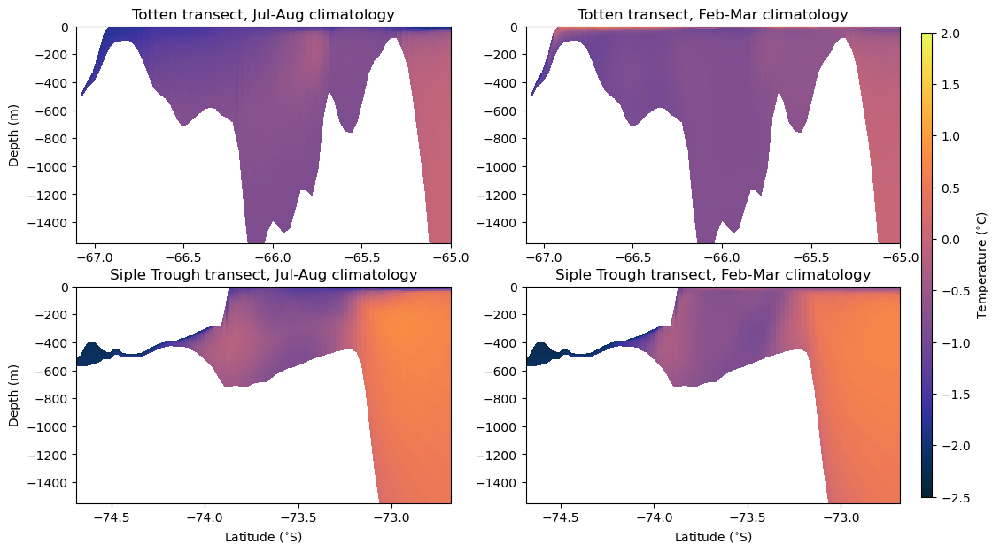

In [80]:
tmin=-2.5
tmax=2.

fig = plt.figure(figsize=(12,7))

ax1 = fig.add_subplot(221)
ct=plt.pcolormesh(Tlat_rep1, Tz_aug1, Ttemp_aug1,cmap=cmocean.cm.thermal, vmin=tmin, vmax=tmax)
plt.ylim(-1550,0)
# plt.colorbar(ct)
ax1.set_title('Totten transect, Jul-Aug climatology')
ax1.set_ylabel('Depth (m)')
# ax1.set_xlabel('Latitude ($^{\circ}$S)')
ax1.set_xticks([-67,-66.5,-66.,-65.5,-65])
ax1.set_xlim(-67.1,-65)

ax1 = fig.add_subplot(222)
ct=plt.pcolormesh(Tlat_rep1, Tz_feb1, Ttemp_feb1,cmap=cmocean.cm.thermal, vmin=tmin, vmax=tmax)
plt.ylim(-1550,0)
# plt.colorbar(ct)
ax1.set_title('Totten transect, Feb-Mar climatology')
# ax1.set_ylabel('Depth (m)')
# ax1.set_xlabel('Latitude ($^{\circ}$S)')
ax1.set_xticks([-67,-66.5,-66.,-65.5,-65])
ax1.set_xlim(-67.1,-65)

ax1 = fig.add_subplot(223)
ct=plt.pcolormesh(Glat_rep2, Gz_aug2, Gtemp_aug2,cmap=cmocean.cm.thermal, vmin=tmin, vmax=tmax)
plt.ylim(-1550,0)
# plt.colorbar(ct)
ax1.set_title('Siple Trough transect, Jul-Aug climatology')
ax1.set_ylabel('Depth (m)')
ax1.set_xlabel('Latitude ($^{\circ}$S)')
ax1.set_xticks([-74.5,-74,-73.5,-73])

ax1 = fig.add_subplot(224)
ct=plt.pcolormesh(Glat_rep2, Gz_feb2, Gtemp_feb2,cmap=cmocean.cm.thermal, vmin=tmin, vmax=tmax)
plt.ylim(-1550,0)
# plt.colorbar(ct)
ax1.set_title('Siple Trough transect, Feb-Mar climatology')
# ax1.set_ylabel('Depth (m)')
ax1.set_xlabel('Latitude ($^{\circ}$S)')
ax1.set_xticks([-74.5,-74,-73.5,-73])

cbar_ax1 = fig.add_axes([0.92, 0.12,  0.01, 0.75])
fig.colorbar(ct, cax=cbar_ax1, orientation='vertical')
cbar_ax1.set_ylabel('Temperature ($^{\circ}$C)')#, labelpad=-35)


name_fig='waom4_temp_transects_Getz-Totten_yr10-12.png'
plt.savefig(fig_path + name_fig, dpi=300, bbox_inches='tight')
print(fig_path + name_fig)

### TS-diagrams check addressing reviewer #2 comments:

In [ ]:
mm=1 # So sum_MM=February (2nd month) and win_MM=August (8th month)
sum_MM=mm
win_MM=mm+6
# sum_MM = slice(0,3)
# win_MM = slice(4,10)

# define subregion:
#OLD# names_subreg = ['Sulzberger','Getz','Thwaites-PIG','Bellingshausen','FRIS',
               # 'Fimbul','Amery','Shackleton','Totten','Mertz','Ross1','Ross2']
#NEW-May2025#
#names_subreg = ['Sulzberger','Getz','Thwaites-PIG','Bellingshausen','FRIS',
#               'Brunt-Fimbul','Queen Maud Land','Amery-West','Shackleton','Totten','Mertz','Ross1','Ross2']

for rr in range(9,10):
    Pname = names_subreg[rr]

    # define 2d Map vars for plottins: annual, summer month, winter month
    annual_T = temp3d_4km_clim.mean('ocean_time')
    annual_S = salt3d_4km_clim.mean('ocean_time')
    annual_Z = z_rho3d_4km_clim.mean('ocean_time')
    annual_melt = melt_4km_clim.mean('ocean_time')*Melt_fac

    sum_Ta = (temp3d_4km_clim.isel(ocean_time=sum_MM)+273.15) - (temp3d_4km_clim.mean('ocean_time')+273.15) #  Jan - Annual (+ means summer is warmer than mean)
    sum_T = (temp3d_4km_clim.isel(ocean_time=sum_MM))
    sum_S = (salt3d_4km_clim.isel(ocean_time=sum_MM))
    sum_Z = z_rho3d_4km_clim.isel(ocean_time=sum_MM)

    # sum_U = (u_rho_i[sum_MM,:,:])
    # sum_V = (v_rho_i[sum_MM,:,:])
    sum_melt = melt_4km_clim.isel(ocean_time=sum_MM)*Melt_fac

    win_Ta = (temp3d_4km_clim.isel(ocean_time=win_MM)+273.15) - (temp3d_4km_clim.mean('ocean_time')+273.15) # Jul - Anual (- mean winter is colder...)
    win_T = (temp3d_4km_clim.isel(ocean_time=win_MM))
    win_S = (salt3d_4km_clim.isel(ocean_time=win_MM))
    win_Z = z_rho3d_4km_clim.isel(ocean_time=win_MM)
    # win_U = (u_rho_i[win_MM,:,:])
    # win_V = (v_rho_i[win_MM,:,:])
    win_melt = melt_4km_clim.isel(ocean_time=win_MM)*Melt_fac
    
    # shflux
    annual_shf = shflux_4km_clim.mean('ocean_time')
    sum_shf = shflux_4km_clim.isel(ocean_time=sum_MM)
    win_shf = shflux_4km_clim.isel(ocean_time=win_MM)

#### TS-diag related definitions (along the calving front):
    # 2 - sum individual bins:
    mask_LonBins_tmp = mask_LonBins_4km[sind_subreg[rr]:eind_subreg[rr],:]
    mask_LonBins_tmp = np.nansum(mask_LonBins_tmp, axis=0)

    # 3 - multiply ice shelves mask (masked outside it) and Lon Bins:
    newmask_bin = w4_mask_outiceshelf*mask_LonBins_tmp
    # 3b - mask out values that are 0
    mask = (newmask_bin == 1)
    newmask_bin = np.where(mask, newmask_bin, np.nan)  # Replace masked values with NaN

    # 4 - define T/S/Z variables for the TS-plot:
## Annual
    temp_masked_ann = newmask_bin*annual_T
    salt_masked_ann = newmask_bin*annual_S
    Z_masked_ann = newmask_bin*annual_Z.transpose('s_rho','eta_rho','xi_rho')
    # 5 -filter & stack example:
    # 5a - Flatten the 3D array to 2D while removing NaNs
    flat_temp_ann = temp_masked_ann.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
    flat_salt_ann = salt_masked_ann.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
    flat_z_rho_ann = Z_masked_ann.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
    non_nan_mask = ~np.isnan(flat_temp_ann)
    # 5b -Filter out NaN values
    filt_temp_ann = flat_temp_ann[non_nan_mask]
    filt_salt_ann = flat_salt_ann[non_nan_mask]
    filt_z_rho_ann = flat_z_rho_ann[non_nan_mask]
## Summer:
    # 4 - define T/S/Z variables for the TS-plot:
    temp_masked_sum = newmask_bin*sum_T
    salt_masked_sum = newmask_bin*sum_S
    Z_masked_sum = newmask_bin*sum_Z.transpose('s_rho','eta_rho','xi_rho')
    # 5 -filter & stack example:
    # 5a - Flatten the 3D array to 2D while removing NaNs
    flat_temp_sum = temp_masked_sum.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
    flat_salt_sum = salt_masked_sum.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
    flat_z_rho_sum = Z_masked_sum.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
    non_nan_mask = ~np.isnan(flat_temp_sum)
    # 5b -Filter out NaN values
    filt_temp_sum = flat_temp_sum[non_nan_mask]
    filt_salt_sum = flat_salt_sum[non_nan_mask]
    filt_z_rho_sum = flat_z_rho_sum[non_nan_mask]
## Winter:
    # 4 - define T/S/Z variables for the TS-plot:
    temp_masked_win = newmask_bin*win_T
    salt_masked_win = newmask_bin*win_S
    Z_masked_win = newmask_bin*win_Z.transpose('s_rho','eta_rho','xi_rho')
    # 5 -filter & stack example:
    # 5a - Flatten the 3D array to 2D while removing NaN
    flat_temp_win = temp_masked_win.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
    flat_salt_win = salt_masked_win.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
    flat_z_rho_win = Z_masked_win.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
    non_nan_mask = ~np.isnan(flat_temp_win)
    # 5b -Filter out NaN values
    filt_temp_win = flat_temp_win[non_nan_mask]
    filt_salt_win = flat_salt_win[non_nan_mask]
    filt_z_rho_win = flat_z_rho_win[non_nan_mask]
    
## 1: define the variables for each region:
mm=1 # So sum_MM=jan (1st month) and win_MM=August (8th month)
sum_MM=mm
win_MM=mm+7
# sum_MM = slice(0,3)
# win_MM = slice(4,10)

# SIPLE TROUGH
mask_LonBins_ptA = mask_LonBins_4km[17,:]

# 3 - multiply ice shelves mask (masked outside it) and Lon Bins:
newmask_bin_ptA = w4_mask_outiceshelf*mask_LonBins_ptA
# 3b - mask out values that are 0
mask_ptA = (newmask_bin_ptA == 1)
newmask_bin_ptA = np.where(mask_ptA, newmask_bin_ptA, np.nan)  # Replace masked values with NaN

# 4 - define T/S/Z variables for the TS-plot:
## Annual
temp_masked_ann_ptA = newmask_bin_ptA*annual_T
salt_masked_ann_ptA = newmask_bin_ptA*annual_S
Z_masked_ann_ptA = newmask_bin_ptA*annual_Z.transpose('s_rho','eta_rho','xi_rho')
# 5 -filter & stack example:
# 5a - Flatten the 3D array to 2D while removing NaNs
flat_temp_ann_ptA = temp_masked_ann_ptA.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_salt_ann_ptA = salt_masked_ann_ptA.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_z_rho_ann_ptA = Z_masked_ann_ptA.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
non_nan_mask_ptA = ~np.isnan(flat_temp_ann_ptA)
# 5b -Filter out NaN values
filt_temp_ann_ptA = flat_temp_ann_ptA[non_nan_mask_ptA]
filt_salt_ann_ptA = flat_salt_ann_ptA[non_nan_mask_ptA]
filt_z_rho_ann_ptA = flat_z_rho_ann_ptA[non_nan_mask_ptA]
## Summer:
# 4 - define T/S/Z variables for the TS-plot:
temp_masked_sum_ptA = newmask_bin_ptA*sum_T
salt_masked_sum_ptA = newmask_bin_ptA*sum_S
Z_masked_sum_ptA = newmask_bin_ptA*sum_Z.transpose('s_rho','eta_rho','xi_rho')
# 5 -filter & stack example:
# 5a - Flatten the 3D array to 2D while removing NaNs
flat_temp_sum_ptA = temp_masked_sum_ptA.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_salt_sum_ptA = salt_masked_sum_ptA.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_z_rho_sum_ptA = Z_masked_sum_ptA.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
non_nan_mask_ptA = ~np.isnan(flat_temp_sum_ptA)
# 5b -Filter out NaN values
filt_temp_sum_ptA = flat_temp_sum_ptA[non_nan_mask_ptA]
filt_salt_sum_ptA = flat_salt_sum_ptA[non_nan_mask_ptA]
filt_z_rho_sum_ptA = flat_z_rho_sum_ptA[non_nan_mask_ptA]
## Winter:
# 4 - define T/S/Z variables for the TS-plot:
temp_masked_win_ptA = newmask_bin_ptA*win_T
salt_masked_win_ptA = newmask_bin_ptA*win_S
Z_masked_win_ptA = newmask_bin_ptA*win_Z.transpose('s_rho','eta_rho','xi_rho')
# 5 -filter & stack example:
# 5a - Flatten the 3D array to 2D while removing NaN
flat_temp_win_ptA = temp_masked_win_ptA.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_salt_win_ptA = salt_masked_win_ptA.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_z_rho_win_ptA = Z_masked_win_ptA.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
non_nan_mask_ptA = ~np.isnan(flat_temp_win_ptA)
# 5b -Filter out NaN values
filt_temp_win_ptA = flat_temp_win_ptA[non_nan_mask_ptA]
filt_salt_win_ptA = flat_salt_win_ptA[non_nan_mask_ptA]
filt_z_rho_win_ptA = flat_z_rho_win_ptA[non_nan_mask_ptA]

In [ ]:
# CENTRAL TROUGH
mask_LonBins_ptB = mask_LonBins_4km[18,:]

# 3 - multiply ice shelves mask (masked outside it) and Lon Bins:
newmask_bin_ptB = w4_mask_outiceshelf*mask_LonBins_ptB
# 3b - mask out values that are 0
mask_ptB = (newmask_bin_ptB == 1)
newmask_bin_ptB = np.where(mask_ptB, newmask_bin_ptB, np.nan)  # Replace masked values with NaN

# 4 - define T/S/Z variables for the TS-plot:
## Annual
temp_masked_ann_ptB = newmask_bin_ptB*annual_T
salt_masked_ann_ptB = newmask_bin_ptB*annual_S
Z_masked_ann_ptB = newmask_bin_ptB*annual_Z.transpose('s_rho','eta_rho','xi_rho')
# 5 -filter & stack example:
# 5a - Flatten the 3D array to 2D while removing NaNs
flat_temp_ann_ptB = temp_masked_ann_ptB.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_salt_ann_ptB = salt_masked_ann_ptB.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_z_rho_ann_ptB = Z_masked_ann_ptB.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
non_nan_mask_ptB = ~np.isnan(flat_temp_ann_ptB)
# 5b -Filter out NaN values
filt_temp_ann_ptB = flat_temp_ann_ptB[non_nan_mask_ptB]
filt_salt_ann_ptB = flat_salt_ann_ptB[non_nan_mask_ptB]
filt_z_rho_ann_ptB = flat_z_rho_ann_ptB[non_nan_mask_ptB]
## Summer:
# 4 - define T/S/Z variables for the TS-plot:
temp_masked_sum_ptB = newmask_bin_ptB*sum_T
salt_masked_sum_ptB = newmask_bin_ptB*sum_S
Z_masked_sum_ptB = newmask_bin_ptB*sum_Z.transpose('s_rho','eta_rho','xi_rho')
# 5 -filter & stack example:
# 5a - Flatten the 3D array to 2D while removing NaNs
flat_temp_sum_ptB = temp_masked_sum_ptB.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_salt_sum_ptB = salt_masked_sum_ptB.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_z_rho_sum_ptB = Z_masked_sum_ptB.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
non_nan_mask_ptB = ~np.isnan(flat_temp_sum_ptB)
# 5b -Filter out NaN values
filt_temp_sum_ptB = flat_temp_sum_ptB[non_nan_mask_ptB]
filt_salt_sum_ptB = flat_salt_sum_ptB[non_nan_mask_ptB]
filt_z_rho_sum_ptB = flat_z_rho_sum_ptB[non_nan_mask_ptB]
## Winter:
# 4 - define T/S/Z variables for the TS-plot:
temp_masked_win_ptB = newmask_bin_ptB*win_T
salt_masked_win_ptB = newmask_bin_ptB*win_S
Z_masked_win_ptB = newmask_bin_ptB*win_Z.transpose('s_rho','eta_rho','xi_rho')
# 5 -filter & stack example:
# 5a - Flatten the 3D array to 2D while removing NaN
flat_temp_win_ptB = temp_masked_win_ptB.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_salt_win_ptB = salt_masked_win_ptB.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_z_rho_win_ptB = Z_masked_win_ptB.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
non_nan_mask_ptB = ~np.isnan(flat_temp_win_ptB)
# 5b -Filter out NaN values
filt_temp_win_ptB = flat_temp_win_ptB[non_nan_mask_ptB]
filt_salt_win_ptB = flat_salt_win_ptB[non_nan_mask_ptB]
filt_z_rho_win_ptB = flat_z_rho_win_ptB[non_nan_mask_ptB]

In [ ]:
# TOTTEN 1
mask_LonBins_ptC = mask_LonBins_4km[115:116,:] # Totten West + Dalton polynya 
mask_LonBins_ptC = np.nansum(mask_LonBins_ptC, axis=0)

# 3 - multiply ice shelves mask (masked outside it) and Lon Bins:
newmask_bin_ptC = w4_mask_outiceshelf*mask_LonBins_ptC
# 3b - mask out values that are 0
mask_ptC = (newmask_bin_ptC == 1)
newmask_bin_ptC = np.where(mask_ptC, newmask_bin_ptC, np.nan)  # Replace masked values with NaN

# 4 - define T/S/Z variables for the TS-plot:
## Annual
temp_masked_ann_ptC = newmask_bin_ptC*annual_T
salt_masked_ann_ptC = newmask_bin_ptC*annual_S
Z_masked_ann_ptC = newmask_bin_ptC*annual_Z.transpose('s_rho','eta_rho','xi_rho')
# 5 -filter & stack example:
# 5a - Flatten the 3D array to 2D while removing NaNs
flat_temp_ann_ptC = temp_masked_ann_ptC.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_salt_ann_ptC = salt_masked_ann_ptC.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_z_rho_ann_ptC = Z_masked_ann_ptC.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
non_nan_mask_ptC = ~np.isnan(flat_temp_ann_ptC)
# 5b -Filter out NaN values
filt_temp_ann_ptC = flat_temp_ann_ptC[non_nan_mask_ptC]
filt_salt_ann_ptC = flat_salt_ann_ptC[non_nan_mask_ptC]
filt_z_rho_ann_ptC = flat_z_rho_ann_ptC[non_nan_mask_ptC]
## Summer:
# 4 - define T/S/Z variables for the TS-plot:
temp_masked_sum_ptC = newmask_bin_ptC*sum_T
salt_masked_sum_ptC = newmask_bin_ptC*sum_S
Z_masked_sum_ptC = newmask_bin_ptC*sum_Z.transpose('s_rho','eta_rho','xi_rho')
# 5 -filter & stack example:
# 5a - Flatten the 3D array to 2D while removing NaNs
flat_temp_sum_ptC = temp_masked_sum_ptC.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_salt_sum_ptC = salt_masked_sum_ptC.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_z_rho_sum_ptC = Z_masked_sum_ptC.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
non_nan_mask_ptC = ~np.isnan(flat_temp_sum_ptC)
# 5b -Filter out NaN values
filt_temp_sum_ptC = flat_temp_sum_ptC[non_nan_mask_ptC]
filt_salt_sum_ptC = flat_salt_sum_ptC[non_nan_mask_ptC]
filt_z_rho_sum_ptC = flat_z_rho_sum_ptC[non_nan_mask_ptC]
## Winter:
# 4 - define T/S/Z variables for the TS-plot:
temp_masked_win_ptC = newmask_bin_ptC*win_T
salt_masked_win_ptC = newmask_bin_ptC*win_S
Z_masked_win_ptC = newmask_bin_ptC*win_Z.transpose('s_rho','eta_rho','xi_rho')
# 5 -filter & stack example:
# 5a - Flatten the 3D array to 2D while removing NaN
flat_temp_win_ptC = temp_masked_win_ptC.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_salt_win_ptC = salt_masked_win_ptC.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
flat_z_rho_win_ptC = Z_masked_win_ptC.stack(z=('s_rho', 'eta_rho', 'xi_rho')).values
non_nan_mask_ptC = ~np.isnan(flat_temp_win_ptC)
# 5b -Filter out NaN values
filt_temp_win_ptC = flat_temp_win_ptC[non_nan_mask_ptC]
filt_salt_win_ptC = flat_salt_win_ptC[non_nan_mask_ptC]
filt_z_rho_win_ptC = flat_z_rho_win_ptC[non_nan_mask_ptC]

In [ ]:
fig = plt.figure(figsize=(12,10))

ax3 = fig.add_subplot(2,2,3)
cd = ax3.scatter(filt_salt_ann_ptA, filt_temp_ann_ptA, c='lightgray', s=(22/fig.dpi)**2)
c = ax3.scatter(filt_salt_sum_ptA, filt_temp_sum_ptA, c=-filt_z_rho_sum_ptA, s=(22/fig.dpi)**2,
                marker="o", cmap=cmocean.cm.deep, vmin=0, vmax=900)
ax3.set_title('February - Siple Trough')
ax3.set_xlim([34,35])
ax3.set_ylim([-2.5,0])
# ax3.legend()
ax3.set_ylabel('Temperature ($^\circ$C)')
ax3.set_xlabel('Salinity')
ax3.set_aspect(0.32)

ax3 = fig.add_subplot(2,2,4)
cd = ax3.scatter(filt_salt_ann_ptB, filt_temp_ann_ptB, c='lightgray', s=(22/fig.dpi)**2)
c = ax3.scatter(filt_salt_sum_ptB, filt_temp_sum_ptB, c=-filt_z_rho_sum_ptB, s=(22/fig.dpi)**2,
                marker="o", cmap=cmocean.cm.deep, vmin=0, vmax=900)
ax3.set_title('February - Central Trough')
ax3.set_xlim([34,35])
ax3.set_ylim([-2.5,0])
# ax3.legend()
# ax3.set_ylabel('Temperature ($^\circ$C)')
ax3.set_xlabel('Salinity')
ax3.set_aspect(0.32)

ax3 = fig.add_subplot(2,2,1)
cd = ax3.scatter(filt_salt_ann_ptC, filt_temp_ann_ptC, c='lightgray', s=(22/fig.dpi)**2)
c = ax3.scatter(filt_salt_sum_ptC, filt_temp_sum_ptC, c=-filt_z_rho_sum_ptC, s=(22/fig.dpi)**2,
                marker="o", cmap=cmocean.cm.deep, vmin=0, vmax=900)
ax3.set_title('February - Totten Ice Shelf')
ax3.set_xlim([34,35])
ax3.set_ylim([-2.5,0])
# ax3.legend()
ax3.set_ylabel('Temperature ($^\circ$C)')
# ax3.set_xlabel('Salinity')
ax3.set_aspect(0.32)

ax3 = fig.add_subplot(2,2,2)
cd = ax3.scatter(filt_salt_ann_ptC, filt_temp_ann_ptC, c='lightgray', s=(22/fig.dpi)**2)
c = ax3.scatter(filt_salt_win_ptC, filt_temp_win_ptC, c=-filt_z_rho_win_ptC, s=(22/fig.dpi)**2,
                marker="o", cmap=cmocean.cm.deep, vmin=0, vmax=900)
ax3.set_title('August - Totten Ice Shelf')
ax3.set_xlim([34,35])
ax3.set_ylim([-2.5,0])
# ax3.legend()
ax3.set_aspect(0.32)

cbar_ax1 = fig.add_axes([0.905, 0.12,  0.01, 0.75])
fig.colorbar(c, cax=cbar_ax1, orientation='vertical')
cbar_ax1.set_ylabel('Temperature-Salinity diagram; Depth (m)')#, labelpad=-35)

name_fig='waom4_TS-diag_review_Getz+Totten_yr10-12.png'
plt.savefig(fig_path + name_fig, dpi=300, bbox_inches='tight')

### mean vs eddy decomposition:

this section is an attempt using steady as the annual mean over the 3 years, and calculating "eddy" as the daily difference from the annual mean. Eddy is significant in some places but the mean state dominates the heat convergences.

In [59]:
%%time
# define mean (total, h+v) advection(annual):

W4_hadv = xr.concat([w4a_hadv, w4b_hadv, w4c_hadv], dim='ocean_time')
W4_vadv = xr.concat([w4a_vadv, w4b_vadv, w4c_vadv], dim='ocean_time')

mhadv = W4_hadv.mean('ocean_time')
mvadv = W4_vadv.mean('ocean_time')

# # test calculating eddy component (daily):
# eddy = np.empty(W4_hadv.shape)
# for tt in np.arange(0,1095):
#     eddy[:,tt] = (W4_hadv[:,tt])  - (mhadv)


CPU times: user 24.5 ms, sys: 255 μs, total: 24.8 ms
Wall time: 22.7 ms


In [62]:
%%time
W4_hadv.load()
mhadv.load()


KeyboardInterrupt



In [60]:
%%time

# test calculating eddy component (daily):
eddy = np.empty(W4_hadv.shape)
for tt in np.arange(0,1095):
    eddy[:,tt] = (W4_hadv[:,tt])  - (mhadv)

KeyboardInterrupt: 

NameError: name 'madv' is not defined

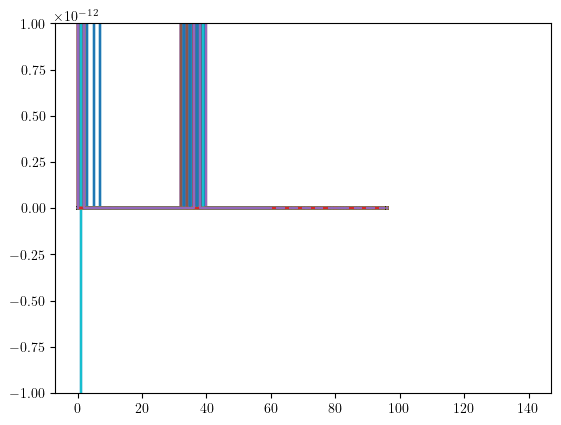

In [61]:

plt.plot(eddy)
plt.plot(madv, 'k-',label='3yr-mean adv')
plt.plot(np.mean(eddy, axis=1),'r--',label='3yr-mean eddy')
plt.plot(np.std(eddy, axis=1),'b:',label='3yr-std eddy')
plt.plot(-np.std(eddy, axis=1),'b:',label='3yr-std eddy')

plt.grid('on')
plt.legend()
plt.title('mean total advection (annual)')


Text(0.5, 1.0, 'mean total advection (annual)')

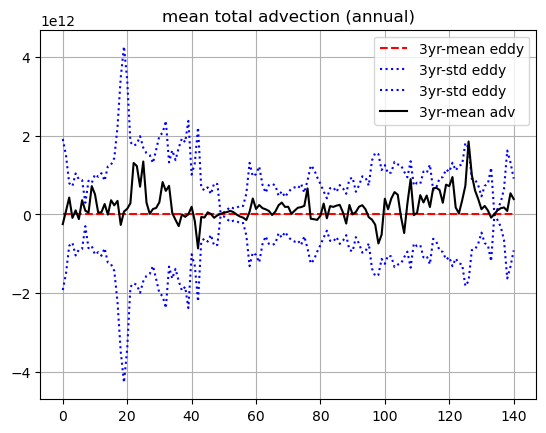

In [106]:

# plt.plot(madv, 'k-',label='3yr-mean adv')
plt.plot(np.mean(eddy, axis=1),'r--',label='3yr-mean eddy')
plt.plot(np.std(eddy, axis=1),'b:',label='3yr-std eddy')
plt.plot(-np.std(eddy, axis=1),'b:',label='3yr-std eddy')
plt.plot(madv, 'k-',label='3yr-mean adv')

# plt.plot(eddy.mean('ocean_time'), '-m',label='eddy avg')
plt.grid('on')
# plt.plot(w4a_hadv.isel(ocean_time=10),label='snapshot')
# plt.plot(w4a_hadv.isel(ocean_time=13),label='snapshot')|
plt.legend()
plt.title('mean total advection (annual)')

In [ ]:
plt.plot(np.mean(eddy[:,0:30], axis=1),'-',label='3yr-mean Jan eddy',color='red')
plt.plot(np.mean(eddy[:,31:60], axis=1),'-',label='3yr-mean Feb eddy',color='Orange')
plt.plot(np.mean(eddy[:,61:90], axis=1),'-',label='3yr-mean Mar eddy',color='Yellow')
plt.plot(np.mean(eddy[:,91:120], axis=1),'-',label='3yr-mean Apr eddy',color='Green')
plt.plot(np.mean(eddy[:,121:150], axis=1),'-',label='3yr-mean May eddy',color='Cyan')
plt.plot(np.mean(eddy[:,151:180], axis=1),'-',label='3yr-mean Jun eddy',color='Blue')
plt.plot(np.mean(eddy[:,181:210], axis=1),'-',label='3yr-mean Jul eddy',color='Purple')
plt.plot(np.mean(eddy[:,211:240], axis=1),'-',label='3yr-mean Aug eddy',color='Pink')
plt.plot(np.mean(eddy[:,241:270], axis=1),'-',label='3yr-mean Sep eddy',color='Brown')
plt.plot(np.mean(eddy[:,271:300], axis=1),'-',label='3yr-mean Oct eddy',color='Gray')
plt.plot(np.mean(eddy[:,301:330], axis=1),'-',label='3yr-mean Dec eddy',color='Olive')
plt.plot(np.mean(eddy[:,331:365], axis=1),'-',label='3yr-mean Dec eddy',color='Teal')

plt.grid('on')
# plt.plot(w4a_hadv.isel(ocean_time=10),label='snapshot')
# plt.plot(w4a_hadv.isel(ocean_time=13),label='snapshot')
plt.legend()
plt.title('mean total advection (annual)')



In [108]:
mhadv_is_yr10 = w4a_hadv_is.mean('ocean_time')
mhadv_is_yr11 = w4b_hadv_is.mean('ocean_time')
mhadv_is_yr12 = w4c_hadv_is.mean('ocean_time')
mvadv_is_yr10 = w4a_vadv_is.mean('ocean_time')
mvadv_is_yr11 = w4b_vadv_is.mean('ocean_time')
mvadv_is_yr12 = w4c_vadv_is.mean('ocean_time')

madv_is = np.divide(mhadv_is_yr10+mhadv_is_yr11+mhadv_is_yr12+mvadv_is_yr10+mvadv_is_yr11+mvadv_is_yr12,6)

# test calculating eddy component (daily):
eddy_is_yr10 = (w4a_hadv_is + w4a_vadv_is) - madv_is
eddy_is_yr11 = (w4b_hadv_is + w4b_vadv_is) - madv_is
eddy_is_yr12 = (w4c_hadv_is + w4c_vadv_is) - madv_is
eddy_is = eddy_is_yr10 + eddy_is_yr11 + eddy_is_yr12

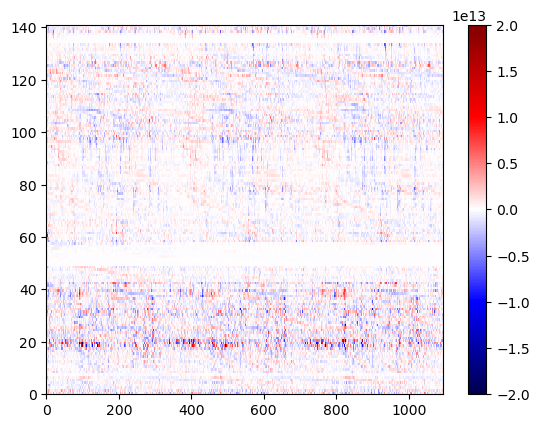

In [109]:
plt.pcolormesh(eddy, vmin=-20e12, vmax=20e12, cmap='seismic')
plt.colorbar()



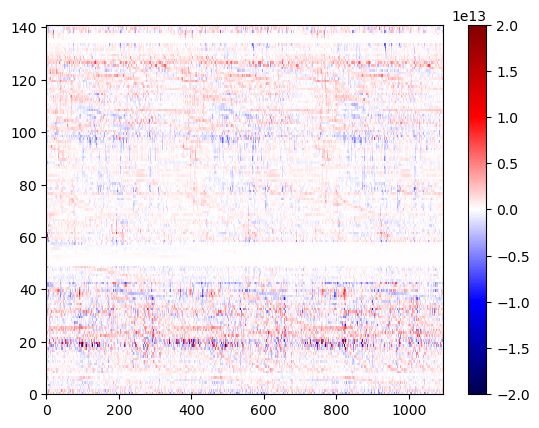

In [110]:
plt.pcolormesh((W4_hadv+W4_vadv), vmin=-20e12, vmax=20e12, cmap='seismic')
plt.colorbar()


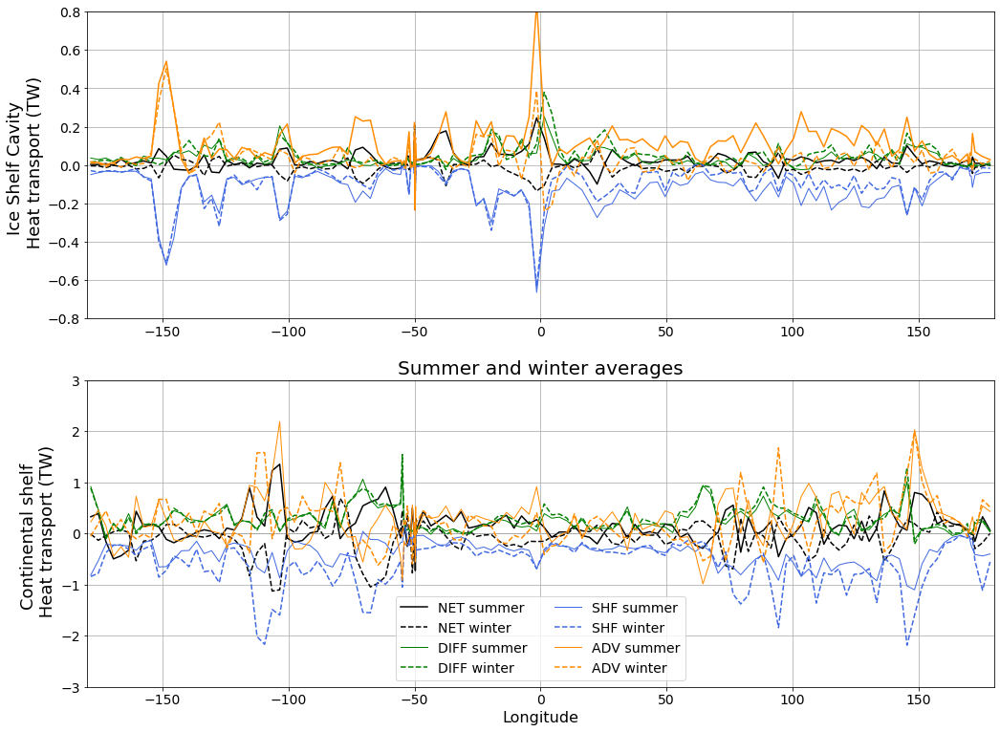

In [48]:

fig = plt.figure(figsize=(17,13))

# ax1 = fig.add_subplot(2,2,1)
# ax1.plot(w4_lon_bins,w4_net.mean('ocean_time')*0,'--',color='gray',linewidth=0.5)

# # ax1.plot(w4_lon_bins,w4_net.mean('ocean_time')*1e-12,'-k',label='Continental shelf',linewidth=2, alpha=1)
# # ax1.plot(w4_lon_bins,w4_net_is.mean('ocean_time')*1e-12,'--k',label='Ice shelf cavities',linewidth=2)
# # ax1.legend(loc='lower right')
# ax1.plot(w4_lon_bins,w4_net.mean('ocean_time')*1e-12,'-k',label='NET',linewidth=2, alpha=1)
# ax1.plot(w4_lon_bins,w4_hdiff.mean('ocean_time')*1e-12,color='green',label='DIFF', alpha=1)
# ax1.plot(w4_lon_bins,w4_vdiff.mean('ocean_time')*1e-12,color='royalblue',label='SHF', alpha=1)
# ax1.plot(w4_lon_bins,w4_hadv.mean('ocean_time')*1e-12,color='darkorange',label='ADV', alpha=1)
# # ax1.set_title('Continental shelf \n Annual average', fontsize=16)
# ax1.set_title('Annual average', fontsize=16)
# ax1.set_xlim(-180,180)
# ax1.set_ylim(-1.8,1.8)
# ax1.grid('off')
# ax1.set_ylabel('Heat flux convergence  (TW)', fontsize=14)

# ax1 = fig.add_subplot(2,2,2)

# ax1.plot(w4_lon_bins,w4_net_is.mean('ocean_time')*1e-12,'-k',label='NET',linewidth=1.5,)
# ax1.plot(w4_lon_bins,w4_hdiff_is.mean('ocean_time')*1e-12,'-',alpha=1,color='green',label='DIFF')
# ax1.plot(w4_lon_bins,w4_vdiff_is.mean('ocean_time')*1e-12,'-',alpha=1,color='royalblue',label='SHF')
# ax1.plot(w4_lon_bins,w4_hadv_is.mean('ocean_time')*1e-12,'-',alpha=1,color='darkorange',label='ADV')
# # ax1.set_title('Ice shelf cavity \n Annual average', fontsize=16)
# ax1.set_title('Annual average', fontsize=16)
# ax1.legend(loc='upper right')
# ax1.set_xlim(-180,180)
# ax1.set_ylim(-.6,.6)
# ax1.grid('off')
# ax1.set_ylabel('Heat flux convergence  (TW)', fontsize=14)

ax1 = fig.add_subplot(2,1,2)
ax1.plot(w4_lon_bins,w4_net_summer.mean('ocean_time')*1e-12,'-k',label='NET summer',linewidth=1.5)
ax1.plot(w4_lon_bins,w4_net.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--k',label='NET winter',linewidth=1.5)

ax1.plot(w4_lon_bins,w4_net.mean('ocean_time')*0,'--',color='gray',linewidth=0.5)
ax1.plot(w4_lon_bins,w4_hdiff_summer.mean('ocean_time')*1e-12,linewidth=1,color='green',label='DIFF summer', alpha=1)
ax1.plot(w4_lon_bins,w4_hdiff.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',color='green',label='DIFF winter', alpha=1)

ax1.plot(w4_lon_bins,w4_vdiff_summer.mean('ocean_time')*1e-12,linewidth=1,color='royalblue',label='SHF summer', alpha=1)
ax1.plot(w4_lon_bins,w4_vdiff.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',color='royalblue',label='SHF winter', alpha=1)

ax1.plot(w4_lon_bins,w4_hadv_summer.mean('ocean_time')*1e-12,linewidth=1,color='darkorange',label='ADV summer', alpha=1)
# ax1.plot(w4_lon_bins,w4_net_summer.mean('ocean_time')*1e-12,'-k',label='NET summer',linewidth=1.5)
ax1.plot(w4_lon_bins,w4_hadv.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',color='darkorange',label='ADV winter', alpha=1)

ax1.set_title('Summer and winter averages', fontsize=20)
ax1.set_xlim(-180,180)
ax1.set_ylim(-3,3)
ax1.grid('off')
ax1.set_ylabel('Continental shelf \n Heat transport (TW)',fontsize=18)
ax1.set_xlabel('Longitude', fontsize=16)
ax1.legend(ncol=2,loc='lower center',fontsize=14)
ax1.tick_params(axis='x',labelsize=14)
ax1.tick_params(axis='y',labelsize=14)

ax1 = fig.add_subplot(2,1,1)
ax1.plot(w4_lon_bins,w4_net_is_summer.mean('ocean_time')*1e-12,'-k',label='NET summer',linewidth=1.5)
ax1.plot(w4_lon_bins,w4_net_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--k',label='NET winter',linewidth=1.5)

ax1.plot(w4_lon_bins,w4_hdiff_is_summer.mean('ocean_time')*1e-12,'-',linewidth=1,alpha=1,color='green',label='DIFF summer')
ax1.plot(w4_lon_bins,w4_hdiff_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',alpha=1,color='green',label='DIFF winter')

ax1.plot(w4_lon_bins,w4_vdiff_is_summer.mean('ocean_time')*1e-12,'-',linewidth=1,alpha=1,color='royalblue',label='SHF summer')
ax1.plot(w4_lon_bins,w4_vdiff_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',alpha=1,color='royalblue',label='SHF winter')

ax1.plot(w4_lon_bins,w4_hadv_is_summer.mean('ocean_time')*1e-12,'-',linewidth=1.5,alpha=1,color='darkorange',label='ADV summer')
ax1.plot(w4_lon_bins,w4_hadv_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time')*1e-12,'--',linewidth=1.5,alpha=1,color='darkorange',label='ADV winter')
# ax1.set_title('Summer and winter averages', fontsize=16)
ax1.set_xlim(-180,180)
ax1.set_ylim(-.8,.8)
ax1.grid('off')
ax1.set_ylabel('Ice Shelf Cavity \n Heat transport (TW)',fontsize=18)
ax1.tick_params(axis='x',labelsize=14)
ax1.tick_params(axis='y',labelsize=14)

name_fig='waom4_lonbin_regional_OHB_wholeshelf_Figure2new.png'
plt.savefig(fig_path + name_fig, dpi=600, bbox_inches='tight')

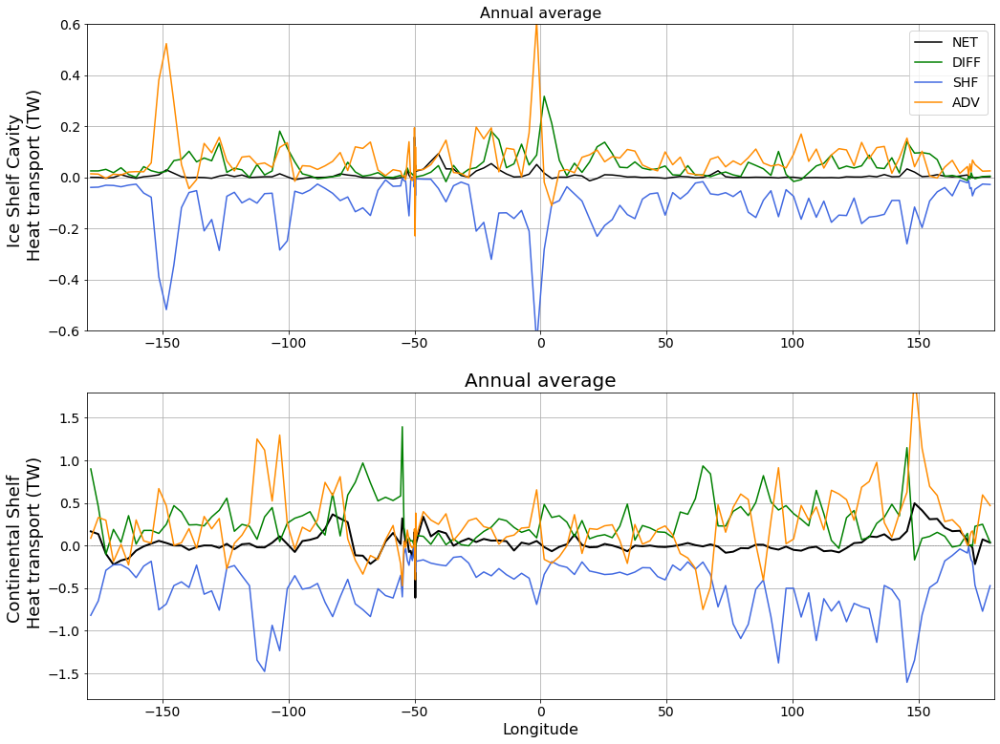

In [49]:
fig = plt.figure(figsize=(17,13))

ax1 = fig.add_subplot(2,1,2)
ax1.plot(w4_lon_bins,w4_net.mean('ocean_time')*0,'--',color='gray',linewidth=0.5)

ax1.plot(w4_lon_bins,w4_net.mean('ocean_time')*1e-12,'-k',label='NET',linewidth=2, alpha=1)
ax1.plot(w4_lon_bins,w4_hdiff.mean('ocean_time')*1e-12,color='green',label='DIFF', alpha=1)
ax1.plot(w4_lon_bins,w4_vdiff.mean('ocean_time')*1e-12,color='royalblue',label='SHF', alpha=1)
ax1.plot(w4_lon_bins,w4_hadv.mean('ocean_time')*1e-12,color='darkorange',label='ADV', alpha=1)
ax1.set_title('Annual average', fontsize=20)
ax1.set_xlim(-180,180)
ax1.set_ylim(-1.8,1.8)
ax1.grid('off')
ax1.set_ylabel('Continental Shelf \n Heat transport (TW)',fontsize=18)
ax1.set_xlabel('Longitude', fontsize=16)
ax1.tick_params(axis='x',labelsize=14)
ax1.tick_params(axis='y',labelsize=14)


ax1 = fig.add_subplot(2,1,1)

ax1.plot(w4_lon_bins,w4_net_is.mean('ocean_time')*1e-12,'-k',label='NET',linewidth=1.5,)
ax1.plot(w4_lon_bins,w4_hdiff_is.mean('ocean_time')*1e-12,'-',alpha=1,color='green',label='DIFF')
ax1.plot(w4_lon_bins,w4_vdiff_is.mean('ocean_time')*1e-12,'-',alpha=1,color='royalblue',label='SHF')
ax1.plot(w4_lon_bins,w4_hadv_is.mean('ocean_time')*1e-12,'-',alpha=1,color='darkorange',label='ADV')
# ax1.set_title('Ice shelf cavity \n Annual average', fontsize=16)
ax1.set_title('Annual average', fontsize=16)
ax1.legend(loc='upper right', fontsize=14)
ax1.set_xlim(-180,180)
ax1.set_ylim(-.6,.6)
ax1.grid('off')
ax1.set_ylabel('Ice Shelf Cavity \n Heat transport (TW)',fontsize=18)
ax1.tick_params(axis='x',labelsize=14)
ax1.tick_params(axis='y',labelsize=14)


name_fig='waom4_lonbin_regional_OHB_wholeshelf_Figure2_SM.png'
plt.savefig(fig_path + name_fig, dpi=600, bbox_inches='tight')

In [31]:

# # sustr/svstr # waom4

# Ustr = sustr.rename({'eta_u': 'eta','xi_u': 'xi'})*w4_mask_shelf[:,:-1]
# Vstr = svstr.rename({'eta_v': 'eta','xi_v': 'xi'})*w4_mask_shelf[:-1,:]

# Usqr = (Ustr*Ustr)
# Vsqr = (Vstr*Vstr)
# print(Usqr[:,:-1,:].shape, Vsqr[:,:,:-1].shape)
# WSmgn = np.sqrt(Usqr[:,:-1,:]+Vsqr[:,:,:-1])
# WSmgn

# # mask_LonBins_4km.rename({'eta_rho': 'eta','xi_rho': 'xi'})

# lon_bin_midpts = np.arange(-178.5,180,3)
# # define lat bin mid-points:
# lat_bin_midpts = np.arange(lon_bin_midpts[41],lon_bin_midpts[43],0.6667)
# # define lonlat
# lonlat_bin_midpts = np.empty((127))
# lonlat_bin_midpts[0:41] = lon_bin_midpts[0:41]
# lonlat_bin_midpts[41:50] = lat_bin_midpts
# lonlat_bin_midpts[50:] = lon_bin_midpts[43:]

# ## convert mask_LonBins_4km to dataArray:
# coordinatesC=dict(lon_bins=lonlat_bin_midpts, eta=temp_hdiff_4km.eta_rho, xi=temp_hdiff_4km.xi_rho)
# mask_LonBins_4km_xr = xr.DataArray(mask_LonBins_4km, coords = coordinatesC, dims = ['lon_bins','eta_rho','xi_rho'])

# mask_LonBins_4km_xr=mask_LonBins_4km_xr.rename({'eta_rho': 'eta','xi_rho': 'xi'})

# # define Wind Stress x mask_LonLat_Bins
# WS_masked = (mask_LonBins_4km_xr.isel(eta=slice(0,-1),xi=slice(0,-1))*WSmgn)

# files_path = '/g/data/gv90/fbd581/ROMS/postprocessing/WindStress/'
# WS_masked.to_netcdf(files_path + 'waom4_WS_masked_daily_lonlatBins.nc', mode='w', format="NETCDF4")

In [93]:
# # for ii in range(0,10):

#     sind = sind_subreg[ii]
#     eind = eind_subreg[ii]
    
#     fig = plt.figure(figsize=(12,10))
#     ax1 = fig.add_subplot(2,1,1, frameon=True)
#     ax1.plot(np.arange(0,365,1),w4_net.isel(lon_bins=slice(sind,eind)).sum('lon_bins')*0,'-0',color='gray',linewidth=0.5)

print(temp_4km_CF.shape,salt_4km_CF.shape, z_rho_4km_CF.shape)
print(lon_along_4km_CF.shape, lat_along_4km_CF.shape)

(365, 31, 9018) (365, 31, 9018) (365, 31, 9018)
(9018,) (9018,)


In [94]:
%%time 
# Now I need to get the T,S values for each subregion and make a TSdiagram:

salt_4km_CF.load()
temp_4km_CF.load()
z_rho_4km_CF.load()

CPU times: user 693 ms, sys: 2.45 s, total: 3.14 s
Wall time: 5.66 s


<xarray.Variable (ocean_time: 365, s_rho: 31, contour_index_array: 9018)>
array([[[ -264.86822578,  -266.87704394,  -216.09016005, ...,
         -1862.878163  , -1730.9784054 , -1587.08869116],
        [ -260.37740488,  -262.40654356,  -212.10334024, ...,
         -1852.3190415 , -1720.83442054, -1577.38571136],
        [ -255.23911573,  -257.2962218 ,  -207.64036157, ...,
         -1835.16352522, -1704.70555481, -1562.32583581],
        ...,
        [  -12.32483742,   -16.40019681,   -11.20809361, ...,
          -275.38257322,  -274.86573043,  -266.30897832],
        [   -7.97426487,   -12.06828838,    -7.32441475, ...,
          -266.25229933,  -266.01813293,  -257.76635778],
        [   -3.73194183,    -7.84335099,    -3.52034437, ...,
          -258.22486939,  -258.17114105,  -250.11935071]],

       [[ -264.86775121,  -266.87657163,  -216.08963161, ...,
         -1862.87818789, -1730.9784399 , -1587.08873048],
        [ -260.37593059,  -262.40507667,  -212.10170867, ...,
         -1852.31913014, -1720.83454206, -1577.38584822],
        [ -255.23649758,  -257.29361797,  -207.63749512, ...,
         -1835.16371743, -1704.70581469, -1562.32612406],
...
        [  -12.27188746,   -16.34769575,   -11.15473237, ...,
          -275.36385128,  -274.84295383,  -266.28092753],
        [   -7.92041038,   -12.01488697,    -7.27005136, ...,
          -266.23347   ,  -265.99521832,  -257.7381261 ],
        [   -3.67720531,    -7.78907145,    -3.46499935, ...,
          -258.20594564,  -258.14810402,  -250.0909571 ]],

       [[ -264.86780247,  -266.87662167,  -216.08969306, ...,
         -1862.87812635, -1730.97835451, -1587.08862412],
        [ -260.37608984,  -262.40523207,  -212.10189839, ...,
         -1852.31891095, -1720.83424129, -1577.38547798],
        [ -255.23678037,  -257.29389381,  -207.63782843, ...,
         -1835.16324211, -1704.70517146, -1562.32534427],
        ...,
        [  -12.27426657,   -16.34995241,   -11.15752894, ...,
          -275.36841983,  -274.84725365,  -266.28627011],
        [   -7.92283014,   -12.01718234,    -7.27290045, ...,
          -266.23806476,  -265.9995442 ,  -257.74350313],
        [   -3.6796647 ,    -7.79140457,    -3.46789989, ...,
          -258.21056343,  -258.15245301,  -250.09636497]]])

In [95]:
## TS diagram to choose isoypcnals:
# print(sigma_2_10km.shape, temp_10km.shape, salt_10km.shape)


# make grid for density contours
smin = 30 - (0.01 * 30)    #salt_ctrl_subregR.min - (0.01 * salt_ctrl_subregR.min)
smax = 36. + (0.01 * 36.)    #salt_ctrl_subregR.max + (0.01 * salt_ctrl_subregR.max)
tmin = -4. + (0.1 * -4.)       #temp_ctrl_subregR.min - (0.1 * temp_ctrl_subregR.max)
tmax = 5 + (0.1 * 5.)       #temp_ctrl_subregR.max + (0.1 * temp_ctrl_subregR.max)
print('tmin, tmax, smin, smax sizes=,', tmin, tmax, smin, smax)
# Calculate how many gridcells we need in the x and y dimensions
xdim = 30
ydim = 20
# Create empty grid of zeros
dens = np.zeros((ydim,xdim))
# Create temp and salt vectors of appropiate dimensions
ti = np.linspace(-4,5,ydim)
si = np.linspace(30,36,xdim)

Si, Ti = np.meshgrid(si, ti, sparse=False, indexing='ij')
# Loop to fill in grid with densities
for j in range(0,int(ydim)):
    for i in range(0, int(xdim)):
        dens[j,i]=gsw.rho(si[i],ti[j],2000) # sigma-2000
# Substract 1000 to convert to sigma-2
dens = dens - 1000

tmin, tmax, smin, smax sizes=, -4.4 5.5 29.7 36.36


0
0 0
1
1 0
2
2 0
3
3 0
4
4 0
5
0 1
6
1 1
7
2 1
8
3 1
9
4 1


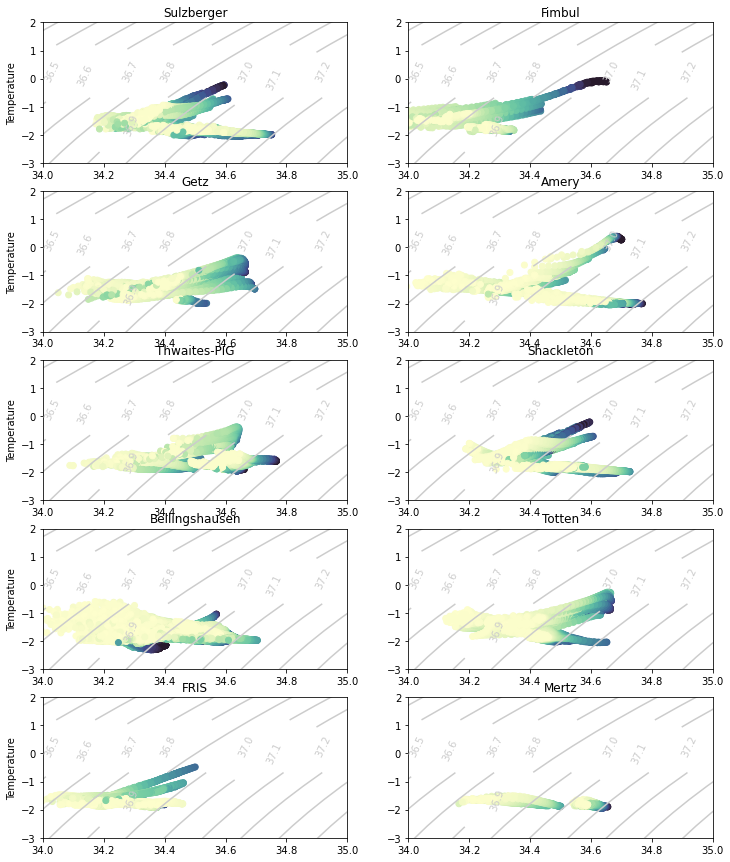

In [116]:
# Annual

fig, ax = plt.subplots(nrows=5, ncols=2, figsize = (12, 15))
for aa in range(0,5):
    for bb in range(0,2):
        CS1 = ax[aa,bb].contour(Si,Ti,dens.transpose(), levels=np.arange(35.5,38,.1),linestyles='solid', colors=[(.8,0.8,0.8)], linewidth=0.1)
        ax[aa,bb].clabel(CS1, CS1.levels, inline=True, fontsize=10)
        ax[aa,bb].set_xlim([34,35])
        ax[aa,bb].set_ylim([-3,2])
        if bb==0:
            ax[aa,bb].set_ylabel('Temperature')
        if aa==5:
            ax[aa,bb].set_xlabel('Salinity')

for rr in range(10):
    if rr==9:
        Stmp = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).mean('ocean_time')
        Ttmp = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).mean('ocean_time')
        Ztmp = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).mean('ocean_time')
    else:
        Stmp = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),int(indexes_subr[rr,1]))).mean('ocean_time')
        Ttmp = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),int(indexes_subr[rr,1]))).mean('ocean_time')
        Ztmp = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),int(indexes_subr[rr,1]))).mean('ocean_time')
    print(rr)
    if rr<=4:
        bb=0
        aa=rr
    else:
        bb=1
        aa=rr-5

    print(aa,bb)
    c = ax[aa,bb].scatter(Stmp,Ttmp,c=Ztmp, #,marker=".", #s=(72/fig.dpi)**2, 
                 label=names_subreg[rr], cmap=cmocean.cm.deep, vmin=0, vmax=900)
    ax[aa,bb].set_title(names_subreg[rr])

name_fig='waom4_TSiag_lonbin_subreg_annual.png'
plt.savefig(fig_path + name_fig, dpi=600, bbox_inches='tight', facecolor='white')

In [52]:


var1 = (w4_net_is.isel(ocean_time=slice(win1,win2)).mean('ocean_time'))

(-3.0, 2.0)

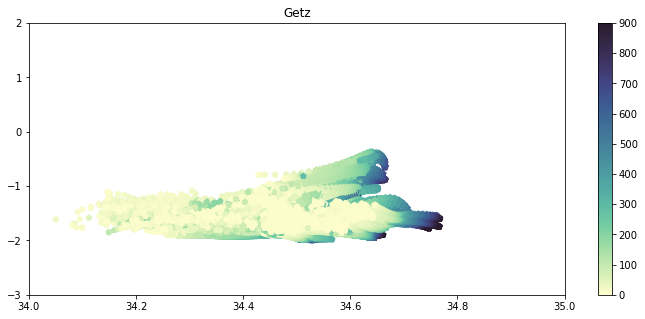

In [54]:
rr=1

Stmp = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).mean('ocean_time')
Ttmp = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).mean('ocean_time')
Ztmp = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).mean('ocean_time')

fig, ax = plt.subplots(nrows=1, ncols=1, figsize = (12, 5))
c = ax.scatter(Stmp,Ttmp,c=Ztmp,marker="p", #s=(72/fig.dpi)**2, 
             label=names_subreg[rr], cmap=cmocean.cm.deep, vmin=0, vmax=900)
ax.set_title(names_subreg[rr])
plt.colorbar(c)
plt.xlim([34,35])
plt.ylim([-3,2])

In [51]:
### TS diag seasonal (summer vs winter):
temp_4km_CF.shape

(365, 31, 9018)

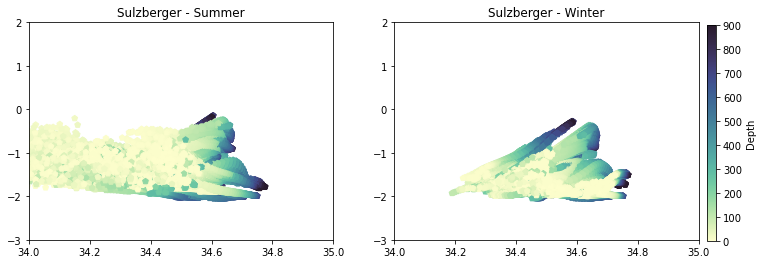

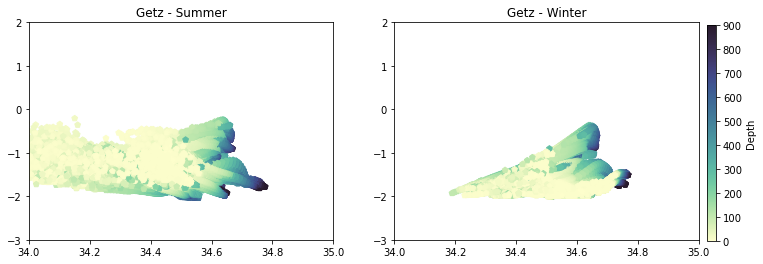

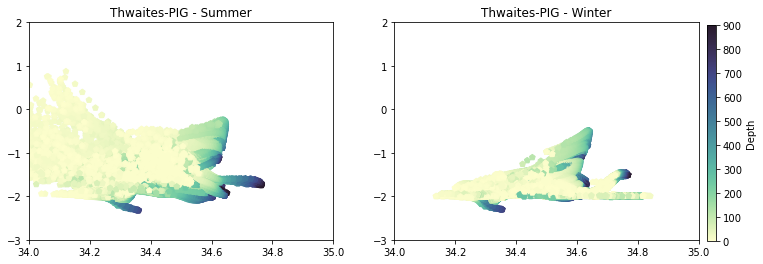

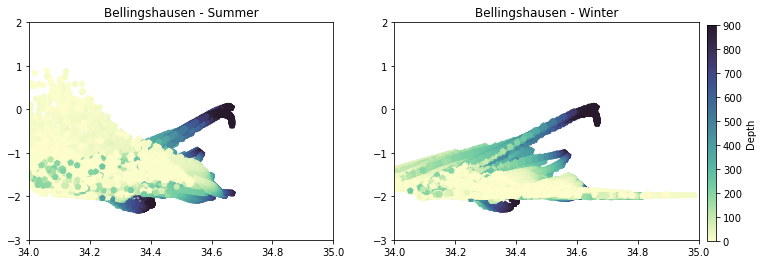

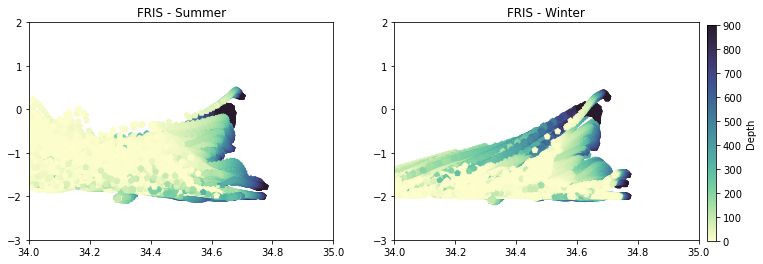

...

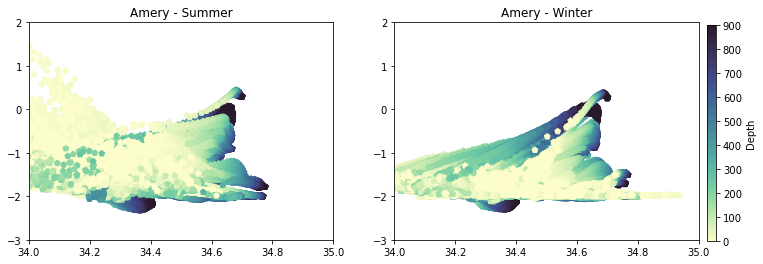

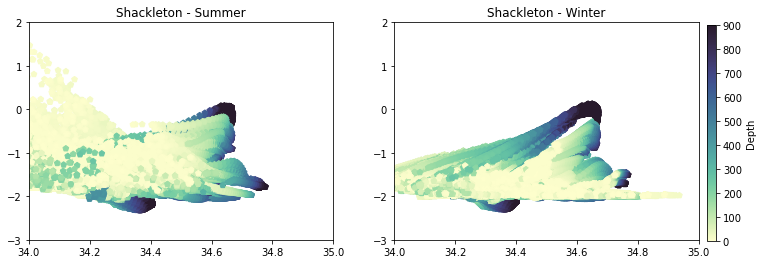

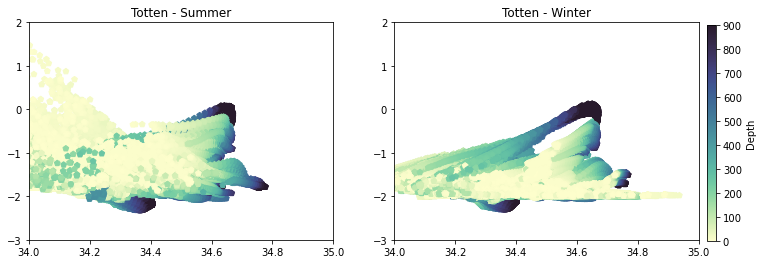

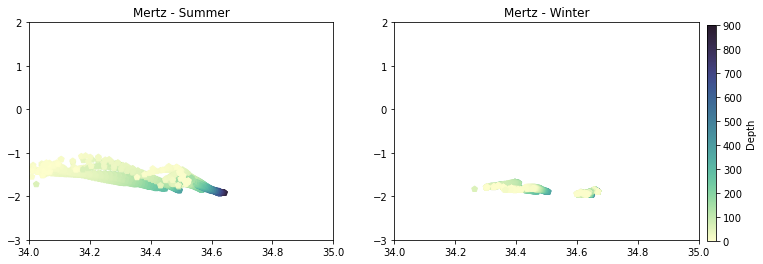

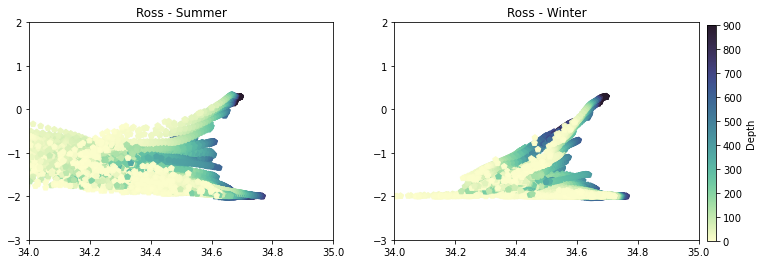

In [147]:
# plot Summer Vs Winter

for rr in range(11):  # give a region from 0-11
    
    # Stmp = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).mean('ocean_time')
    # Ttmp = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).mean('ocean_time')
    # Ztmp = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).mean('ocean_time')
    
    # define winter average:
    S_win = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(win1,win2)).mean('ocean_time')
    T_win = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(win1,win2)).mean('ocean_time')
    Z_win = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(win1,win2)).mean('ocean_time')
    
    # define summer average:
    S_sum_A = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(0,sum2))
    S_sum_B = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(sum1,-1))
    S_sum_A = xr.DataArray(S_sum_A)
    S_sum_B = xr.DataArray(S_sum_B)
    S_sum = xr.concat((S_sum_A,S_sum_B), 'ocean_time').mean('ocean_time')
    # -
    T_sum_A = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(0,sum2))
    T_sum_B = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(sum1,-1))
    T_sum_A = xr.DataArray(T_sum_A)
    T_sum_B = xr.DataArray(T_sum_B)
    T_sum = xr.concat((T_sum_A,T_sum_B), 'ocean_time').mean('ocean_time')
    # -
    Z_sum_A = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(0,sum2))
    Z_sum_B = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(sum1,-1))
    Z_sum_A = xr.DataArray(Z_sum_A)
    Z_sum_B = xr.DataArray(Z_sum_B)
    Z_sum = xr.concat((Z_sum_A,Z_sum_B), 'ocean_time').mean('ocean_time')
    
    
    # PLOT TS-DIAG SUMMER X WINTER
    fig, ax = plt.subplots(nrows=1, ncols=2, figsize = (12, 4))
    c = ax[1].scatter(S_win,T_win,c=Z_win,marker="p", #s=(72/fig.dpi)**2, 
                 label=names_subreg[rr], cmap=cmocean.cm.deep, vmin=0, vmax=900)
    ax[1].set_title(names_subreg[rr] + ' - Winter')
    ax[1].set_xlim([34,35])
    ax[1].set_ylim([-3,2])
    
    c = ax[0].scatter(S_sum,T_sum,c=Z_sum,marker="p", #s=(72/fig.dpi)**2, 
                 label=names_subreg[rr], cmap=cmocean.cm.deep, vmin=0, vmax=900)
    ax[0].set_title(names_subreg[rr] + ' - Summer')
    ax[0].set_xlim([34,35])
    ax[0].set_ylim([-3,2])

    cbar_ax1 = fig.add_axes([0.91, 0.12,  0.01, 0.75])
    fig.colorbar(c, cax=cbar_ax1, orientation='vertical')
    cbar_ax1.set_ylabel('Depth')#, labelpad=-35)



In [70]:
# print(len(dayofmonth))
dayofmonth[0]

slice(0, 32, None)

In [84]:
fig_path

'/g/data/hh5/tmp/access-om/fbd581/ROMS/postprocessing/figs/OHB_shelf/'

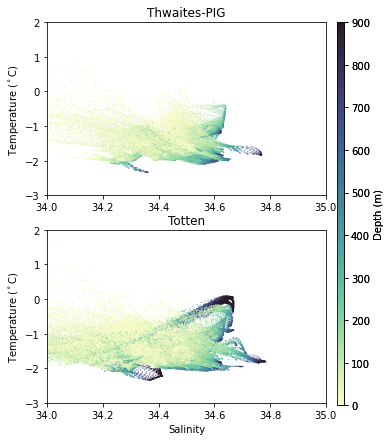

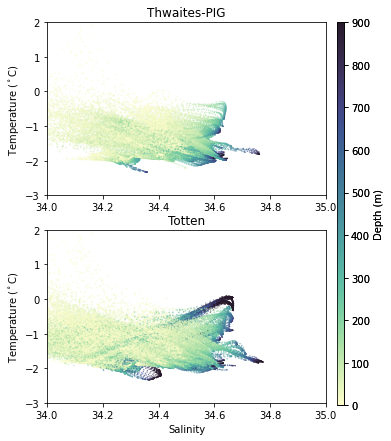

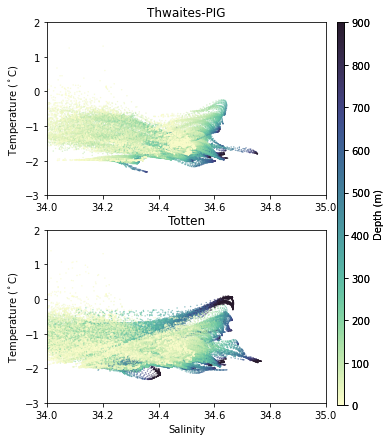

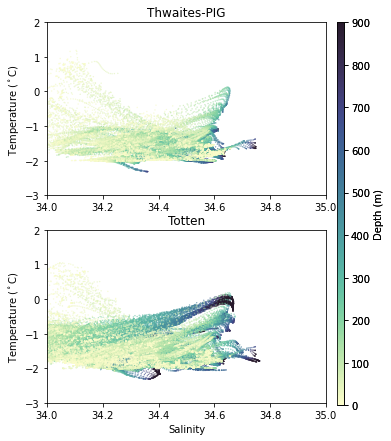

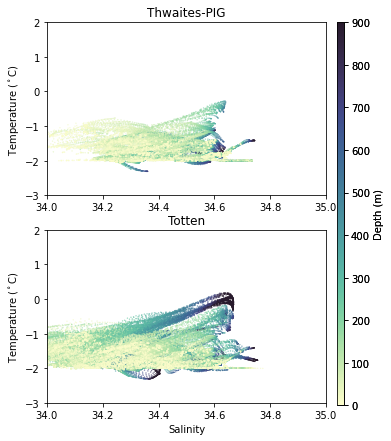

...

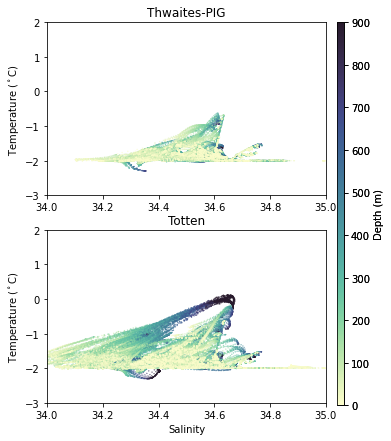

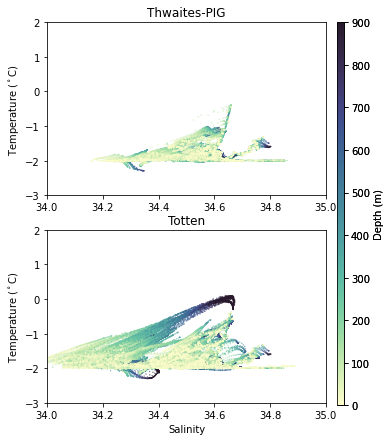

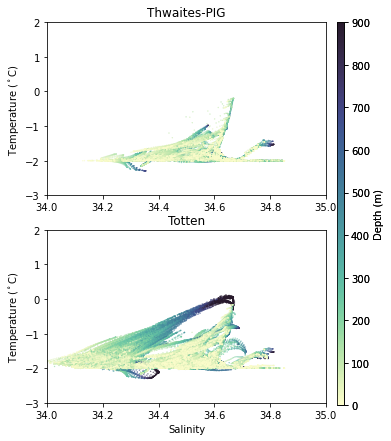

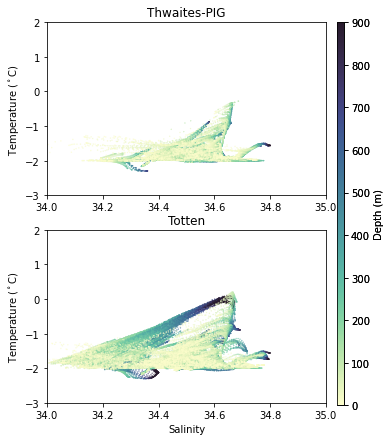

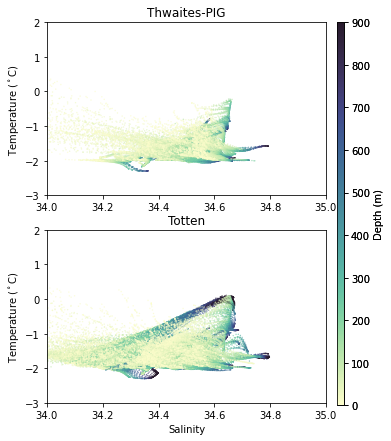

In [85]:
## Monthly TS with depth cbar for movies:

for mm in range(12):
    for rr in [2,8]:  # give a region from 0-11
    
        # define monthly average:
        S_tmp = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=dayofmonth[mm]).mean('ocean_time')
        T_tmp = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=dayofmonth[mm]).mean('ocean_time')
        Z_tmp = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=dayofmonth[mm]).mean('ocean_time')
        
        if rr==2:
            # PLOT TS-DIAG SUMMER X WINTER
            fig, ax = plt.subplots(nrows=2, ncols=1, figsize = (5, 7))
        
            c = ax[0].scatter(S_tmp,T_tmp,c=Z_tmp, s=(22/fig.dpi)**2, 
                            marker="o", cmap=cmocean.cm.deep, vmin=0, vmax=900)
            ax[0].set_title(names_subreg[rr])
            ax[0].set_xlim([34,35])
            ax[0].set_ylim([-3,2])
            # ax[0].legend()
            ax[0].set_ylabel('Temperature ($^\circ$C)')

        
        else:
            c = ax[1].scatter(S_tmp,T_tmp,c=Z_tmp, s=(22/fig.dpi)**2, 
                            marker="o", cmap=cmocean.cm.deep, vmin=0, vmax=900)
            ax[1].set_title(names_subreg[rr])
            ax[1].set_xlim([34,35])
            ax[1].set_ylim([-3,2])
            ax[1].set_xlabel('Salinity')
            ax[1].set_ylabel('Temperature ($^\circ$C)')
    
        cbar_ax1 = fig.add_axes([0.93, 0.12,  0.02, 0.76])
        fig.colorbar(c, cax=cbar_ax1, orientation='vertical')
        cbar_ax1.set_ylabel('Depth (m)')#, labelpad=-35)
    
    name_fig='waom4_TSiag_TottenXPIG_month=' + str(mm) + '.png'
    plt.savefig(fig_path + name_fig, dpi=600, bbox_inches='tight', facecolor='white')

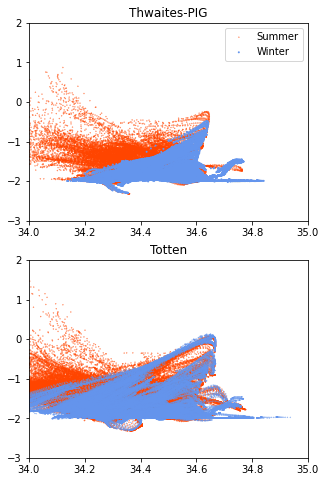

In [57]:
## Figure for paper: Totten x Thwaites, Summer (blue dots) vs summer (red crosses):

for rr in [2,8]:  # give a region from 0-11
    
    # define winter average:
    S_win = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(win1,win2)).mean('ocean_time')
    T_win = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(win1,win2)).mean('ocean_time')
    Z_win = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(win1,win2)).mean('ocean_time')
    
    # define summer average:
    S_sum_A = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(0,sum2))
    S_sum_B = salt_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(sum1,-1))
    S_sum_A = xr.DataArray(S_sum_A)
    S_sum_B = xr.DataArray(S_sum_B)
    S_sum = xr.concat((S_sum_A,S_sum_B), 'ocean_time').mean('ocean_time')
    # -
    T_sum_A = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(0,sum2))
    T_sum_B = temp_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(sum1,-1))
    T_sum_A = xr.DataArray(T_sum_A)
    T_sum_B = xr.DataArray(T_sum_B)
    T_sum = xr.concat((T_sum_A,T_sum_B), 'ocean_time').mean('ocean_time')
    # -
    Z_sum_A = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(0,sum2))
    Z_sum_B = -z_rho_4km_CF.isel(contour_index_array=slice(int(indexes_subr[rr,0]),-1)).isel(contour_index_array=slice(0,int(indexes_subr[rr,1]))).isel(ocean_time=slice(sum1,-1))
    Z_sum_A = xr.DataArray(Z_sum_A)
    Z_sum_B = xr.DataArray(Z_sum_B)
    Z_sum = xr.concat((Z_sum_A,Z_sum_B), 'ocean_time').mean('ocean_time')
    
    if rr==2:
        # PLOT TS-DIAG SUMMER X WINTER
        fig, ax = plt.subplots(nrows=2, ncols=1, figsize = (5, 8))
    
        c = ax[0].scatter(S_sum,T_sum,marker="o", s=(22/fig.dpi)**2, 
                     facecolors='none', edgecolors='orangered', label='Summer') 
        c = ax[0].scatter(S_win,T_win,marker="o", s=(72/fig.dpi)**2, 
                     facecolors='none', edgecolor='cornflowerblue', label='Winter')
        ax[0].set_title(names_subreg[rr])
        ax[0].set_xlim([34,35])
        ax[0].set_ylim([-3,2])
        ax[0].legend()
    
    else:
        c = ax[1].scatter(S_sum,T_sum,marker="o", s=(22/fig.dpi)**2, 
                     facecolors='none', edgecolors='orangered') # cmap=cmocean.cm.deep, vmin=0, vmax=900)
        c = ax[1].scatter(S_win,T_win,marker="o", s=(22/fig.dpi)**2, 
                     facecolors='none', edgecolor='cornflowerblue')#cmap=cmocean.cm.deep, vmin=0, vmax=900)
        ax[1].set_title(names_subreg[rr])
        ax[1].set_xlim([34,35])
        ax[1].set_ylim([-3,2])

    # cbar_ax1 = fig.add_axes([0.91, 0.12,  0.01, 0.75])
    # fig.colorbar(c, cax=cbar_ax1, orientation='vertical')
    # cbar_ax1.set_ylabel('Depth')#, labelpad=-35)
    
name_fig='waom4_TSiag_TottenXPIG.png'
plt.savefig(fig_path + name_fig, dpi=600, bbox_inches='tight', facecolor='white')

In [ ]:
plt.pcolormesh(shflux_4km[7,:,:])
plt.colorbar()

#### section to test volume-integrating and save in a netcdf file

In [80]:
files_path + "WAOM10_OHB_lonbins_temp_hadv_vint_daily"

'/g/data/hh5/tmp/access-om/fbd581/ROMS/postprocessing/cross_contour_tmp/WAOM10_OHB_lonbins_temp_hadv_vint_daily'

In [81]:
%%time

tlen=365
# heat tendency due to horizontal advection:
temp_hadv_int = np.empty((tlen))
temp_hadv_vol = np.empty(np.squeeze(temp_hadv[:,0,:,:]).shape)
for mm in np.arange(0,tlen):
# - multplying by dz:
    temp_hadv_dz = temp_hadv[mm,:]*dz[mm,:]
    temp_hadv_vint = np.nansum(temp_hadv_dz, axis=0)
    temp_hadv_vint_masked =  ma.masked_where(condition1, temp_hadv_vint)
    temp_hadv_vol[mm,:] = temp_hadv_vint_masked*area
    temp_hadv_int[mm] = np.nansum(np.nansum(temp_hadv_vol[mm,:],axis=1), axis=0)*Cp*rho0


CPU times: user 3min 14s, sys: 2min 23s, total: 5min 38s
Wall time: 8min 48s


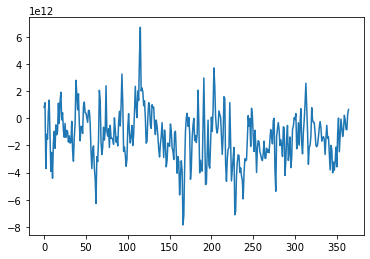

In [82]:
plt.plot(temp_hadv_int)

In [83]:
lon_bin_midpts = np.arange(-178.5,180,3)


In [84]:
temp_hadv_int.shape

(365,)

In [85]:
# saving into a netcdf file:
months=np.arange(0,365)*(1/30.41667)

coordinatesC=dict(ocean_time=months)
temp_hadv_int_xr = xr.DataArray(temp_hadv_int, coords = coordinatesC, dims = ['ocean_time'])

# for py file:
# lon_bin_limits = np.arange(-177,180,3)
# lon_bin_midpts = np.arange(-178.5,180,3)
# coordinatesC=dict(ocean_time=months, lon_bins=lon_bin_midpts)
# temp_hadv_int_xr = xr.DataArray(temp_hadv_int, coords = coordinatesC, dims = ['ocean_time','lon_bins'])

files_path = '/g/data/gv90/fbd581/ROMS/postprocessing/cross_contour_tmp/'
temp_hadv_int_xr.to_netcdf(files_path + 'WAOM10_OHB_1lonbin_temp_hadv_vint_daily', mode='w', format="NETCDF4")


In [86]:
temp_hadv

<xarray.DataArray 'temp_hadv' (ocean_time: 365, s_rho: 31, eta_rho: 560,
                               xi_rho: 630)>
dask.array<concatenate, shape=(365, 31, 560, 630), dtype=float32, chunksize=(5, 31, 280, 630), chunktype=numpy.ndarray>
Coordinates:
  * s_rho       (s_rho) float64 -0.9839 -0.9516 -0.9194 ... -0.04839 -0.01613
    x_rho       (eta_rho, xi_rho) float64 dask.array<chunksize=(560, 630), meta=np.ndarray>
    y_rho       (eta_rho, xi_rho) float64 dask.array<chunksize=(560, 630), meta=np.ndarray>
  * ocean_time  (ocean_time) float64 5.992e+08 5.993e+08 ... 6.306e+08 6.307e+08
Dimensions without coordinates: eta_rho, xi_rho
Attributes:
    long_name:  potential temperature, horizontal advection term
    units:      Celsius second-1
    time:       ocean_time
    field:      temp_hadv, scalar, series

In [87]:
mask_LonBins

<xarray.Variable (time: 120, y: 560, x: 630)>
[42336000 values with dtype=float64]

In [88]:
## example for vert.+horz. integral:

# %%time
# # 4. heat tendency due to horizontal advection:
# temp_hadv_int = np.empty((tlen))
# temp_hadv_vol = np.empty(np.squeeze(temp_hadv[:,0,:,:]).shape)
# for mm in np.arange(0,tlen):
# # - multplying by dz:
#     temp_hadv_dz = temp_hadv[mm,:]*dz[mm,:]
#     temp_hadv_vint = np.nansum(temp_hadv_dz, axis=0)
#     temp_hadv_vint_masked =  ma.masked_where(combined_condition, temp_hadv_vint)
#     temp_hadv_vol[mm,:] = temp_hadv_vint_masked*area
#     temp_hadv_int[mm] = np.nansum(np.nansum(temp_hadv_vol[mm,:],axis=1), axis=0)*Cp*rho0
